<a href="https://colab.research.google.com/github/Tefera22/Algeria_Omdena-/blob/main/Mini_Group_project___Beer_rating_prediction26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini Project: Predicting Beer Rating
   **Course -Advanced Machine Learning **ECE 5400 – HW1**

**Group Members**

1.   **Tefera Shibeshi**
2.    **Sebastian Delft**



**Goal:** predict the overall rating of a beer review (`review/overall`, 1–5 stars) from features of the beer, the user and the review.

Since the rating is a **number**, this is a **regression** problem. We compare the three regression algorithms from class:

| # | Algorithm | Role in this project |
|---|-----------|----------------------|
| 1 | Linear Regression (LR) | simple, interpretable baseline |
| 2 | Decision Tree (DT) | non-linear, rule-based model |
| 3 | Neural Network (NN) | flexible non-linear model |

Data split: **80 % train / 20 % test**. Metrics: **MAE, MSE, RMSE, MAPE** (lower is better for all four).

In [ ]:
# all the libraries we need
import os
import json
import ast
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

# sharper figures in Colab (retina = 2x resolution)
%config InlineBackend.figure_format = "retina"
plt.rcParams["figure.dpi"] = 100

## 1. Load the dataset

In [ ]:
import os

url = "http://www.ece.villanova.edu/~xjiao/course/ECE5400/dataset/beer_50000.json"

# the server blocks python's default user-agent (that's the 403 Forbidden),
# so we pretend to be a normal browser
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36"}

raw = None
for u in [url, url.replace("http://", "https://")]:
    try:
        req = urllib.request.Request(u, headers=headers)
        raw = urllib.request.urlopen(req, timeout=60).read().decode("utf-8")
        print("downloaded from", u)
        break
    except Exception as e:
        print("couldn't download from", u, "->", e)

# plan B: if the site still says no, download the file in your browser
# and upload it here
if raw is None:
    if not os.path.exists("beer_50000.json"):
        from google.colab import files
        print("please upload beer_50000.json")
        files.upload()
    raw = open("beer_50000.json", encoding="utf-8").read()

# the file is one review per line. some versions of this dataset are written as
# python dicts (single quotes) instead of strict json, so we try json first and
# fall back to ast.literal_eval if that fails
data = []
if raw.lstrip().startswith("["):
    data = json.loads(raw)
else:
    for line in raw.splitlines():
        line = line.strip()
        if not line:
            continue
        try:
            data.append(json.loads(line))
        except json.JSONDecodeError:
            data.append(ast.literal_eval(line))

print("number of reviews:", len(data))
print("one example review:")
data[0]

couldn't download from http://www.ece.villanova.edu/~xjiao/course/ECE5400/dataset/beer_50000.json -> HTTP Error 401: Unauthorized
downloaded from https://www.ece.villanova.edu/~xjiao/course/ECE5400/dataset/beer_50000.json
number of reviews: 50000
one example review:


{'review/appearance': 2.5,
 'beer/style': 'Hefeweizen',
 'review/palate': 1.5,
 'review/taste': 1.5,
 'beer/name': 'Sausa Weizen',
 'review/timeUnix': 1234817823,
 'beer/ABV': 5.0,
 'beer/beerId': '47986',
 'beer/brewerId': '10325',
 'review/timeStruct': {'isdst': 0,
  'mday': 16,
  'hour': 20,
  'min': 57,
  'sec': 3,
  'mon': 2,
  'year': 2009,
  'yday': 47,
  'wday': 0},
 'review/overall': 1.5,
 'review/text': 'A lot of foam. But a lot.\tIn the smell some banana, and then lactic and tart. Not a good start.\tQuite dark orange in color, with a lively carbonation (now visible, under the foam).\tAgain tending to lactic sourness.\tSame for the taste. With some yeast and banana.',
 'user/profileName': 'stcules',
 'review/aroma': 2.0}

(49997, 18)
count    49997.000000
mean         3.888943
std          0.701114
min          1.000000
25%          3.500000
50%          4.000000
75%          4.500000
max          5.000000
Name: review/overall, dtype: float64


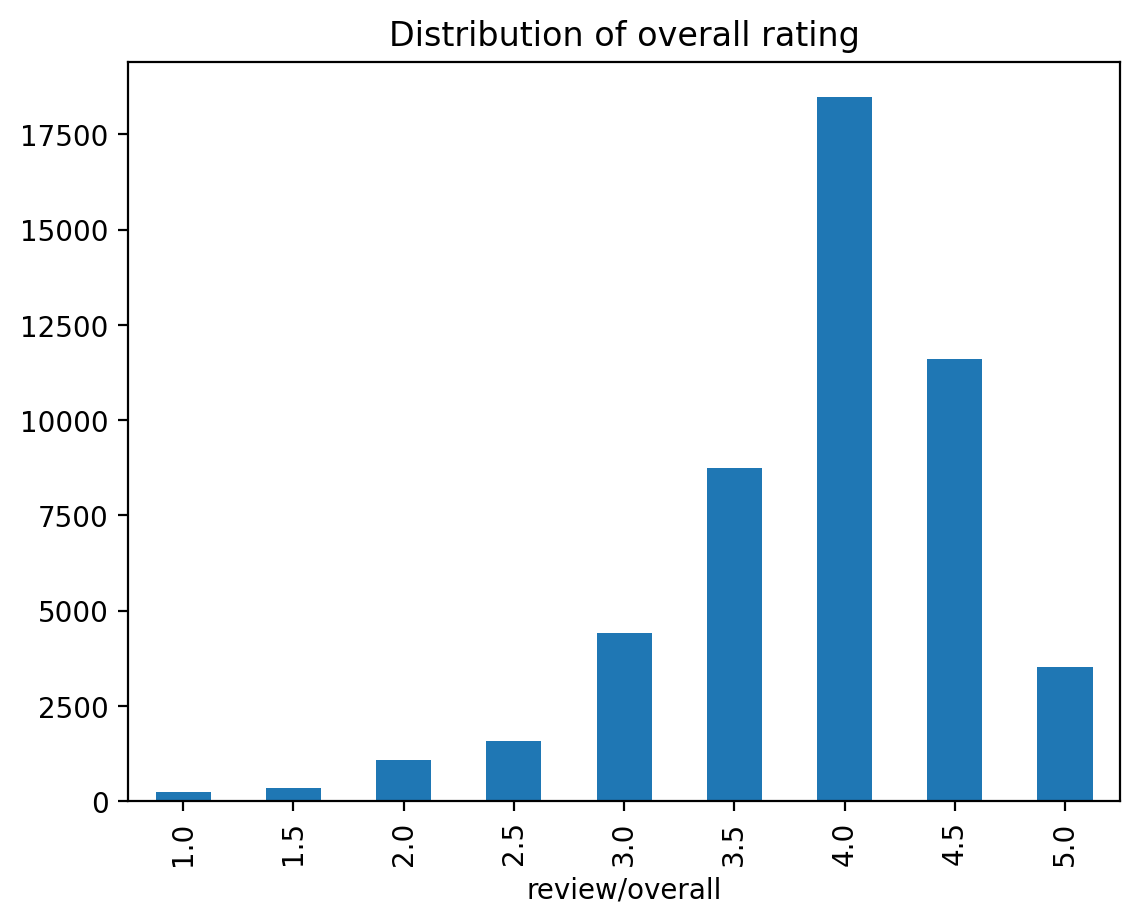

In [ ]:
df = pd.DataFrame(data)

# just in case there are any 0 ratings - MAPE divides by the true value so 0 would break it
df = df[df["review/overall"] > 0].reset_index(drop=True)

print(df.shape)
print(df["review/overall"].describe())
df["review/overall"].value_counts().sort_index().plot(kind="bar", title="Distribution of overall rating")
plt.show()

## 2. Build the feature vectors

| Group | Features |
|-------|----------|
| Beer | ABV, beer style (top 15 styles one-hot encoded, the rest = "Other") |
| Review | aroma, appearance, palate and taste scores, review length (words), year of the review |
| User | age in years, gender (male / female / unknown) |

**Label:** `review/overall`

In [ ]:
def col(name):
    # some fields (like gender / age) are missing for a lot of users,
    # so return NaNs if the column doesn't exist at all
    return df[name] if name in df.columns else pd.Series(np.nan, index=df.index)

X = pd.DataFrame(index=df.index)

# beer features
X["abv"] = pd.to_numeric(col("beer/ABV"), errors="coerce")

# the sub-scores the reviewer gave
for c in ["aroma", "appearance", "palate", "taste"]:
    X[c] = pd.to_numeric(col("review/" + c), errors="coerce")

# review text length (number of words)
X["review_len"] = col("review/text").fillna("").astype(str).str.split().str.len()

# year the review was written
X["year"] = pd.to_datetime(col("review/timeUnix"), unit="s", errors="coerce").dt.year

# user age in years (lots of users didn't give their birthday)
X["age"] = pd.to_numeric(col("user/ageInSeconds"), errors="coerce") / (365.25 * 24 * 3600)
X["age_missing"] = X["age"].isna().astype(int)

# gender -> one-hot
gender = col("user/gender").fillna("Unknown")
X["is_male"] = (gender == "Male").astype(int)
X["is_female"] = (gender == "Female").astype(int)

# beer style -> keep the 15 most common, lump the rest together
# (drop_first avoids one redundant column, which keeps the linear regression weights clean)
style = col("beer/style").fillna("Other")
top_styles = style.value_counts().index[:15]
style = style.where(style.isin(top_styles), "Other")
X = pd.concat([X, pd.get_dummies(style, prefix="style", drop_first=True).astype(int)], axis=1)

y = df["review/overall"].astype(float).values

print("feature matrix shape:", X.shape)
X.head()

feature matrix shape: (49997, 26)


,abv,aroma,appearance,palate,taste,review_len,year,age,age_missing,is_male,...,style_Czech Pilsener,style_Doppelbock,style_English Pale Ale,style_Fruit / Vegetable Beer,style_Old Ale,style_Other,style_Rauchbier,style_Russian Imperial Stout,style_Rye Beer,style_Scotch Ale / Wee Heavy
0,5.0,2.0,2.5,1.5,1.5,49,2009,NaN,1,0,...,0,0,0,0,0,1,0,0,0,0
1,6.2,2.5,3.0,3.0,3.0,61,2009,NaN,1,0,...,0,0,0,0,0,1,0,0,0,0
2,6.5,2.5,3.0,3.0,3.0,69,2009,NaN,1,0,...,0,0,0,0,0,1,0,0,0,0
3,5.0,3.0,3.5,2.5,3.0,74,2009,NaN,1,0,...,0,0,0,0,0,1,0,0,0,0
4,7.7,4.5,4.0,4.0,4.5,201,2010,113.488258,0,1,...,0,0,0,0,0,0,0,0,0,0


## 3. Train / test split (80 / 20)

In [ ]:
def split_and_fill(X, y, seed):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)

    # fill missing values with the TRAINING median only, so nothing from the
    # test set leaks into training
    # (the extra .fillna(0) covers a column that's completely empty, where the median is NaN too)
    medians = X_train.median()
    X_train = X_train.fillna(medians).fillna(0)
    X_test = X_test.fillna(medians).fillna(0)
    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = split_and_fill(X, y, seed=42)
print("train:", X_train.shape, " test:", X_test.shape)

train: (39997, 26)  test: (10000, 26)


### Helper functions

`evaluate()` computes the four metrics, and `show_model_results()` prints them and shows how the
predictions compare with the actual ratings for one model. We use the same helpers for every algorithm so the results are comparable.

| Metric | Meaning |
|--------|---------|
| **MAE** | average size of the error, in rating points |
| **MSE** | average squared error – big mistakes count much more |
| **RMSE** | square root of MSE, back in rating points |
| **MAPE** | average error as a % of the true rating |

In [ ]:
def evaluate(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAPE (%)": mean_absolute_percentage_error(y_true, y_pred) * 100,
    }


def show_model_results(name, y_true, y_pred, n_examples=10):
    m = evaluate(y_true, y_pred)
    within = np.mean(np.abs(y_true - y_pred) <= 0.5) * 100

    print(f"===== {name}: test set results =====")
    for k, v in m.items():
        print(f"  {k:9s} {v:.4f}")
    print(f"  {within:.1f}% of test reviews are predicted within ±0.5 of the actual rating")

    # a few actual vs predicted examples
    ex = pd.DataFrame({"Actual": y_true[:n_examples], "Predicted": np.round(y_pred[:n_examples], 2)})
    ex["Error (pred - actual)"] = (ex["Predicted"] - ex["Actual"]).round(2)
    display(ex)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # left: predicted vs actual. jitter on x because the true ratings only take a few values
    jitter = np.random.default_rng(0).uniform(-0.15, 0.15, len(y_true))
    axes[0].scatter(y_true + jitter, y_pred, s=3, alpha=0.15)
    axes[0].plot([1, 5], [1, 5], "r--", label="perfect prediction")
    axes[0].set_xlabel("Actual rating")
    axes[0].set_ylabel("Predicted rating")
    axes[0].set_title(f"{name}: predicted vs actual")
    axes[0].legend()

    # right: how the errors are spread out
    axes[1].hist(y_pred - y_true, bins=40, color="tab:orange", edgecolor="white")
    axes[1].axvline(0, color="r", linestyle="--")
    axes[1].set_xlabel("Error (predicted - actual)")
    axes[1].set_ylabel("Number of reviews")
    axes[1].set_title(f"{name}: error distribution")

    plt.tight_layout()
    plt.show()
    return m


# we collect every model's results here for the final comparison
results, predictions, models = {}, {}, {}

# baseline: always guess the average training rating.
# any useful model has to beat this
predictions["Baseline (mean)"] = np.full(len(y_test), y_train.mean())
results["Baseline (mean)"] = evaluate(y_test, predictions["Baseline (mean)"])
print("Baseline:", {k: round(v, 4) for k, v in results["Baseline (mean)"].items()})

Baseline: {'MAE': 0.5208, 'MSE': 0.4979, 'RMSE': np.float64(0.7056), 'MAPE (%)': 16.8161}


---
## Our approach – workflow and knowledge graph

Before implementing the algorithms, the two figures below summarize **how** we approach the problem.

**Figure 1 – Workflow.** A swimlane flowchart: each colored lane is one stage of the project, and the arrows show how the data moves from stage to stage.
1. **Data** – 50,000 beer reviews in JSON format.
2. **Preprocess** – download, parse each line, remove invalid ratings.
3. **Features** – build three groups of features: beer (ABV, style), review (sub-scores, text length, year) and user (age, gender).
4. **Split** – 80 % training / 20 % testing with `train_test_split`; missing values are filled with medians from the training set only, so the test set stays completely unseen.
5. **Models** – train Linear Regression, a Decision Tree and a Neural Network on the same training data.
6. **Evaluate** – compare predicted vs actual ratings on the test set with MAE, MSE, RMSE and MAPE.
7. **Compare** – tables, charts, a mean-rating baseline and 5 repeated random splits.
8. **Result** – the best algorithm and its final MAE / MAPE.

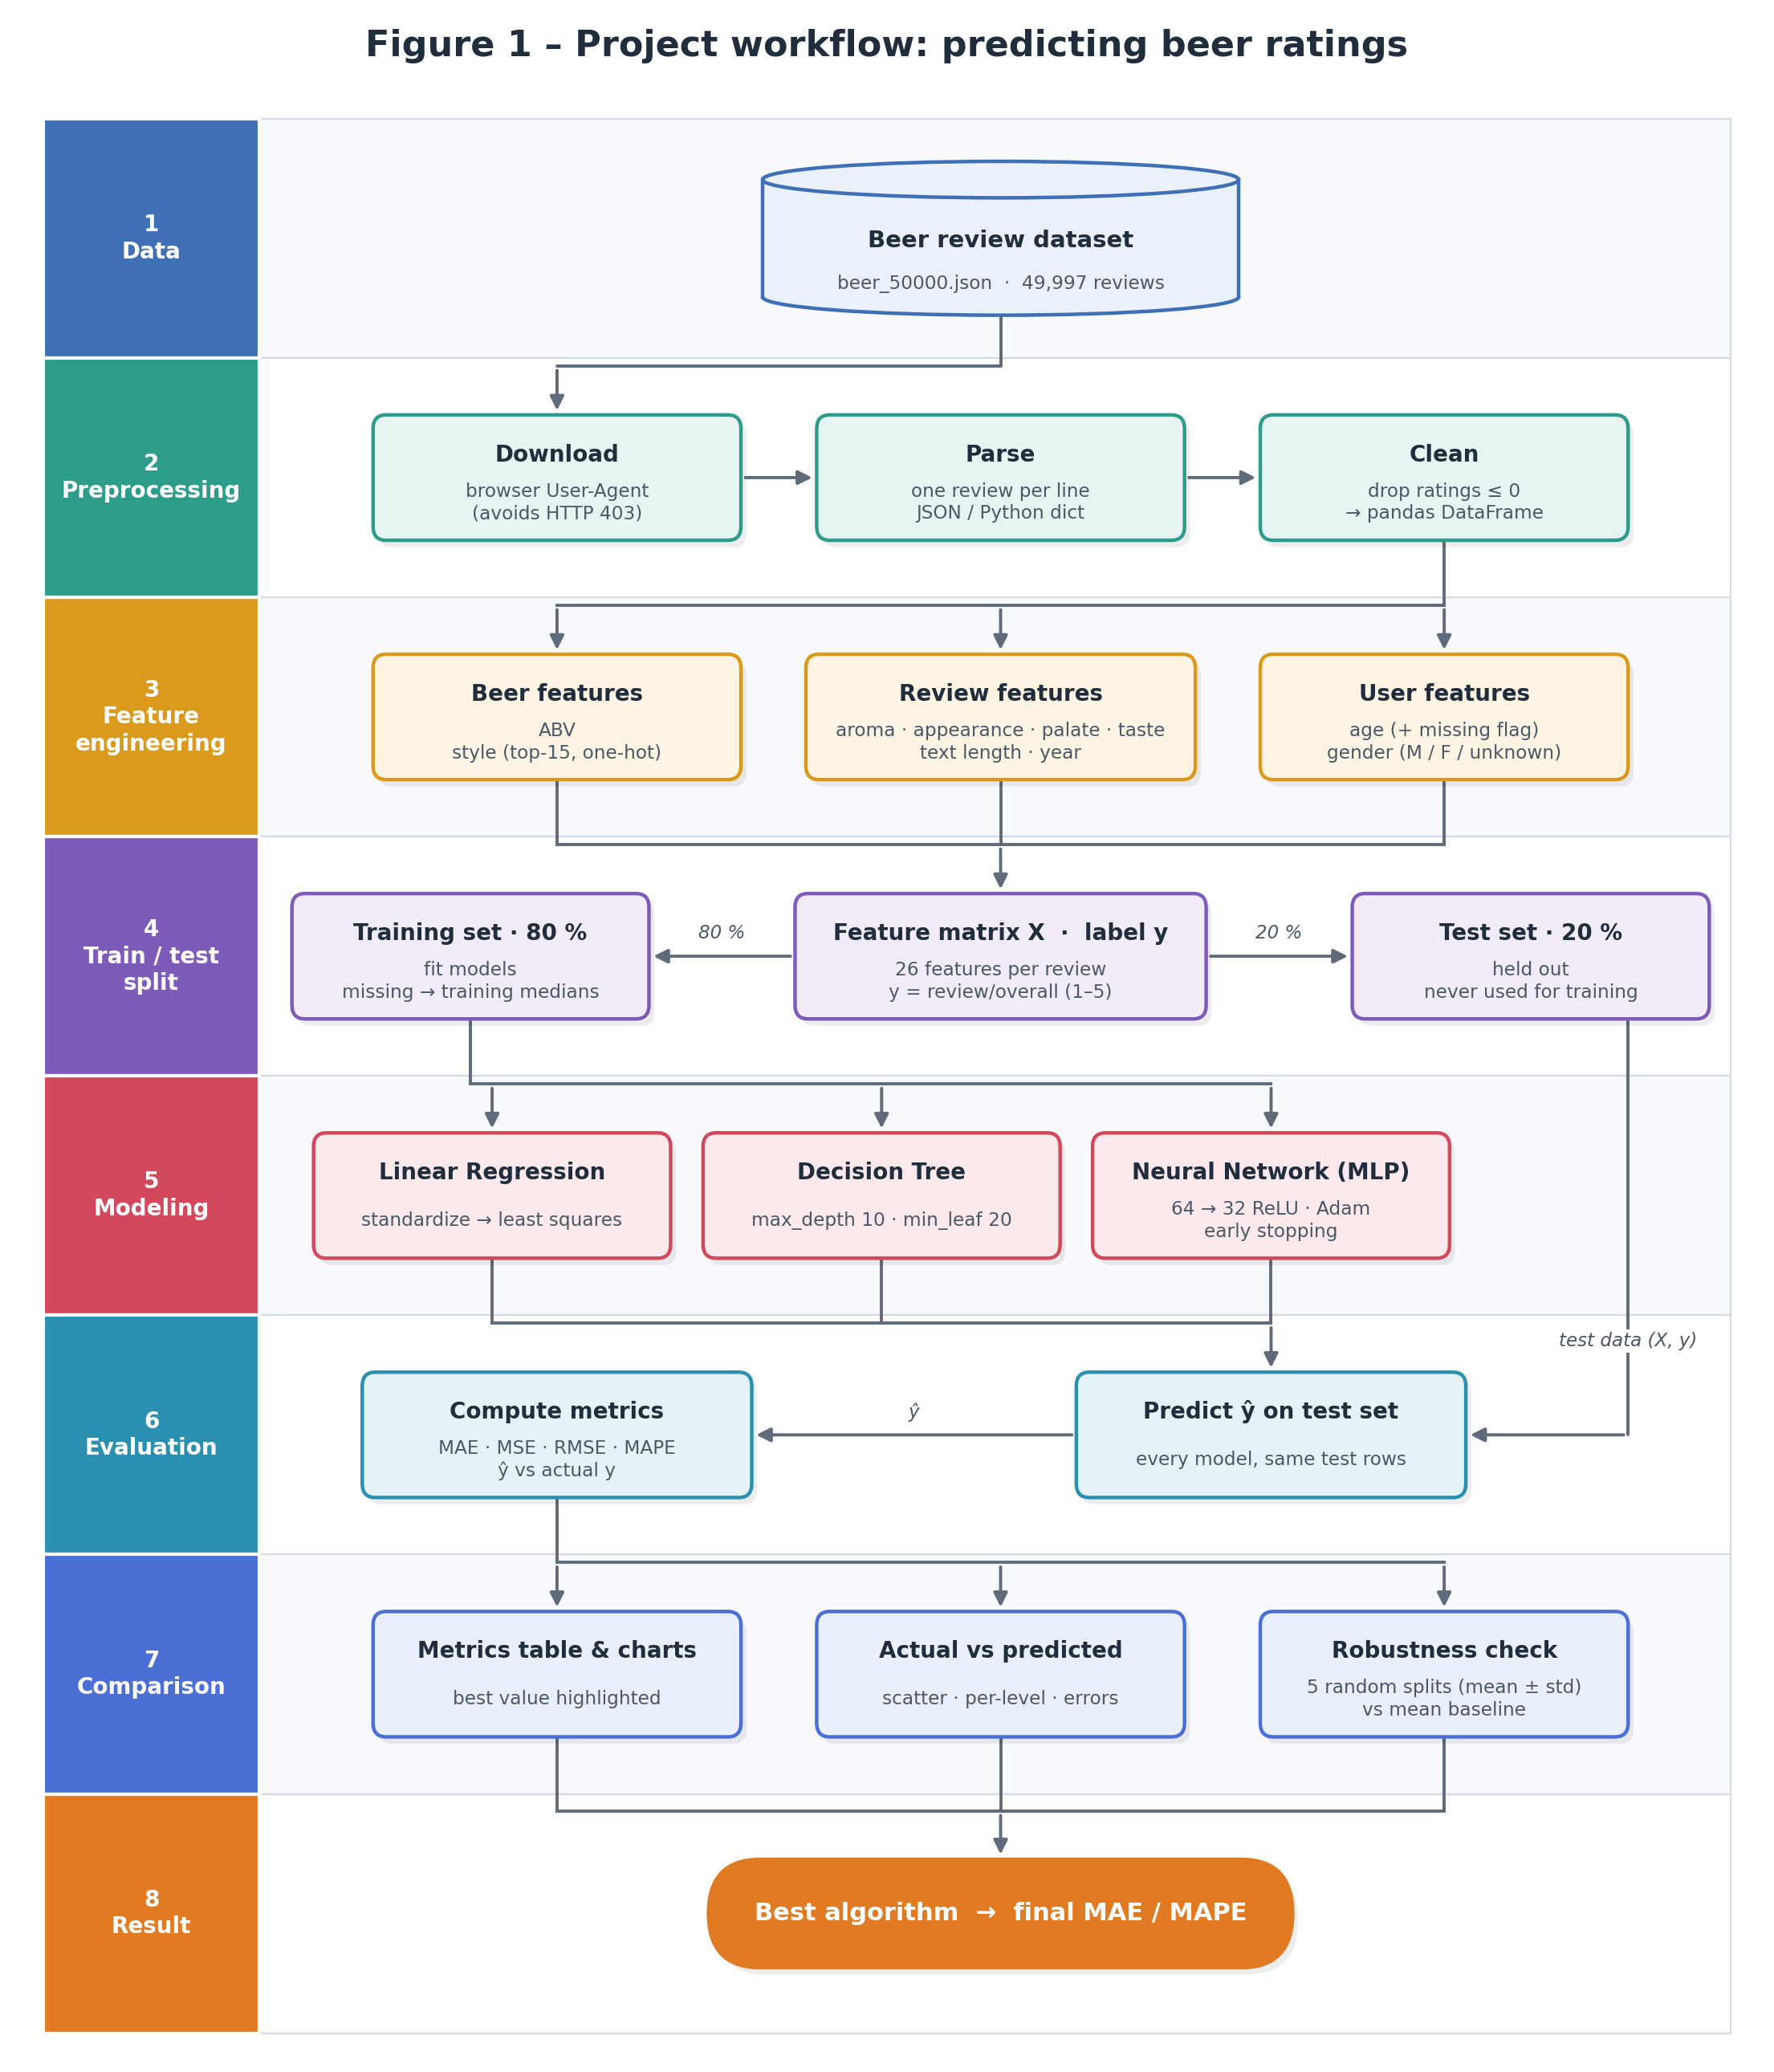

In [ ]:
# Figure 1: project workflow, drawn as a clean swimlane flowchart (Lucidchart style)
# (also saved as figure1_workflow.png so it can go straight into the report)
from matplotlib.patches import FancyBboxPatch, Rectangle, Ellipse

n_reviews, n_features = len(X), X.shape[1]   # taken from the real data

INK = "#1F2D3D"       # text
LINE = "#5F6B7A"      # connectors
LANES = [  # (title, accent color, light fill)
    ("Data",                "#3F6FB5", "#EAF1FB"),
    ("Preprocessing",       "#2E9C8A", "#E6F5F2"),
    ("Feature\nengineering", "#D99A1E", "#FDF4E3"),
    ("Train / test\nsplit",  "#7E5BB8", "#F1ECF8"),
    ("Modeling",            "#D1495B", "#FBE9EC"),
    ("Evaluation",          "#2B8FB0", "#E5F3F8"),
    ("Comparison",          "#4C6FD6", "#EAEFFC"),
    ("Result",              "#E07B24", "#FDEFE3"),
]
LANE_H, TOP = 2.1, 17.6
lane_y = [TOP - LANE_H * i - LANE_H / 2 for i in range(len(LANES))]   # center of each lane

fig, ax = plt.subplots(figsize=(14, 16.5))
ax.set_xlim(0, 16.1); ax.set_ylim(0.6, 18.5); ax.axis("off")


def lane_backgrounds():
    for i, (title, accent, fill) in enumerate(LANES):
        top = TOP - LANE_H * i
        ax.add_patch(Rectangle((0.25, top - LANE_H), 15.6, LANE_H, fc="#F7F9FC" if i % 2 == 0 else "white",
                               ec="#D5DBE3", lw=0.8, zorder=0))
        ax.add_patch(Rectangle((0.25, top - LANE_H), 2.0, LANE_H, fc=accent, ec="white", lw=1.5, zorder=1))
        ax.text(1.25, top - LANE_H / 2, f"{i + 1}\n{title}", ha="center", va="center", color="white",
                fontsize=10, weight="bold", linespacing=1.25, zorder=2)


def box(x, y, title, sub="", lane=0, w=3.4, h=1.1, pill=False):
    accent, fill = LANES[lane][1], LANES[lane][2]
    style = f"round,pad=0,rounding_size={h / 2 if pill else 0.12}"
    ax.add_patch(FancyBboxPatch((x - w / 2 + 0.05, y - h / 2 - 0.06), w, h, boxstyle=style,
                                fc="#00000012", ec="none", zorder=2))                       # soft shadow
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle=style,
                                fc=fill if not pill else accent, ec=accent, lw=1.6, zorder=3))
    color = "white" if pill else INK
    if sub:
        ax.text(x, y + 0.2, title, ha="center", va="center", fontsize=10, weight="bold", color=color, zorder=4)
        ax.text(x, y - 0.22, sub, ha="center", va="center", fontsize=8.4, color="#4A5868", zorder=4, linespacing=1.25)
    else:
        ax.text(x, y, title, ha="center", va="center", fontsize=11, weight="bold", color=color, zorder=4)


def cylinder(x, y, title, sub, lane=0, w=4.4, h=1.35):
    accent, fill = LANES[lane][1], LANES[lane][2]
    e = 0.32   # height of the top/bottom ellipse
    ax.add_patch(Ellipse((x, y - h / 2 + e / 2), w, e, fc=fill, ec=accent, lw=1.6, zorder=3))
    ax.add_patch(Rectangle((x - w / 2, y - h / 2 + e / 2), w, h - e, fc=fill, ec="none", zorder=3))
    ax.plot([x - w / 2, x - w / 2], [y - h / 2 + e / 2, y + h / 2 - e / 2], color=accent, lw=1.6, zorder=3)
    ax.plot([x + w / 2, x + w / 2], [y - h / 2 + e / 2, y + h / 2 - e / 2], color=accent, lw=1.6, zorder=3)
    ax.add_patch(Ellipse((x, y + h / 2 - e / 2), w, e, fc=fill, ec=accent, lw=1.6, zorder=4))
    ax.text(x, y - 0.02, title, ha="center", va="center", fontsize=10.5, weight="bold", color=INK, zorder=5)
    ax.text(x, y - 0.4, sub, ha="center", va="center", fontsize=8.4, color="#4A5868", zorder=5)


def connector(points, label="", label_at=0, label_offset=(0.12, 0), arrow=True):
    # orthogonal (elbow) connector through a list of points, arrow on the last segment
    xs, ys = zip(*points)
    ax.plot(xs[:-1], ys[:-1], color=LINE, lw=1.4, zorder=1.5, solid_capstyle="round")
    ax.annotate("", xy=points[-1], xytext=points[-2], zorder=1.5,
                arrowprops=dict(arrowstyle="-|>" if arrow else "-", color=LINE, lw=1.4, mutation_scale=13))
    if label:
        (x1, y1), (x2, y2) = points[label_at], points[label_at + 1]
        ax.text((x1 + x2) / 2 + label_offset[0], (y1 + y2) / 2 + label_offset[1], label, fontsize=8.3,
                style="italic", color="#4A5868", ha="center", va="center", zorder=6,
                bbox=dict(fc="white", ec="none", pad=1.2))


def bus(src_x, src_y, mid_y, targets, tgt_y):
    # one line leaves the source, splits on a horizontal "bus", and drops into every target
    xs = [src_x] + targets
    ax.plot([src_x, src_x], [src_y, mid_y], color=LINE, lw=1.4, zorder=1.5)
    ax.plot([min(xs), max(xs)], [mid_y, mid_y], color=LINE, lw=1.4, zorder=1.5)
    for tx in targets:
        connector([(tx, mid_y), (tx, tgt_y)])


def merge(sources, src_y, mid_y, tgt_x, tgt_y):
    # several sources join on a bus and continue into one target
    xs = sources + [tgt_x]
    for sx in sources:
        ax.plot([sx, sx], [src_y, mid_y], color=LINE, lw=1.4, zorder=1.5)
    ax.plot([min(xs), max(xs)], [mid_y, mid_y], color=LINE, lw=1.4, zorder=1.5)
    connector([(tgt_x, mid_y), (tgt_x, tgt_y)])


lane_backgrounds()
L = lane_y
COL3 = [5.0, 9.1, 13.2]   # three column positions

# 1 data
cylinder(9.1, L[0], "Beer review dataset", f"beer_50000.json  ·  {n_reviews:,} reviews", lane=0)

# 2 preprocessing
box(COL3[0], L[1], "Download", "browser User-Agent\n(avoids HTTP 403)", lane=1)
box(COL3[1], L[1], "Parse", "one review per line\nJSON / Python dict", lane=1)
box(COL3[2], L[1], "Clean", "drop ratings ≤ 0\n→ pandas DataFrame", lane=1)
connector([(9.1, L[0] - 0.68), (9.1, L[1] + 0.98), (COL3[0], L[1] + 0.98), (COL3[0], L[1] + 0.55)])
connector([(COL3[0] + 1.7, L[1]), (COL3[1] - 1.7, L[1])])
connector([(COL3[1] + 1.7, L[1]), (COL3[2] - 1.7, L[1])])

# 3 features
box(COL3[0], L[2], "Beer features", "ABV\nstyle (top-15, one-hot)", lane=2)
box(COL3[1], L[2], "Review features", "aroma · appearance · palate · taste\ntext length · year", lane=2, w=3.6)
box(COL3[2], L[2], "User features", "age (+ missing flag)\ngender (M / F / unknown)", lane=2)
bus(COL3[2], L[1] - 0.55, L[2] + 0.98, COL3, L[2] + 0.55)

# 4 split
box(9.1, L[3], "Feature matrix X  ·  label y", f"{n_features} features per review\ny = review/overall (1–5)", lane=3, w=3.8)
box(4.2, L[3], "Training set · 80 %", "fit models\nmissing → training medians", lane=3, w=3.3)
box(14.0, L[3], "Test set · 20 %", "held out\nnever used for training", lane=3, w=3.3)
merge(COL3, L[2] - 0.55, L[3] + 0.98, 9.1, L[3] + 0.55)
connector([(9.1 - 1.9, L[3]), (4.2 + 1.65, L[3])], "80 %", label_offset=(0, 0.2))
connector([(9.1 + 1.9, L[3]), (14.0 - 1.65, L[3])], "20 %", label_offset=(0, 0.2))

# 5 models
MODEL_X = [4.4, 8.0, 11.6]
box(MODEL_X[0], L[4], "Linear Regression", "standardize → least squares", lane=4, w=3.3)
box(MODEL_X[1], L[4], "Decision Tree", "max_depth 10 · min_leaf 20", lane=4, w=3.3)
box(MODEL_X[2], L[4], "Neural Network (MLP)", "64 → 32 ReLU · Adam\nearly stopping", lane=4, w=3.3)
bus(4.2, L[3] - 0.55, L[4] + 0.98, MODEL_X, L[4] + 0.55)

# 6 evaluation
box(11.6, L[5], "Predict ŷ on test set", "every model, same test rows", lane=5, w=3.6)
box(5.0, L[5], "Compute metrics", "MAE · MSE · RMSE · MAPE\nŷ vs actual y", lane=5, w=3.6)
merge(MODEL_X, L[4] - 0.55, L[5] + 0.98, 11.6, L[5] + 0.55)
connector([(14.9, L[3] - 0.55), (14.9, L[5]), (11.6 + 1.8, L[5])], "test data (X, y)", label_at=0,
          label_offset=(0, -1.0))
connector([(11.6 - 1.8, L[5]), (5.0 + 1.8, L[5])], "ŷ", label_offset=(0, 0.2))

# 7 comparison
box(COL3[0], L[6], "Metrics table & charts", "best value highlighted", lane=6)
box(COL3[1], L[6], "Actual vs predicted", "scatter · per-level · errors", lane=6)
box(COL3[2], L[6], "Robustness check", "5 random splits (mean ± std)\nvs mean baseline", lane=6)
bus(COL3[0], L[5] - 0.55, L[6] + 0.98, COL3, L[6] + 0.55)

# 8 result
box(9.1, L[7], "Best algorithm  →  final MAE / MAPE", lane=7, w=5.4, h=0.95, pill=True)
merge(COL3, L[6] - 0.55, L[7] + 0.9, 9.1, L[7] + 0.48)

ax.text(8.05, 18.15, "Figure 1 – Project workflow: predicting beer ratings", ha="center",
        fontsize=16, weight="bold", color=INK)
plt.savefig("figure1_workflow.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

**Figure 2 – Knowledge graph.** The dataset describes three entities: a **user** *writes* a **review**, and the review *is about* a **beer**.
Each entity has attributes (age and gender for users, ABV and style for beers, the sub-scores, text length and year for reviews).
The review's **overall rating** is the *target*. All other attributes are *encoded* into a numeric feature vector **X**, which is the
*input* to each regression algorithm. Each algorithm *predicts* a rating ŷ, and the predictions are *compared* with the actual rating y
using the four metrics to choose the best algorithm.

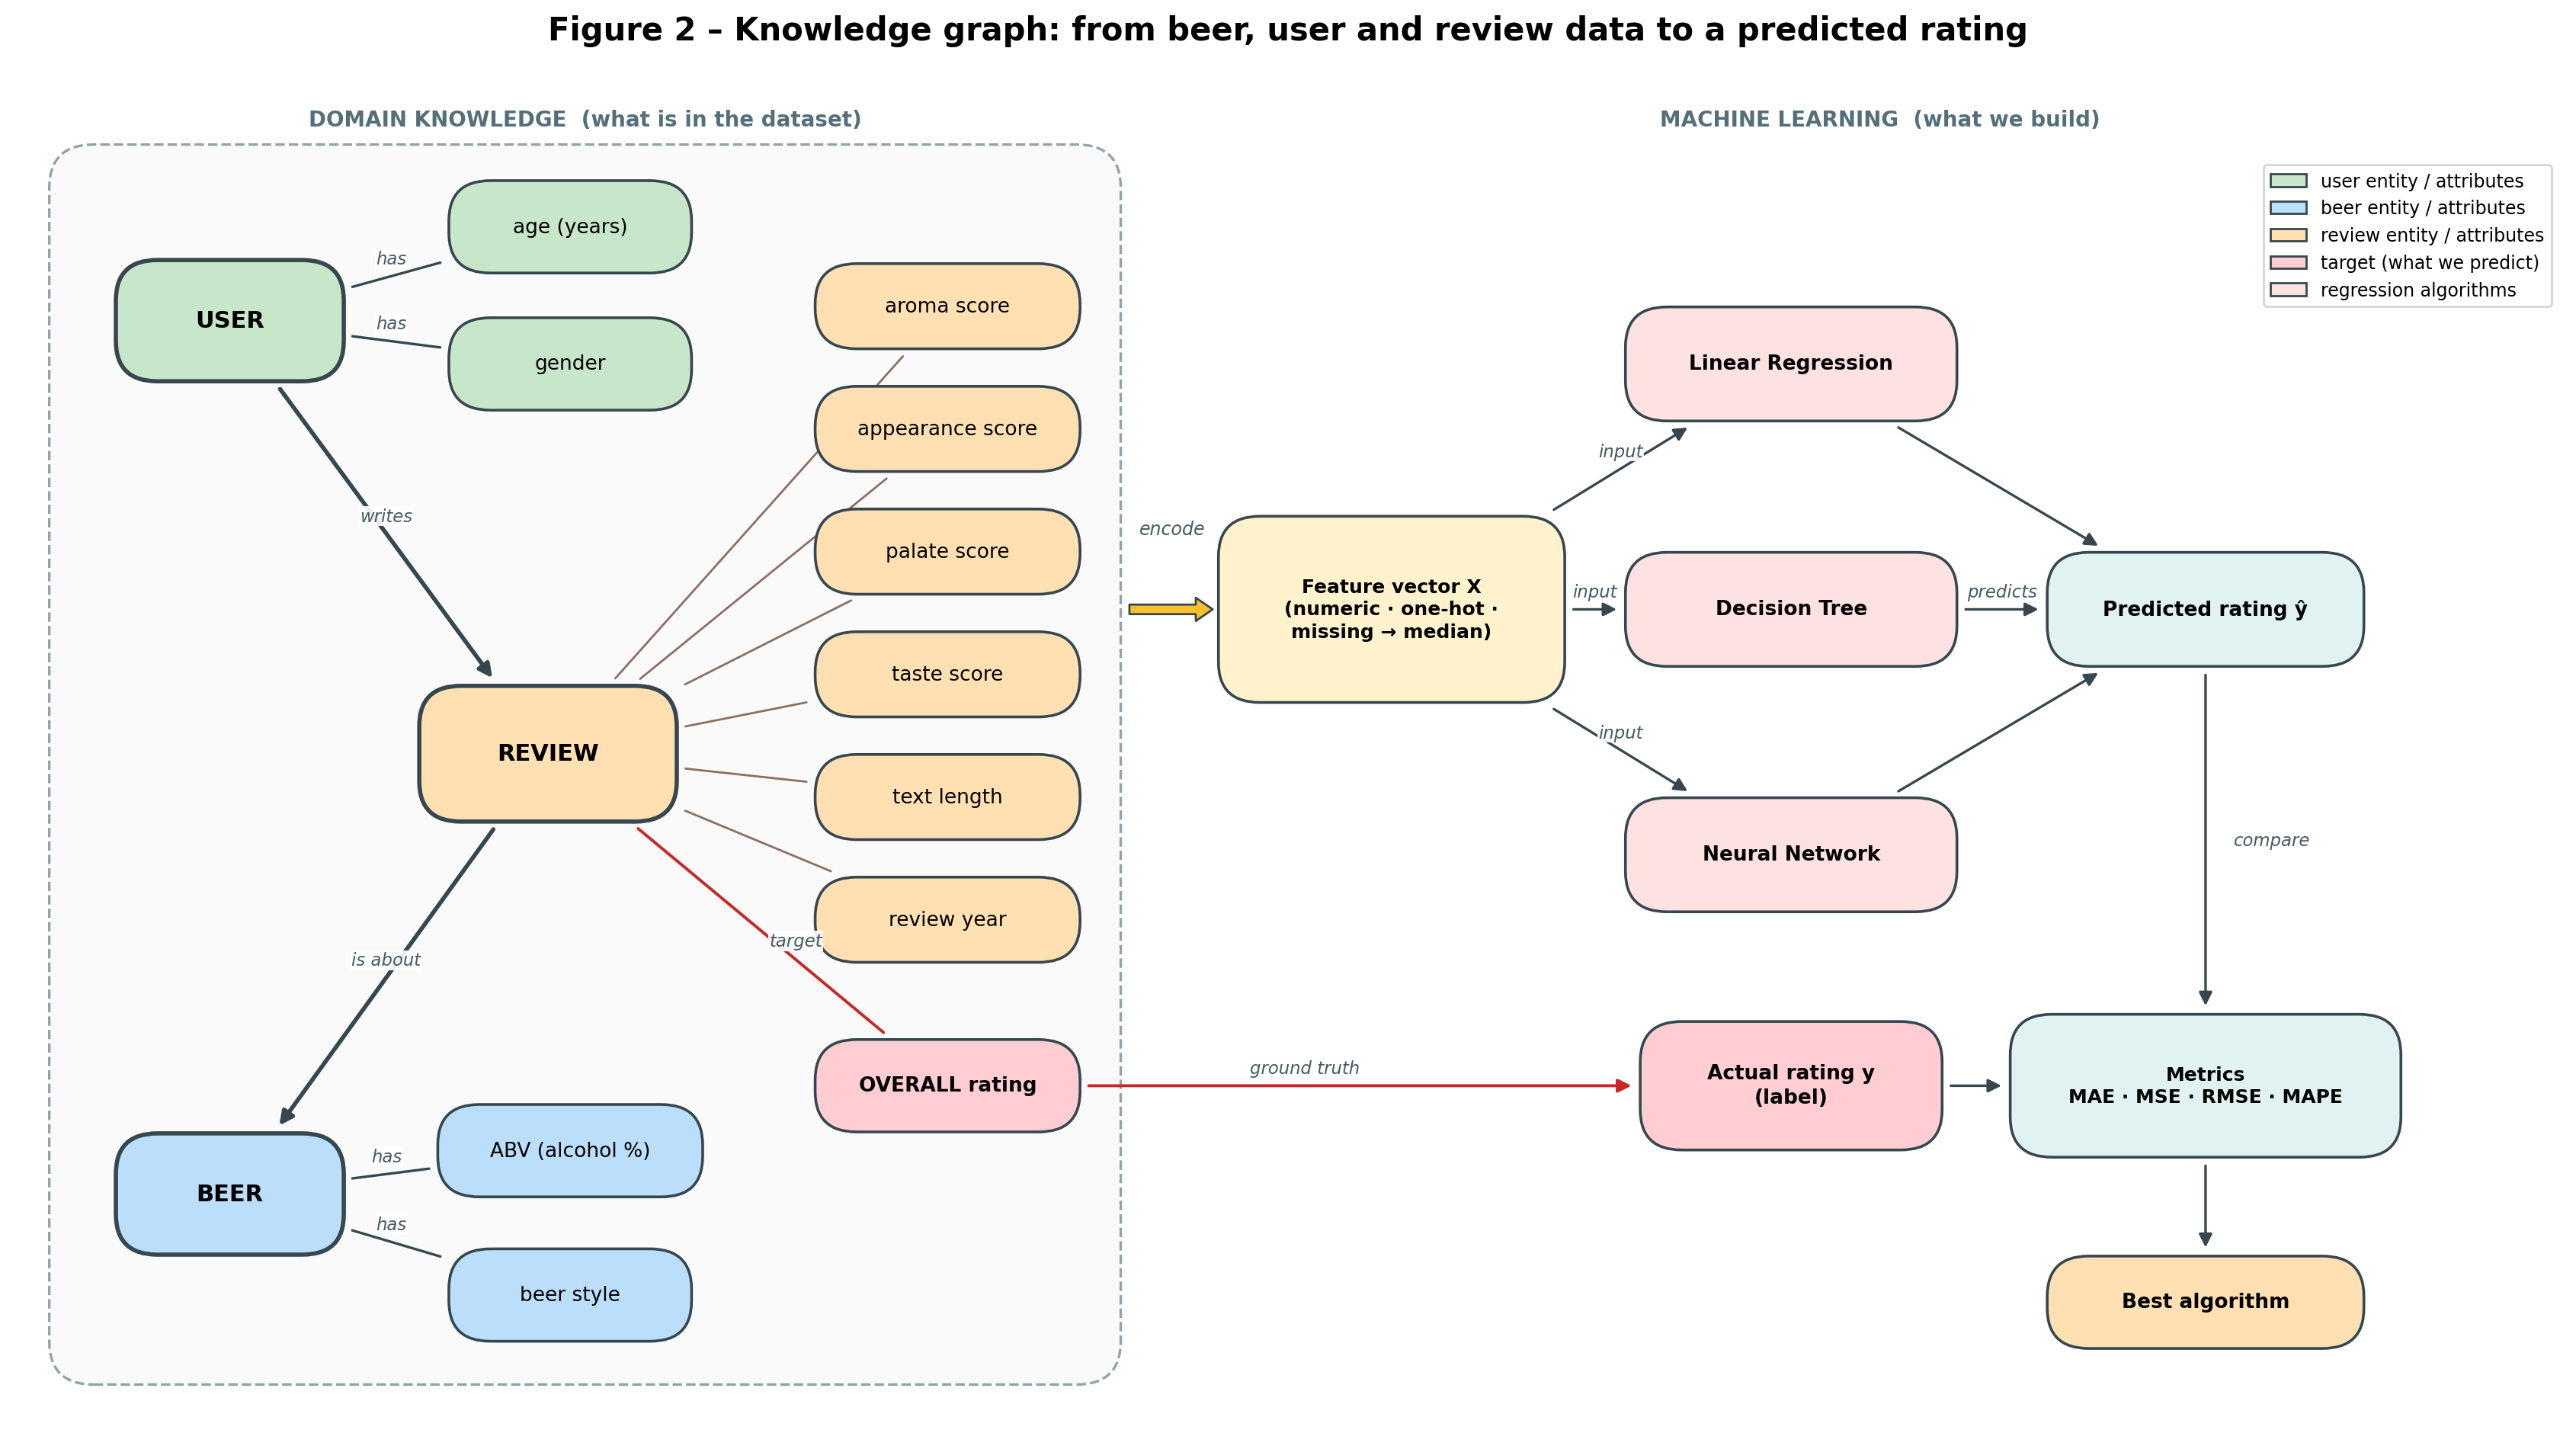

In [ ]:
# Figure 2: knowledge graph - how the things in the dataset relate to each other and to our models

from matplotlib.patches import FancyBboxPatch, Patch

EDGE = "#37474F"
COL = {"entity": "#1E88E5", "beer": "#BBDEFB", "user": "#C8E6C9", "review": "#FFE0B2",
       "label": "#FFCDD2", "x": "#FFF2CC", "model": "#FDE2E1", "out": "#E0F2F1"}

fig, ax = plt.subplots(figsize=(17, 9.5))
ax.set_xlim(0, 17.2); ax.set_ylim(0, 9.4); ax.axis("off")
nodes = {}

def node(key, x, y, text, color, w=1.6, h=0.6, bold=False, size=9.5, ec=EDGE, lw=1.3):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.28",
                                fc=color, ec=ec, lw=lw, zorder=3))
    ax.text(x, y, text, ha="center", va="center", fontsize=size, weight="bold" if bold else "normal", zorder=4, linespacing=1.3)
    nodes[key] = (x, y, w, h)

def edge_pt(key, tx, ty):
    # point on the border of a node's box, in the direction of (tx, ty)
    x, y, w, h = nodes[key]
    dx, dy = tx - x, ty - y
    s = min((w / 2 + 0.05) / abs(dx) if dx else 1e9, (h / 2 + 0.05) / abs(dy) if dy else 1e9)
    return x + dx * s, y + dy * s

def link(a, b, label="", style="-|>", ls="-", color=EDGE, lw=1.2, lpos=0.5, loff=(0, 0.12)):
    ax_, ay_ = nodes[a][:2]; bx_, by_ = nodes[b][:2]
    x1, y1 = edge_pt(a, bx_, by_); x2, y2 = edge_pt(b, ax_, ay_)
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle=style, color=color, lw=lw, ls=ls, mutation_scale=13), zorder=2)
    if label:
        ax.text(x1 + (x2 - x1) * lpos + loff[0], y1 + (y2 - y1) * lpos + loff[1], label, fontsize=8.2,
                style="italic", color="#455A64", ha="center", va="center", zorder=5,
                bbox=dict(fc="white", ec="none", pad=0.6, alpha=0.9))

# ---- domain knowledge region ----
ax.add_patch(FancyBboxPatch((0.25, 0.25), 7.2, 8.55, boxstyle="round,pad=0.02,rounding_size=0.3",
                            fc="#FAFAFA", ec="#90A4AE", lw=1.2, ls="--", zorder=0))
ax.text(3.85, 8.95, "DOMAIN KNOWLEDGE  (what is in the dataset)", ha="center", fontsize=10, weight="bold", color="#546E7A")

# entities
node("user", 1.45, 7.6, "USER", COL["user"], w=1.5, h=0.8, bold=True, size=11, lw=2)
node("review", 3.6, 4.6, "REVIEW", COL["review"], w=1.7, h=0.9, bold=True, size=11, lw=2)
node("beer", 1.45, 1.55, "BEER", COL["beer"], w=1.5, h=0.8, bold=True, size=11, lw=2)
link("user", "review", "writes", lw=2)
link("review", "beer", "is about", lw=2)

# user attributes
node("age", 3.75, 8.25, "age (years)", COL["user"])
node("gender", 3.75, 7.3, "gender", COL["user"])
link("user", "age", "has", style="-", lpos=0.45)
link("user", "gender", "has", style="-", lpos=0.45)

# beer attributes
node("abv", 3.75, 1.85, "ABV (alcohol %)", COL["beer"], w=1.75)
node("style", 3.75, 0.85, "beer style", COL["beer"])
link("beer", "abv", "has", style="-", lpos=0.45)
link("beer", "style", "has", style="-", lpos=0.45)

# review attributes
review_attrs = [("aroma", "aroma score"), ("appear", "appearance score"), ("palate", "palate score"),
                ("taste", "taste score"), ("len", "text length"), ("year", "review year")]
for (k, t), yy in zip(review_attrs, [7.7, 6.85, 6.0, 5.15, 4.3, 3.45]):
    node(k, 6.3, yy, t, COL["review"], w=1.75, h=0.55)
    link("review", k, style="-", color="#8D6E63", lw=1)
node("overall", 6.3, 2.3, "OVERALL rating", COL["label"], w=1.75, h=0.6, bold=True)
link("review", "overall", "target", style="-", color="#C62828", lw=1.4, lpos=0.55, loff=(0.15, 0))

# ---- machine learning part ----
ax.text(12.6, 8.95, "MACHINE LEARNING  (what we build)", ha="center", fontsize=10, weight="bold", color="#546E7A")
node("X", 9.3, 5.6, "Feature vector X\n(numeric · one-hot ·\nmissing → median)", COL["x"], w=2.3, h=1.25, bold=True, size=9)
ax.annotate("", xy=(8.12, 5.6), xytext=(7.5, 5.6),
            arrowprops=dict(arrowstyle="simple,head_width=1.1,head_length=0.8,tail_width=0.45", fc="#FBC02D", ec=EDGE), zorder=2)
ax.text(7.82, 6.12, "encode", fontsize=8.5, style="italic", color="#455A64", ha="center")

for k, t, yy in [("lr", "Linear Regression", 7.3), ("dt", "Decision Tree", 5.6), ("nn", "Neural Network", 3.9)]:
    node(k, 12.0, yy, t, COL["model"], w=2.2, h=0.75, bold=True)
    link("X", k, "input", lpos=0.5)

node("yhat", 14.8, 5.6, "Predicted rating ŷ", COL["out"], w=2.1, h=0.75, bold=True)
for k in ("lr", "dt", "nn"):
    link(k, "yhat", "predicts" if k == "dt" else "", lpos=0.5)

node("y", 12.0, 2.3, "Actual rating y\n(label)", COL["label"], w=2.0, h=0.85, bold=True)
link("overall", "y", "ground truth", color="#C62828", lw=1.4, lpos=0.4)

node("metrics", 14.8, 2.3, "Metrics\nMAE · MSE · RMSE · MAPE", COL["out"], w=2.6, h=0.95, bold=True, size=9)
link("yhat", "metrics", "compare", lpos=0.5, loff=(0.45, 0))
link("y", "metrics", "", lpos=0.5)

node("best", 14.8, 0.8, "Best algorithm", "#FFE0B2", w=2.1, h=0.6, bold=True)
link("metrics", "best", "")

ax.legend(handles=[Patch(fc=COL["user"], ec=EDGE, label="user entity / attributes"),
                   Patch(fc=COL["beer"], ec=EDGE, label="beer entity / attributes"),
                   Patch(fc=COL["review"], ec=EDGE, label="review entity / attributes"),
                   Patch(fc=COL["label"], ec=EDGE, label="target (what we predict)"),
                   Patch(fc=COL["model"], ec=EDGE, label="regression algorithms")],
          loc="upper right", bbox_to_anchor=(1.0, 0.93), fontsize=8.5, frameon=True)

ax.set_title("Figure 2 – Knowledge graph: from beer, user and review data to a predicted rating",
             fontsize=15, weight="bold", pad=10)
plt.tight_layout()
plt.savefig("figure2_knowledge_graph.png", dpi=200, bbox_inches="tight")
plt.show()

### Knowledge graph for each algorithm

The cell below defines one drawing function that we reuse for all three algorithms, so their knowledge graphs share the same layout:
the algorithm sits in the center and is connected to its **input, learning method, model structure, settings, output,
strengths, weaknesses** and **role in this project**. Next to each graph is a small sketch of how the algorithm works.
Each graph is shown at the start of its algorithm's section and saved as a PNG for the report.

In [ ]:
# Knowledge graph for each algorithm (one function draws all three in the same style)
from matplotlib.patches import FancyBboxPatch, Circle

KG_INK, KG_LINE = "#1F2D3D", "#7A8794"
KG_CAT = {  # category -> (border, fill)
    "io":     ("#2B8FB0", "#E5F3F8"),
    "learn":  ("#7E5BB8", "#F1ECF8"),
    "set":    ("#D99A1E", "#FDF4E3"),
    "good":   ("#3C9A5F", "#E8F5EC"),
    "bad":    ("#D1495B", "#FBE9EC"),
    "role":   ("#4C6FD6", "#EAEFFC"),
}
# (key, category, relation shown on the edge, angle in degrees around the center)
KG_LAYOUT = [
    ("Input",        "io",    "takes",         145),
    ("Learns by",    "learn", "learns by",      90),
    ("Model",        "learn", "structure",      35),
    ("Settings",     "set",   "configured by",   0),
    ("Output",       "io",    "produces",      -35),
    ("Strengths",    "good",  "strengths",     -90),
    ("Weaknesses",   "bad",   "weaknesses",   -145),
    ("Role in project", "role", "role",        180),
]


def _kg_node(ax, x, y, title, text, border, fill, w=2.55, h=1.15):
    ax.add_patch(FancyBboxPatch((x - w / 2 + 0.04, y - h / 2 - 0.05), w, h, boxstyle="round,pad=0,rounding_size=0.15",
                                fc="#00000010", ec="none", zorder=2))
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.15",
                                fc=fill, ec=border, lw=1.5, zorder=3))
    ax.add_patch(FancyBboxPatch((x - w / 2, y + h / 2 - 0.34), w, 0.34, boxstyle="round,pad=0,rounding_size=0.15",
                                fc=border, ec=border, lw=1.5, zorder=3))
    ax.text(x, y + h / 2 - 0.17, title.upper(), ha="center", va="center", fontsize=8.3, weight="bold",
            color="white", zorder=4)
    ax.text(x, y - 0.17, text, ha="center", va="center", fontsize=8.6, color=KG_INK, zorder=4, linespacing=1.3)


def draw_algorithm_graph(name, color, info, illustrate, filename):
    fig = plt.figure(figsize=(16, 7.4))
    gs = fig.add_gridspec(1, 2, width_ratios=[1.5, 1], wspace=0.18)
    ax = fig.add_subplot(gs[0]); ax.set_xlim(0, 11); ax.set_ylim(0, 8); ax.set_aspect("equal"); ax.axis("off")

    cx, cy, rx, ry = 5.5, 4.0, 4.1, 2.9
    for key, cat, rel, ang in KG_LAYOUT:
        a = np.radians(ang)
        x, y = cx + rx * np.cos(a), cy + ry * np.sin(a)
        ax.plot([cx, x], [cy, y], color=KG_LINE, lw=1.3, zorder=1)
        lx, ly = cx + (x - cx) * 0.5, cy + (y - cy) * 0.5
        ax.text(lx, ly, rel, fontsize=7.8, style="italic", color="#4A5868", ha="center", va="center", zorder=5,
                bbox=dict(fc="white", ec="none", pad=1))
        _kg_node(ax, x, y, key, info[key], *KG_CAT[cat])

    ax.add_patch(Circle((cx, cy), 1.0, fc=color, ec="white", lw=3, zorder=6))
    ax.text(cx, cy, name.replace(" ", "\n", 1), ha="center", va="center", fontsize=11.5, weight="bold",
            color="white", zorder=7, linespacing=1.2)

    ax2 = fig.add_subplot(gs[1])
    illustrate(ax2)

    fig.suptitle(f"Knowledge graph – {name}", fontsize=16, weight="bold", color=KG_INK, y=0.98)
    plt.savefig(filename, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()


# ---------- small "how it works" sketch for each algorithm ----------
def illustrate_lr(ax):
    rng = np.random.default_rng(1)
    x = rng.uniform(1.5, 5, 40)
    y = np.clip(0.75 * x + 0.9 + rng.normal(0, 0.35, 40), 1, 5)
    w, b = np.polyfit(x, y, 1)
    xs = np.linspace(1.3, 5.1, 10)
    for xi, yi in zip(x, y):
        ax.plot([xi, xi], [yi, w * xi + b], color="#D1495B", lw=0.8, alpha=0.6)
    ax.scatter(x, y, s=22, color="#3F6FB5", zorder=3, label="reviews")
    ax.plot(xs, w * xs + b, color="#1F2D3D", lw=2.2, label=f"fitted line  ŷ = {w:.2f}·x + {b:.2f}")
    ax.plot([], [], color="#D1495B", label="errors (minimized)")
    ax.set_xlabel("taste score (one feature)")
    ax.set_ylabel("overall rating")
    ax.set_title("How it works: best straight line\n(illustration, 1 feature)", fontsize=11)
    ax.legend(fontsize=8.5, loc="upper left")
    ax.grid(alpha=0.25)


def illustrate_dt(ax):
    ax.set_xlim(0, 10); ax.set_ylim(0, 8); ax.axis("off")

    def q(x, y, t):
        ax.add_patch(FancyBboxPatch((x - 1.3, y - 0.35), 2.6, 0.7, boxstyle="round,pad=0,rounding_size=0.12",
                                    fc="#E8F5EC", ec="#3C9A5F", lw=1.5, zorder=3))
        ax.text(x, y, t, ha="center", va="center", fontsize=9, weight="bold", color=KG_INK, zorder=4)

    def leaf(x, y, t):
        ax.add_patch(FancyBboxPatch((x - 0.85, y - 0.32), 1.7, 0.64, boxstyle="round,pad=0,rounding_size=0.3",
                                    fc="#3C9A5F", ec="#3C9A5F", zorder=3))
        ax.text(x, y, t, ha="center", va="center", fontsize=9, weight="bold", color="white", zorder=4)

    def line(x1, y1, x2, y2, t):
        ax.plot([x1, x2], [y1, y2], color=KG_LINE, lw=1.3, zorder=1)
        ax.text((x1 + x2) / 2 + (-0.3 if x2 < x1 else 0.3), (y1 + y2) / 2 + 0.1, t, fontsize=8, style="italic",
                color="#4A5868", ha="center")

    q(5, 6.8, "taste ≤ 3.75 ?")
    q(2.6, 4.6, "aroma ≤ 3.25 ?"); q(7.4, 4.6, "palate ≤ 4.25 ?")
    line(5, 6.45, 2.6, 4.95, "yes"); line(5, 6.45, 7.4, 4.95, "no")
    for x, v in [(1.4, "ŷ = 2.9"), (3.8, "ŷ = 3.5"), (6.2, "ŷ = 3.9"), (8.6, "ŷ = 4.4")]:
        parent = 2.6 if x < 5 else 7.4
        line(parent, 4.25, x, 2.75, "yes" if x in (1.4, 6.2) else "no")
        leaf(x, 2.4, v)
    ax.text(5, 1.2, "each leaf predicts the average rating of\nthe training reviews that end up there",
            ha="center", fontsize=9, color="#4A5868", style="italic")
    ax.set_title("How it works: yes/no rules\n(illustration, depth 2 of 10)", fontsize=11)


def illustrate_nn(ax):
    ax.set_xlim(0, 10); ax.set_ylim(0, 8); ax.axis("off")
    try:
        n_feat = X.shape[1]
    except NameError:
        n_feat = 26
    layers = [(1.2, 6, f"input X\n({n_feat} features)", "#2B8FB0"), (4.0, 7, "hidden 1\n64 · ReLU", "#7E5BB8"),
              (6.8, 5, "hidden 2\n32 · ReLU", "#7E5BB8"), (9.0, 1, "output\nŷ", "#D1495B")]
    pos = []
    for x, n, _, _ in layers:
        ys = np.linspace(6.6, 1.8, n) if n > 1 else [4.2]
        pos.append([(x, y) for y in ys])
    for a, b in zip(pos[:-1], pos[1:]):
        for p in a:
            for q in b:
                ax.plot([p[0], q[0]], [p[1], q[1]], color="#B0BAC5", lw=0.5, zorder=1)
    for (x, n, label, c), pts in zip(layers, pos):
        for p in pts:
            ax.add_patch(Circle(p, 0.24, fc=c, ec="white", lw=1.2, zorder=3))
        ax.text(x, 0.85, label, ha="center", va="center", fontsize=8.8, weight="bold", color=KG_INK)
    ax.annotate("", xy=(8.4, 7.4), xytext=(1.2, 7.4), arrowprops=dict(arrowstyle="-|>", color="#2B8FB0", lw=1.4))
    ax.text(4.8, 7.6, "forward pass: weighted sums + ReLU", ha="center", fontsize=8.3, color="#2B8FB0")
    ax.annotate("", xy=(1.2, 0.2), xytext=(8.4, 0.2), arrowprops=dict(arrowstyle="-|>", color="#D1495B", lw=1.4))
    ax.text(4.8, -0.05, "backpropagation: adjust weights to reduce error", ha="center", fontsize=8.3,
            color="#D1495B", va="top")
    ax.set_ylim(-0.6, 8)
    ax.set_aspect("equal")
    ax.set_title("How it works: layers of neurons\n(illustration, fewer neurons drawn)", fontsize=11)


# parameter counts from the real feature matrix
_d = X.shape[1] if "X" in globals() else 26
_nn_params = (_d * 64 + 64) + (64 * 32 + 32) + (32 * 1 + 1)

LR_INFO = {
    "Input": "feature vector X\n(standardized)",
    "Learns by": "least squares\nloss = MSE = (1/n)Σ(y − ŷ)²",
    "Model": f"ŷ = w·x + b\n{_d} weights + 1 bias",
    "Settings": "StandardScaler\nno hyperparameters",
    "Output": "predicted rating ŷ\n(clipped to 1–5)",
    "Strengths": "fast · interpretable\nno tuning · stable",
    "Weaknesses": "straight lines only\nno feature interactions",
    "Role in project": "baseline model\nshows feature weights",
}
DT_INFO = {
    "Input": "feature vector X\n(no scaling needed)",
    "Learns by": "greedy splits\ncriterion = squared error",
    "Model": "tree of yes/no rules\nleaf = mean rating",
    "Settings": "max_depth = 10\nmin_samples_leaf = 20",
    "Output": "predicted rating ŷ\n(one value per leaf)",
    "Strengths": "non-linear rules\nfeature importance",
    "Weaknesses": "step-like predictions\noverfits if too deep",
    "Role in project": "non-linear comparison\nexplains key features",
}
NN_INFO = {
    "Input": "feature vector X\n(standardized)",
    "Learns by": "backprop + Adam\nloss = ½·MSE + L2",
    "Model": f"{_d} → 64 → 32 → 1 (ReLU)\n{_nn_params:,} parameters",
    "Settings": "early stopping\nmax_iter = 300",
    "Output": "predicted rating ŷ\n(1 output neuron)",
    "Strengths": "learns curves and\ninteractions itself",
    "Weaknesses": "needs scaling & tuning\nblack box · slower",
    "Role in project": "most flexible model\nmain candidate",
}

---
## 4. Algorithm 1 – Linear Regression (LR)

**How it works**
Linear Regression gives every feature a weight and predicts the rating as a weighted sum:

$$\hat{y} = w_1x_1 + w_2x_2 + \dots + w_nx_n + b$$

The weights are chosen so that the **squared error on the training data is as small as possible** (least squares).

**Why it suits this problem**
The overall rating is roughly a weighted mix of the taste, aroma, palate and appearance scores, which is exactly the kind of relationship LR models.

**Settings:** features are standardized first (mean 0, std 1) so the weights can be compared with each other.

| Strengths | Weaknesses |
|-----------|-----------|
| fast, simple, no tuning | only straight-line relationships |
| easy to explain (one weight per feature) | misses feature interactions |

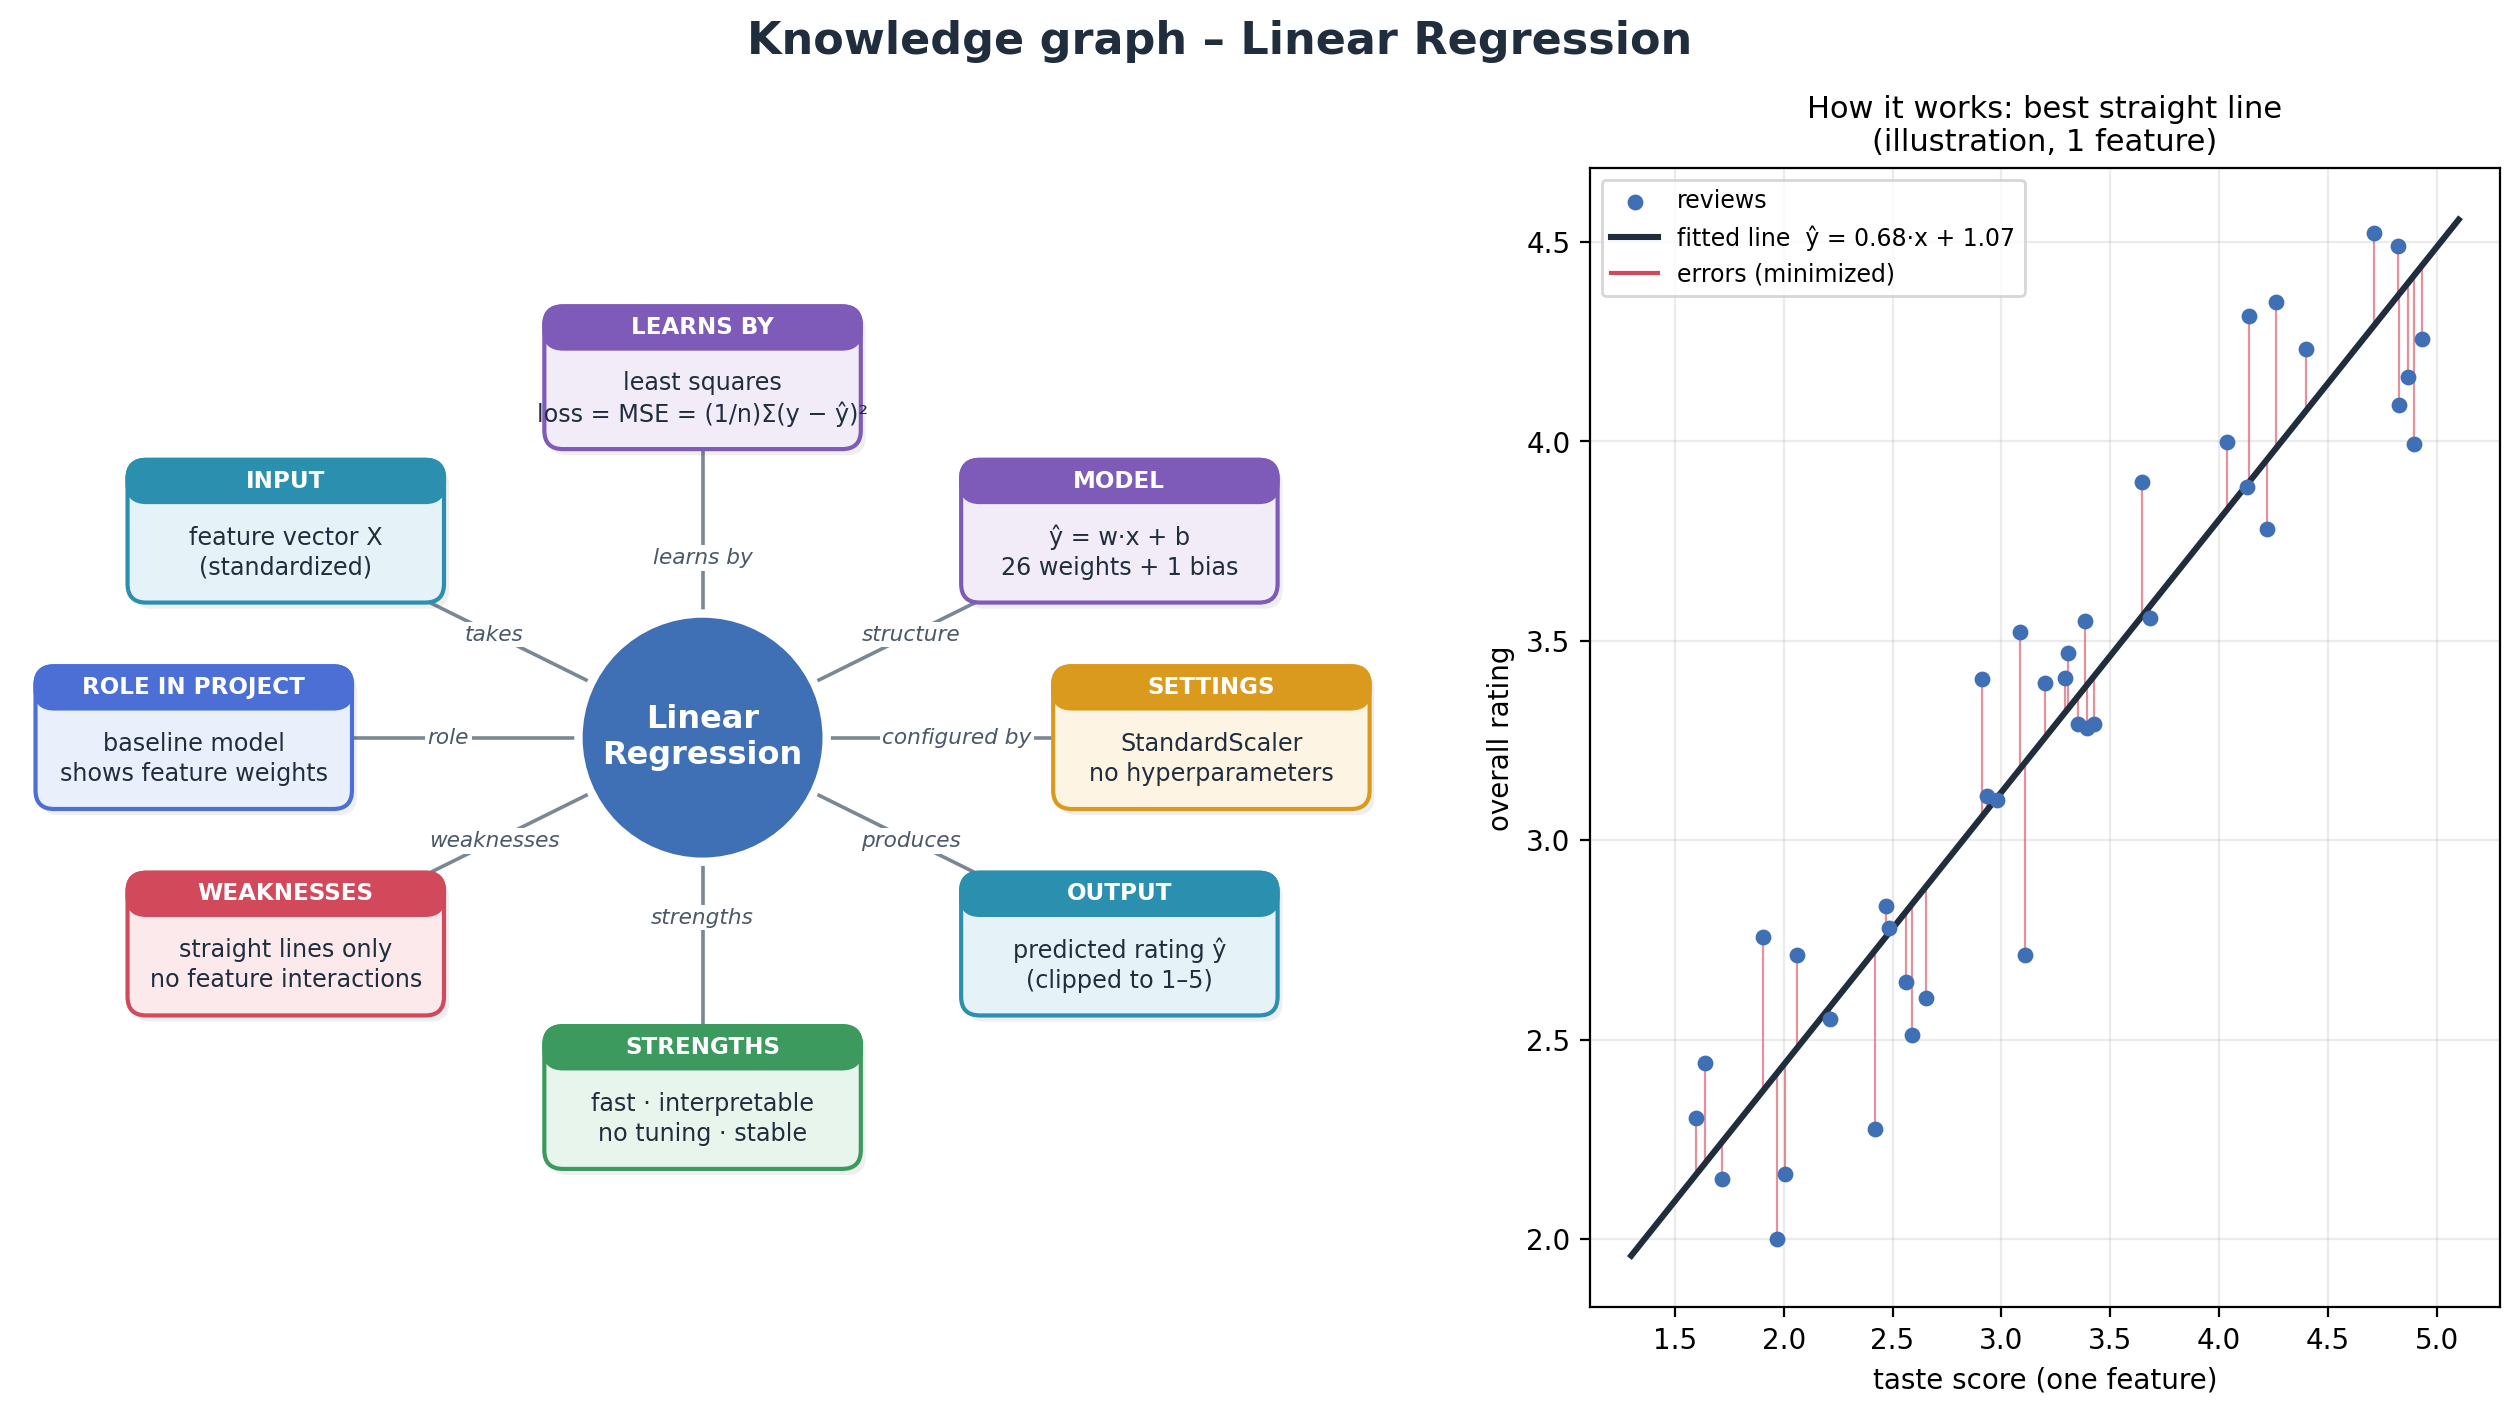

In [ ]:
# knowledge graph of Linear Regression: what it takes in, how it learns, its settings, output, strengths and weaknesses
draw_algorithm_graph("Linear Regression", "#3F6FB5", LR_INFO, illustrate_lr, "kg_linear_regression.png")

===== Linear Regression: test set results =====
  MAE       0.3046
  MSE       0.1618
  RMSE      0.4023
  MAPE (%)  8.8198
  82.0% of test reviews are predicted within ±0.5 of the actual rating


,Actual,Predicted,Error (pred - actual)
0,4.0,4.50,0.50
1,3.0,3.27,0.27
2,4.0,4.08,0.08
3,3.5,3.38,-0.12
4,3.0,3.36,0.36
5,5.0,4.30,-0.70
6,3.0,3.65,0.65
7,5.0,4.71,-0.29
8,3.0,3.35,0.35
9,4.0,4.20,0.20


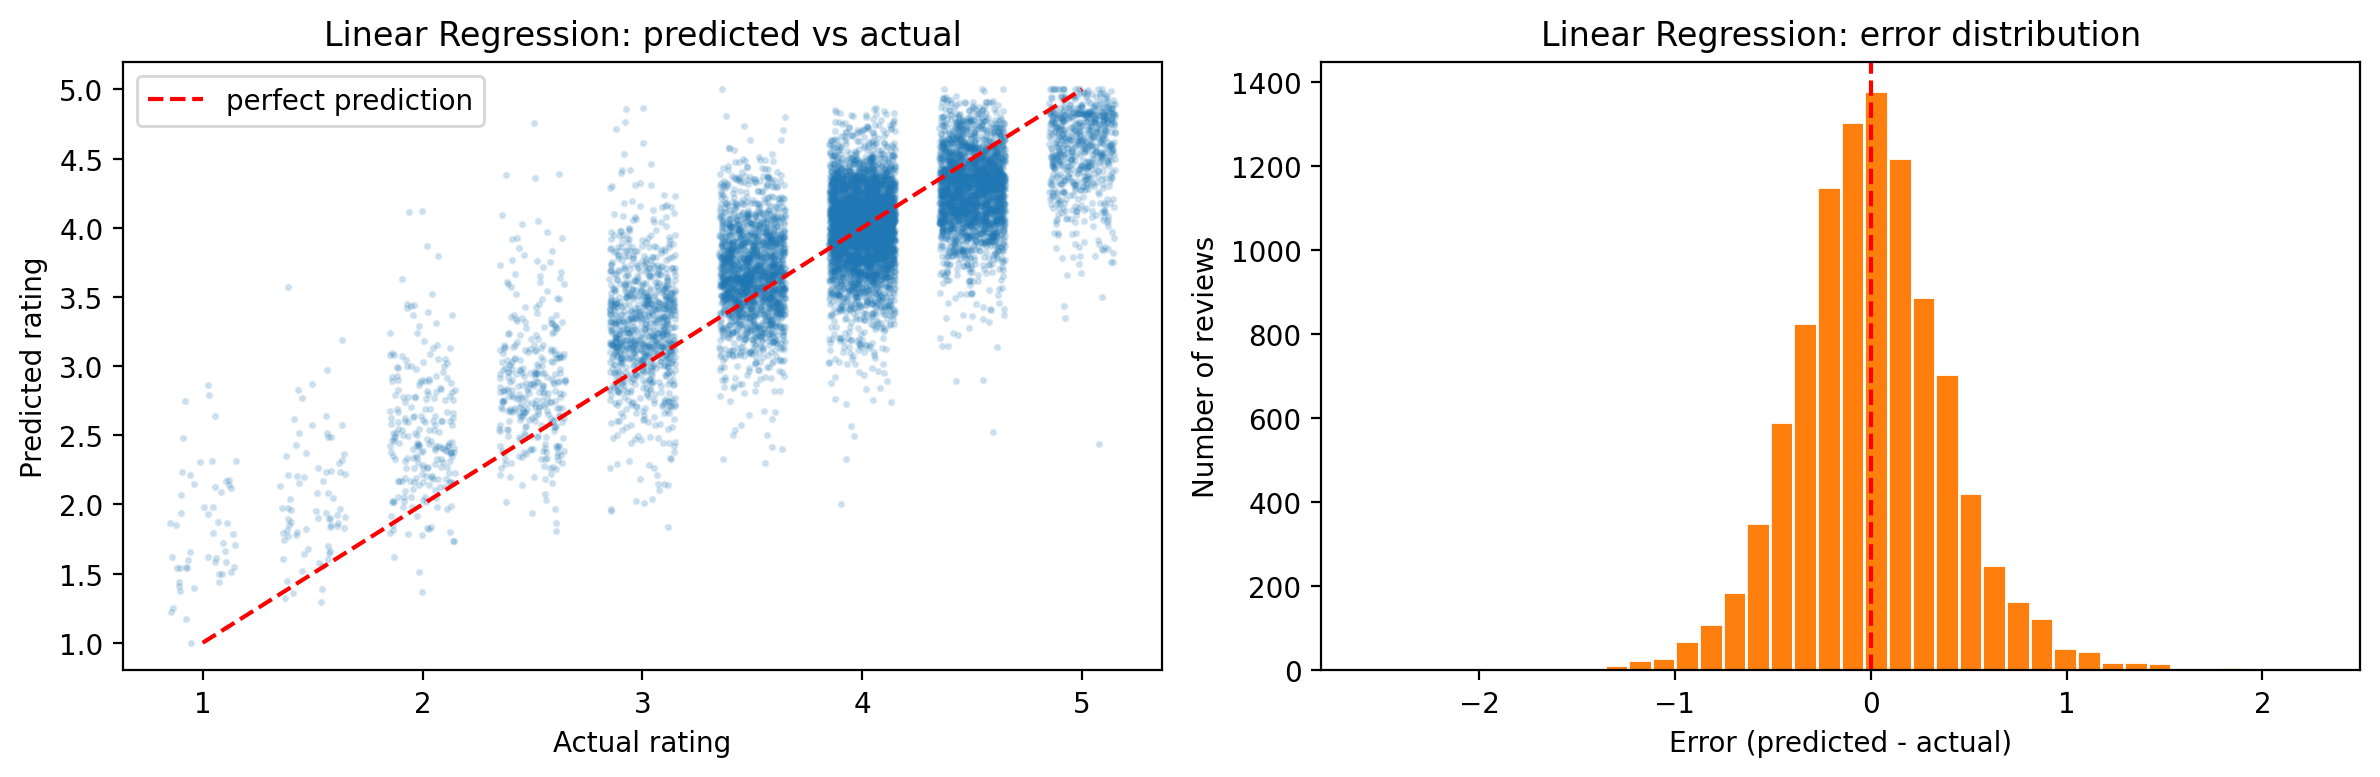

In [ ]:
models["Linear Regression"] = make_pipeline(StandardScaler(), LinearRegression())
models["Linear Regression"].fit(X_train, y_train)

pred = np.clip(models["Linear Regression"].predict(X_test), 1, 5)   # ratings live between 1 and 5
predictions["Linear Regression"] = pred
results["Linear Regression"] = show_model_results("Linear Regression", y_test, pred)

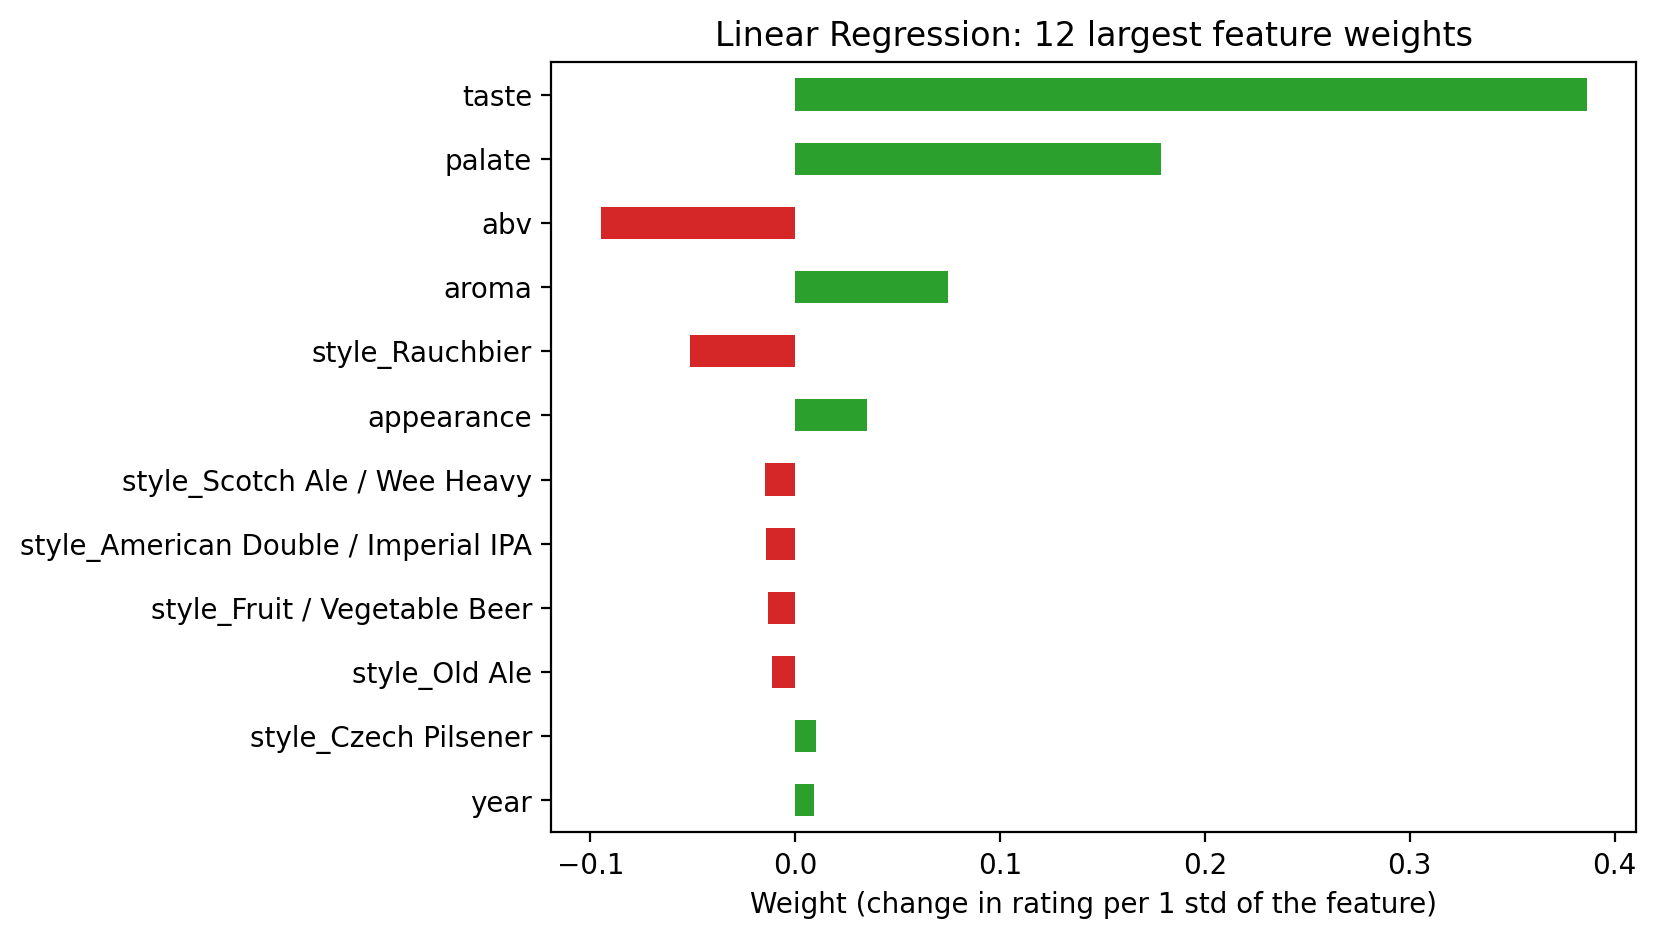

In [ ]:
# what did LR learn? weight of each (standardized) feature:
# positive = pushes the rating up, negative = pushes it down
weights = pd.Series(models["Linear Regression"][-1].coef_, index=X_train.columns)
top = weights.reindex(weights.abs().sort_values().index).tail(12)
top.plot(kind="barh", figsize=(7, 5), color=["tab:red" if w < 0 else "tab:green" for w in top])
plt.title("Linear Regression: 12 largest feature weights")
plt.xlabel("Weight (change in rating per 1 std of the feature)")
plt.show()

### Inside the trained Linear Regression

**Loss function (least squares / Mean Squared Error):**

$$L(w, b) = \frac{1}{n}\sum_{i=1}^{n}\left(y_i - \hat{y}_i\right)^2, \qquad \hat{y}_i = w \cdot x_i + b$$

Linear Regression finds the weights $w$ and bias $b$ that make this loss as small as possible. Unlike the neural network, it has an exact
solution, so no training loop or learning rate is needed. Below: the learned equation, the number of parameters,
and the same "best line" picture as in the knowledge graph, but now drawn on the **real** data.

In [ ]:
lr_pipe = models["Linear Regression"]
lr_scaler, lr = lr_pipe[0], lr_pipe[-1]

train_mse = mean_squared_error(y_train, lr_pipe.predict(X_train))
print("Loss function:   L(w, b) = (1/n) · Σ (yᵢ − ŷᵢ)²      (Mean Squared Error)")
print(f"Training loss:   {train_mse:.4f}")
print(f"Parameters:      {lr.coef_.size} weights (one per feature) + 1 bias = {lr.coef_.size + 1} learned numbers\n")

# the model was trained on standardized features. convert the weights back to the
# original units so we can write the real equation (e.g. +1 taste point -> +w rating points)
w_orig = lr.coef_ / lr_scaler.scale_
b_orig = lr.intercept_ - np.sum(lr.coef_ * lr_scaler.mean_ / lr_scaler.scale_)

eq = pd.DataFrame({"weight (original units)": w_orig, "weight (standardized)": lr.coef_}, index=X_train.columns)
eq = eq.reindex(eq["weight (standardized)"].abs().sort_values(ascending=False).index)

terms = " ".join(f"{'+' if w >= 0 else '−'} {abs(w):.3f}·{f}" for f, w in eq["weight (original units)"].head(5).items())
print("Learned equation (5 strongest features shown, original units):")
print(f"  ŷ = {b_orig:.3f} {terms} + ...\n")
display(eq.round(4))

Loss function:   L(w, b) = (1/n) · Σ (yᵢ − ŷᵢ)²      (Mean Squared Error)
Training loss:   0.1599
Parameters:      26 weights (one per feature) + 1 bias = 27 learned numbers

Learned equation (5 strongest features shown, original units):
  ŷ = -7.459 + 0.541·taste + 0.269·palate − 0.041·abv + 0.109·aroma − 0.264·style_Rauchbier + ...



,weight (original units),weight (standardized)
taste,0.5411,0.3866
palate,0.2686,0.1787
abv,-0.0408,-0.0949
aroma,0.1092,0.0745
style_Rauchbier,-0.2641,-0.0513
appearance,0.0596,0.0350
style_Scotch Ale / Wee Heavy,-0.0637,-0.0147
style_American Double / Imperial IPA,-0.0527,-0.0141
style_Fruit / Vegetable Beer,-0.0827,-0.0135
style_Old Ale,-0.0816,-0.0115


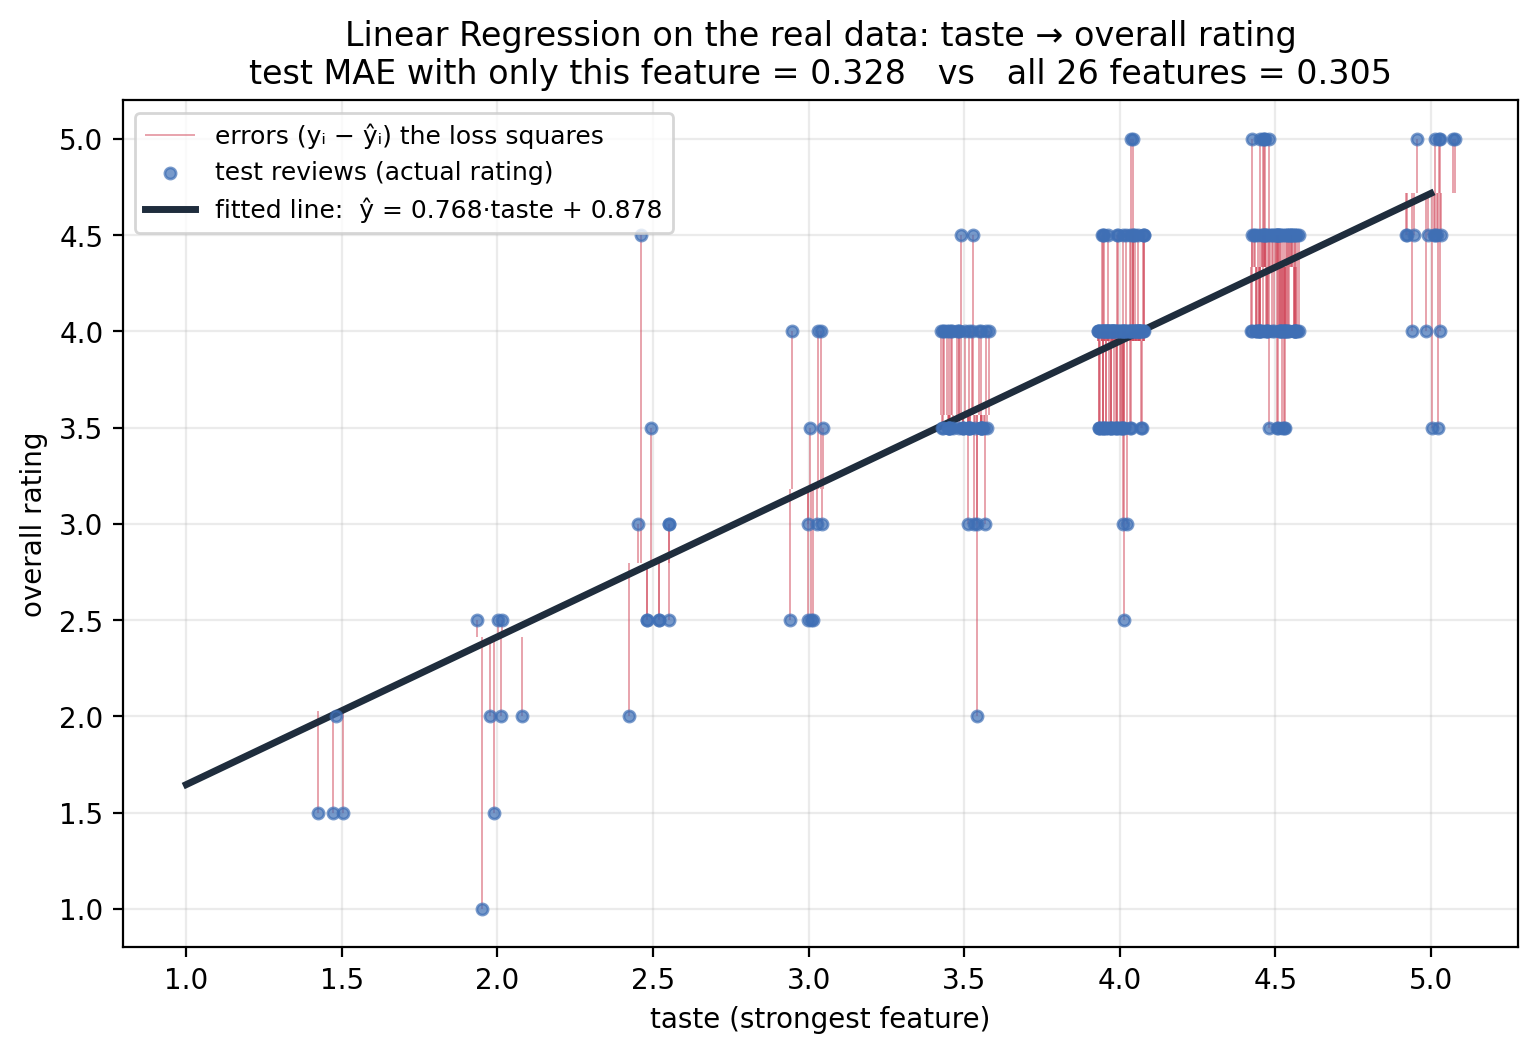

In [ ]:
# the "best straight line" on the real data, using the single strongest feature
feat = eq.index[0]
one = LinearRegression().fit(X_train[[feat]], y_train)
one_mae = mean_absolute_error(y_test, np.clip(one.predict(X_test[[feat]]), 1, 5))

rng = np.random.default_rng(0)
idx = rng.choice(len(X_test), size=min(300, len(X_test)), replace=False)   # 300 test reviews, so the plot stays readable
xs = X_test[feat].values[idx]
ys = y_test[idx]
ps = one.predict(X_test[[feat]].iloc[idx])
jx = xs + rng.uniform(-0.08, 0.08, len(xs))   # small jitter: scores only take a few values

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.vlines(jx, ys, ps, color="#D1495B", lw=0.7, alpha=0.5, label="errors (yᵢ − ŷᵢ) the loss squares")
ax.scatter(jx, ys, s=16, color="#3F6FB5", alpha=0.7, zorder=3, label="test reviews (actual rating)")
line_x = np.linspace(X_train[feat].min(), X_train[feat].max(), 50)
ax.plot(line_x, one.predict(pd.DataFrame({feat: line_x})), color="#1F2D3D", lw=2.5,
        label=f"fitted line:  ŷ = {one.coef_[0]:.3f}·{feat} + {one.intercept_:.3f}")
ax.set_xlabel(f"{feat} (strongest feature)")
ax.set_ylabel("overall rating")
ax.set_title(f"Linear Regression on the real data: {feat} → overall rating\n"
             f"test MAE with only this feature = {one_mae:.3f}   vs   all {X_train.shape[1]} features = {results['Linear Regression']['MAE']:.3f}")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.25)
plt.show()

---
## 5. Algorithm 2 – Decision Tree (DT)

**How it works**
The tree asks a series of yes/no questions about the features, e.g. *"taste ≤ 3.75?"*.
Each split is chosen so that the ratings inside each group become as similar as possible (lowest squared error).
A new review travels down the tree to a **leaf**, and the prediction is the **average rating of the training reviews in that leaf**.

**Why it suits this problem**
It can capture non-linear rules (e.g. "taste matters more when aroma is low") and works with numbers and one-hot categories without scaling.

**Settings:** `max_depth=10`, `min_samples_leaf=20` – a fully grown tree would memorize the training data (overfitting).

| Strengths | Weaknesses |
|-----------|-----------|
| captures non-linear rules | predictions are "steps" (one value per leaf) |
| no scaling needed, shows feature importance | overfits easily if too deep |

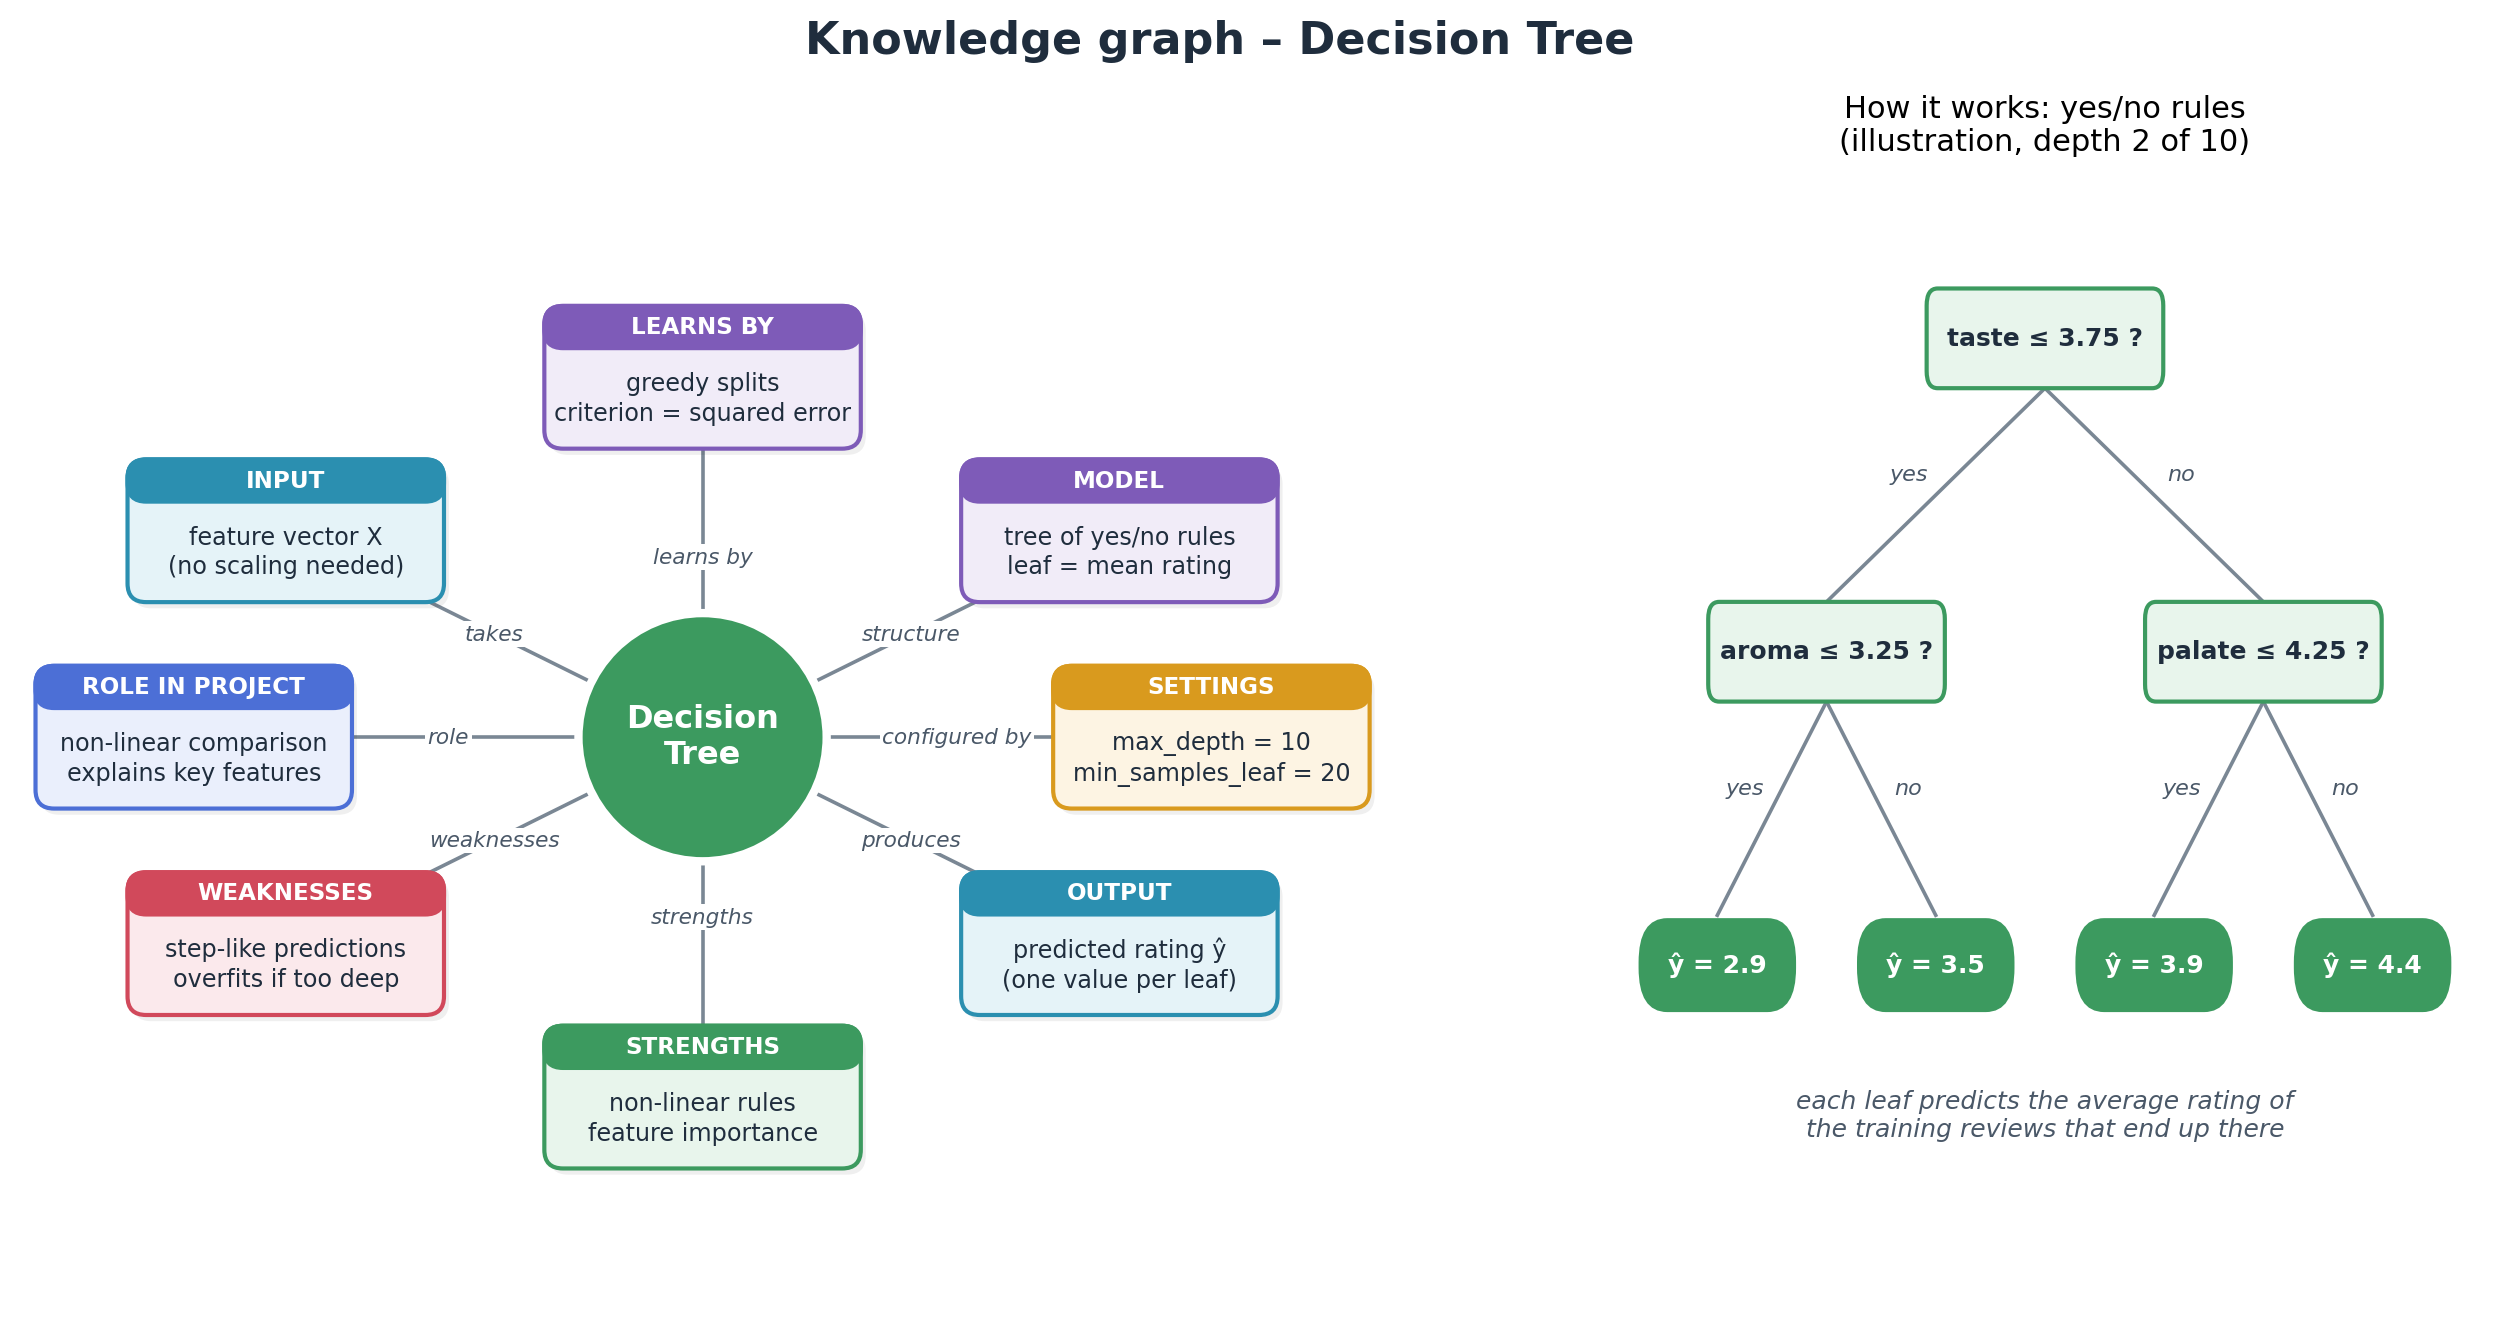

In [ ]:
# knowledge graph of Decision Tree: what it takes in, how it learns, its settings, output, strengths and weaknesses
draw_algorithm_graph("Decision Tree", "#3C9A5F", DT_INFO, illustrate_dt, "kg_decision_tree.png")

===== Decision Tree: test set results =====
  MAE       0.3066
  MSE       0.1645
  RMSE      0.4055
  MAPE (%)  8.7744
  82.1% of test reviews are predicted within ±0.5 of the actual rating


,Actual,Predicted,Error (pred - actual)
0,4.0,4.48,0.48
1,3.0,3.22,0.22
2,4.0,4.06,0.06
3,3.5,3.44,-0.06
4,3.0,3.46,0.46
5,5.0,4.10,-0.90
6,3.0,3.67,0.67
7,5.0,4.59,-0.41
8,3.0,3.46,0.46
9,4.0,4.15,0.15


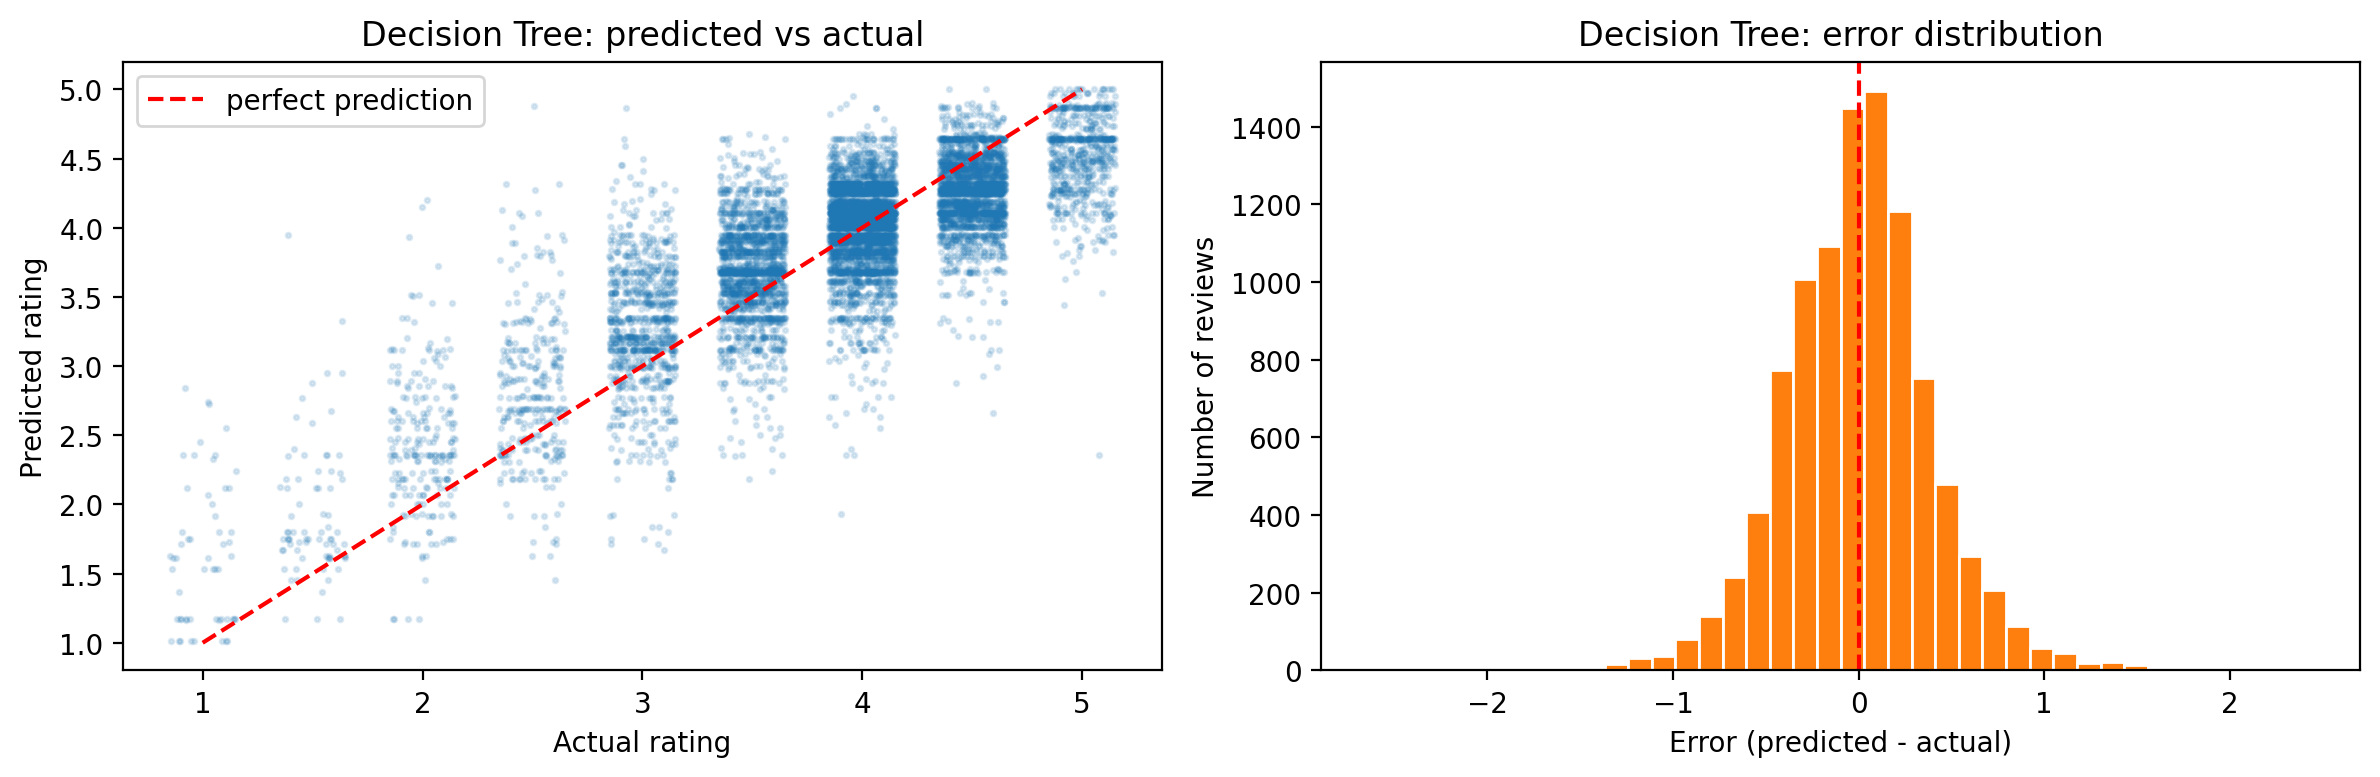

In [ ]:
models["Decision Tree"] = DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=42)
models["Decision Tree"].fit(X_train, y_train)

pred = np.clip(models["Decision Tree"].predict(X_test), 1, 5)
predictions["Decision Tree"] = pred
results["Decision Tree"] = show_model_results("Decision Tree", y_test, pred)

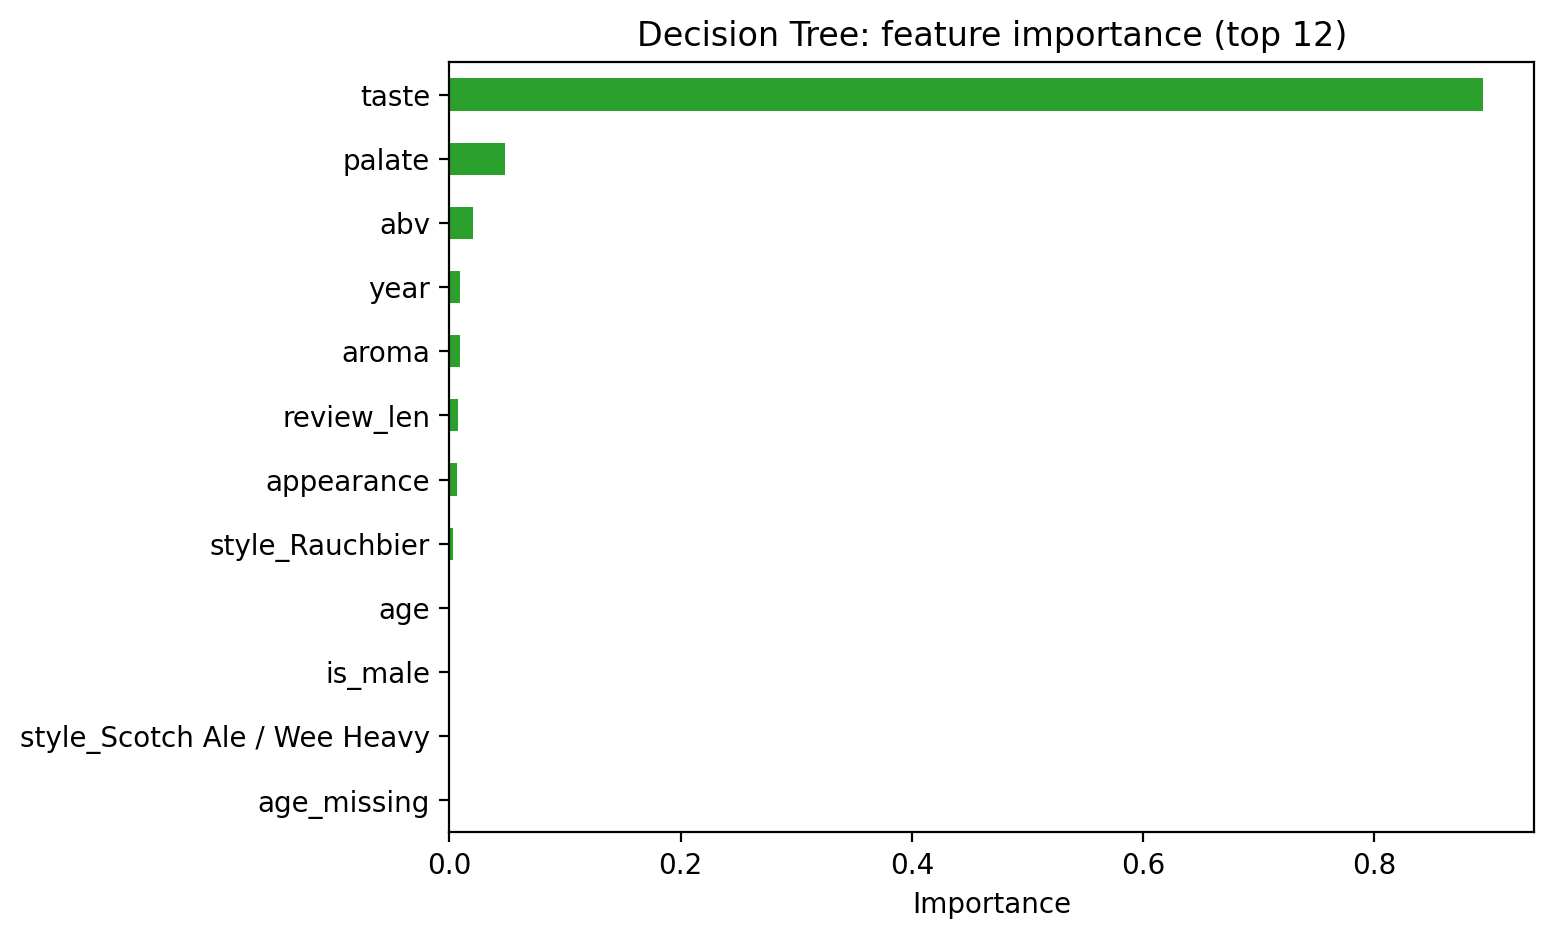

In [ ]:
# which features did the tree use the most for its splits?
importances = pd.Series(models["Decision Tree"].feature_importances_, index=X_train.columns).sort_values()
importances.tail(12).plot(kind="barh", figsize=(7, 5), color="tab:green")
plt.title("Decision Tree: feature importance (top 12)")
plt.xlabel("Importance")
plt.show()

### Inside the trained Decision Tree – loss and levels

**Loss / split criterion (squared error):** at every node the tree tries all features and thresholds and keeps the split that minimizes

$$\frac{n_{left}}{n}\,\text{MSE}_{left} + \frac{n_{right}}{n}\,\text{MSE}_{right}, \qquad \text{MSE}_{node} = \frac{1}{n_{node}}\sum_{i \in node}\left(y_i - \bar{y}_{node}\right)^2$$

A leaf predicts the mean rating $\bar{y}$ of its training reviews. The tree's "layers" are its **depth levels**: level 0 is the root,
and every split adds two nodes on the next level. Below: the size of every level, and the first levels drawn out.

Loss / split criterion:  squared error (MSE), weighted over the two child nodes
Leaf prediction:         mean rating of the training reviews in that leaf
Training loss (MSE):     0.1478
Depth: 10   |   nodes: 925   |   splits (questions): 462   |   leaves (final predictions): 463



,nodes,splits,leaves,avg_reviews_per_node,max possible (2^level)
level,,,,,
0,1,1,0,39997,1
1,2,2,0,19998,2
2,4,4,0,9999,4
3,8,8,0,5000,8
4,16,16,0,2500,16
5,32,32,0,1250,32
6,64,51,13,625,64
7,102,84,18,389,128
8,168,115,53,233,256


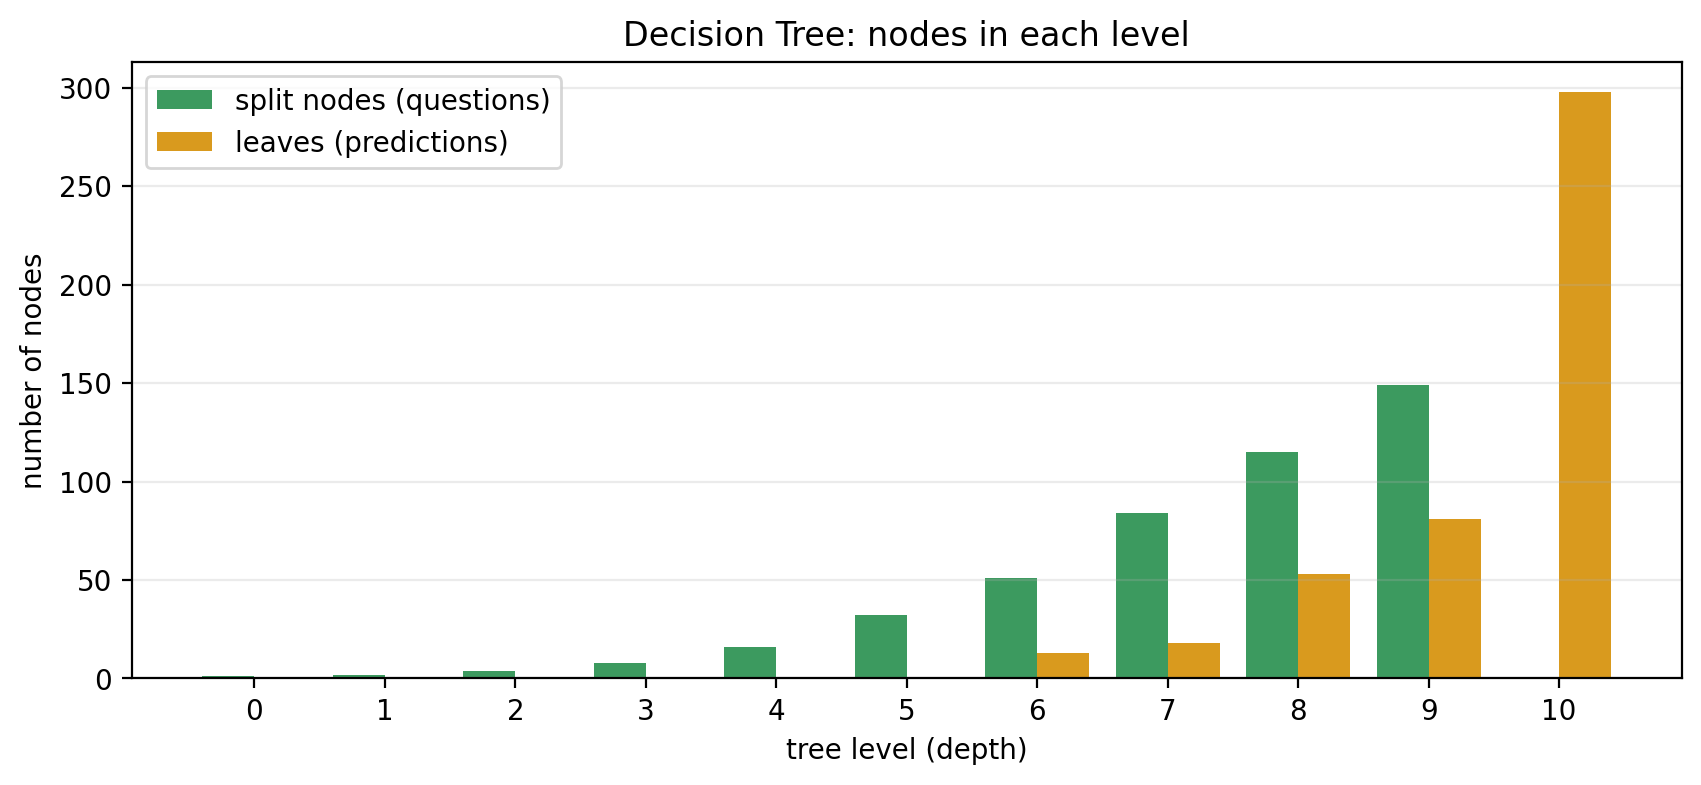

In [ ]:
from sklearn.tree import plot_tree, export_text

tree = models["Decision Tree"]
t = tree.tree_

print("Loss / split criterion:  squared error (MSE), weighted over the two child nodes")
print("Leaf prediction:         mean rating of the training reviews in that leaf")
print(f"Training loss (MSE):     {mean_squared_error(y_train, tree.predict(X_train)):.4f}")
print(f"Depth: {tree.get_depth()}   |   nodes: {t.node_count}   |   splits (questions): {t.node_count - tree.get_n_leaves()}"
      f"   |   leaves (final predictions): {tree.get_n_leaves()}\n")

# find the depth of every node by walking down from the root
depth = np.zeros(t.node_count, dtype=int)
stack = [(0, 0)]
while stack:
    node, d = stack.pop()
    depth[node] = d
    if t.children_left[node] != -1:
        stack += [(t.children_left[node], d + 1), (t.children_right[node], d + 1)]

is_leaf = t.children_left == -1
levels = pd.DataFrame({"level": depth, "leaf": is_leaf, "samples": t.n_node_samples}).groupby("level").agg(
    nodes=("leaf", "size"), splits=("leaf", lambda s: int((~s).sum())), leaves=("leaf", "sum"),
    avg_reviews_per_node=("samples", "mean"))
levels["max possible (2^level)"] = 2 ** levels.index
levels["avg_reviews_per_node"] = levels["avg_reviews_per_node"].round(0).astype(int)
display(levels)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(levels.index - 0.2, levels["splits"], width=0.4, label="split nodes (questions)", color="#3C9A5F")
ax.bar(levels.index + 0.2, levels["leaves"], width=0.4, label="leaves (predictions)", color="#D99A1E")
ax.set_xlabel("tree level (depth)")
ax.set_ylabel("number of nodes")
ax.set_title("Decision Tree: nodes in each level")
ax.set_xticks(levels.index)
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.show()

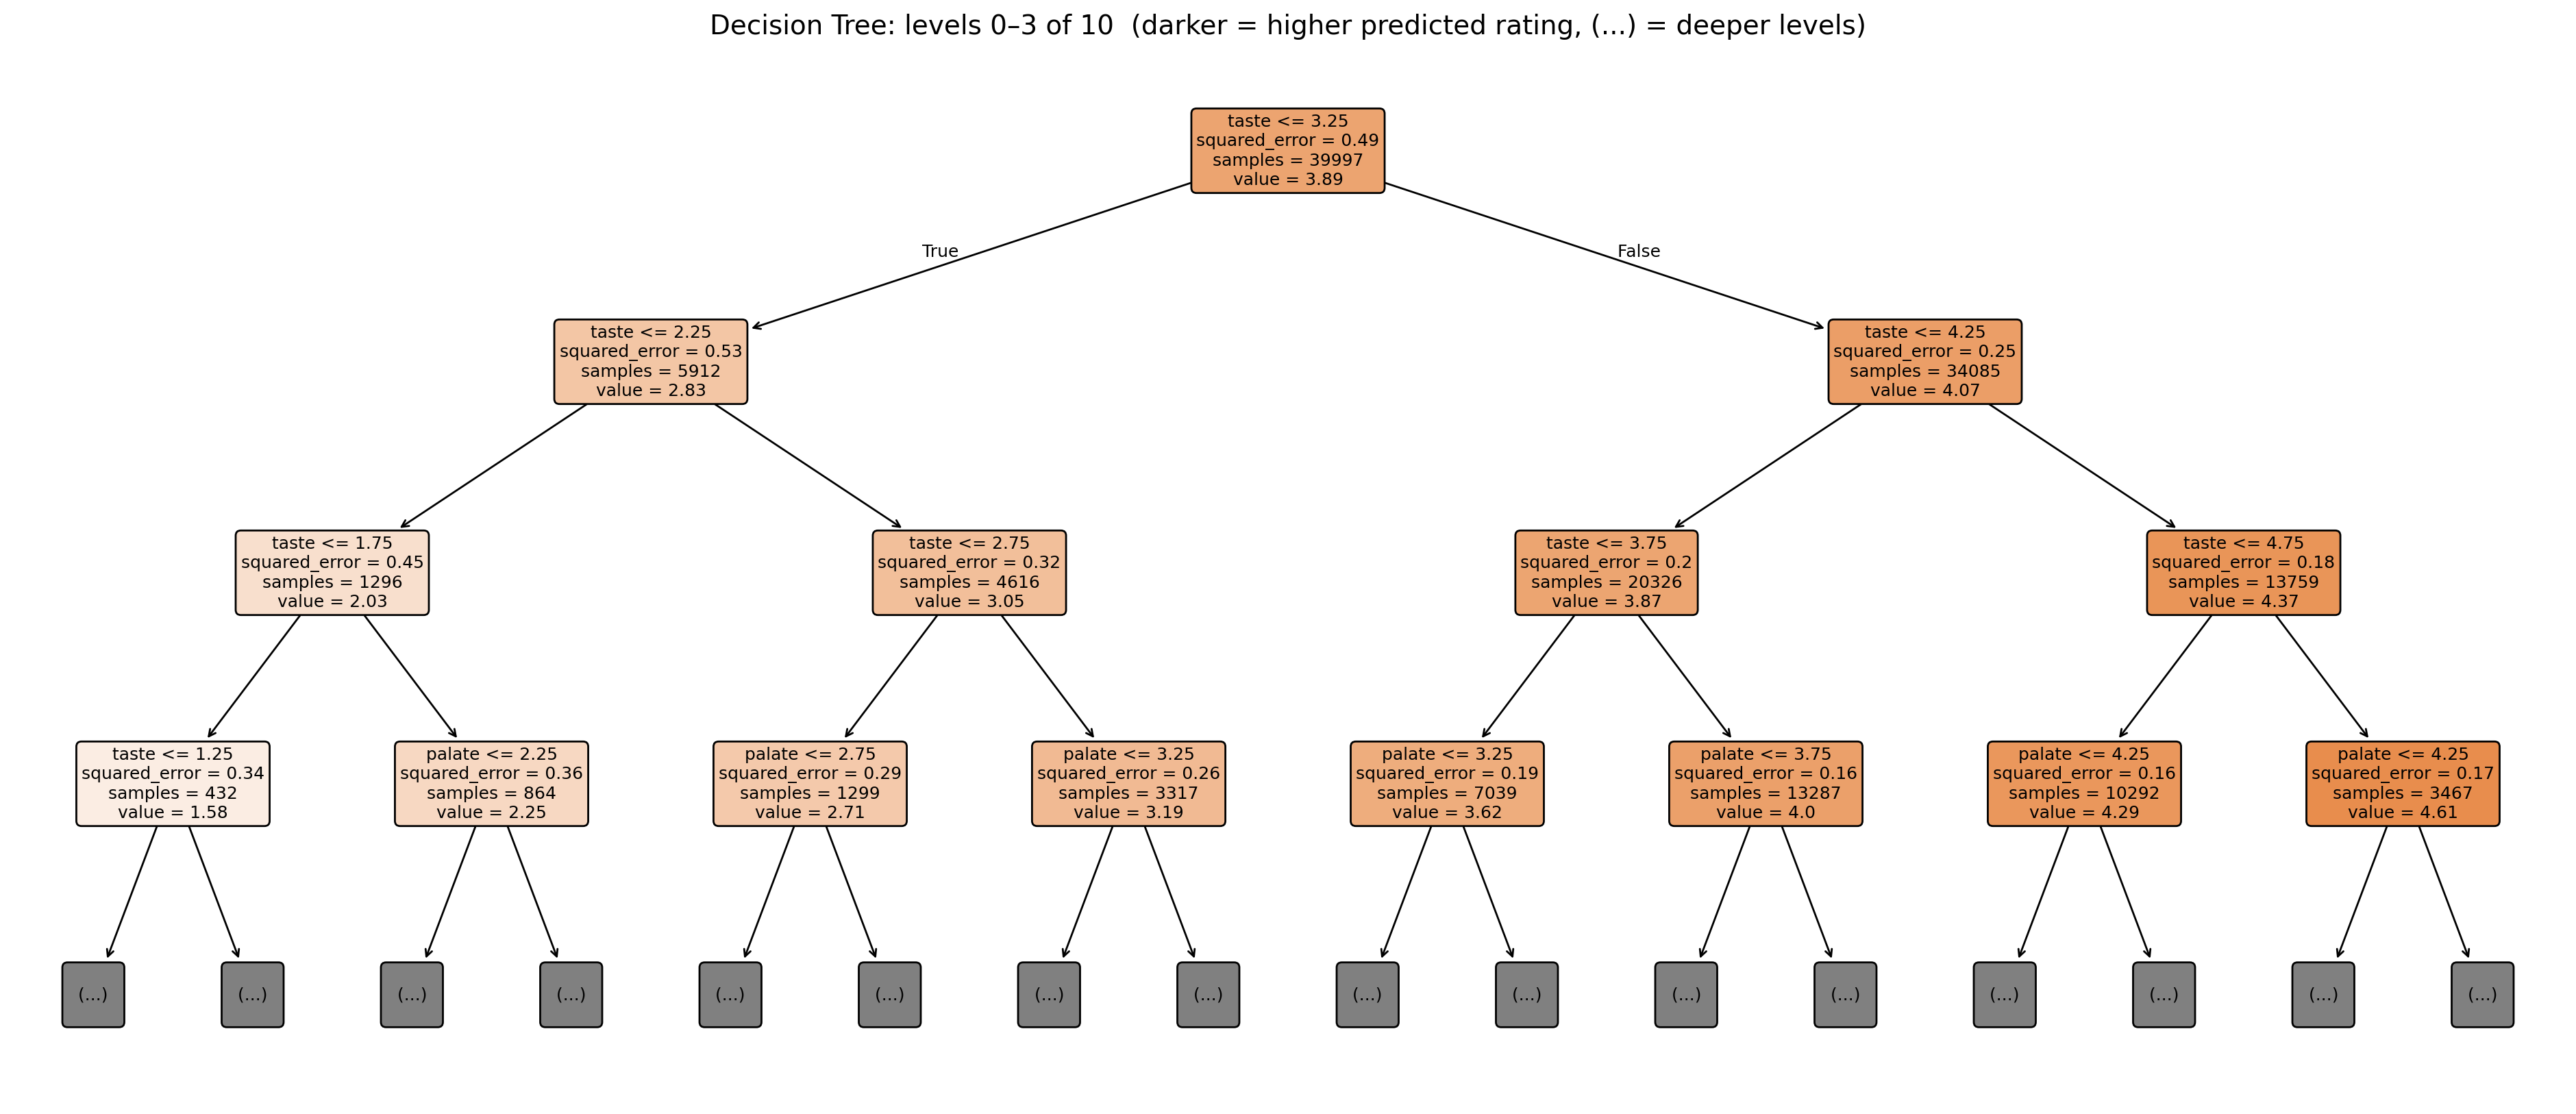

|--- taste <= 3.25
|   |--- taste <= 2.25
|   |   |--- taste <= 1.75
|   |   |   |--- truncated branch of depth 7
|   |   |--- taste >  1.75
|   |   |   |--- truncated branch of depth 8
|   |--- taste >  2.25
|   |   |--- taste <= 2.75
|   |   |   |--- truncated branch of depth 8
|   |   |--- taste >  2.75
|   |   |   |--- truncated branch of depth 8
|--- taste >  3.25
|   |--- taste <= 4.25
|   |   |--- taste <= 3.75
|   |   |   |--- truncated branch of depth 8
|   |   |--- taste >  3.75
|   |   |   |--- truncated branch of depth 8
|   |--- taste >  4.25
|   |   |--- taste <= 4.75
|   |   |   |--- truncated branch of depth 8
|   |   |--- taste >  4.75
|   |   |   |--- truncated branch of depth 8



In [ ]:
# the top of the real tree. each box shows: the question, squared_error (MSE in that node),
# samples (training reviews reaching it) and value (the mean rating = prediction)
plt.figure(figsize=(24, 10))
plot_tree(tree, max_depth=3, feature_names=list(X_train.columns), filled=True, rounded=True,
          fontsize=9, precision=2, impurity=True)
plt.title(f"Decision Tree: levels 0–3 of {tree.get_depth()}  (darker = higher predicted rating, (...) = deeper levels)", fontsize=14)
plt.show()

# the same rules as text
print(export_text(tree, feature_names=list(X_train.columns), max_depth=2, decimals=2))

---
## 6. Algorithm 3 – Neural Network (NN)

**How it works**
A multi-layer perceptron (MLP): layers of neurons, where each neuron takes a weighted sum of its inputs and passes it through a
non-linear activation function (ReLU). Our network is

`input features → 64 neurons → 32 neurons → 1 output (the rating)`

The weights are learned with **backpropagation + gradient descent** (Adam optimizer), minimizing the squared error.
With `early_stopping`, 10 % of the training data is held aside and training stops when the error there stops improving.

**Why it suits this problem**
It can learn curved relationships and interactions between features automatically, without us designing them.

**Settings:** features standardized, hidden layers (64, 32), early stopping, max 300 epochs.

| Strengths | Weaknesses |
|-----------|-----------|
| most flexible, learns non-linear patterns | needs scaling and more tuning |
| often the most accurate | harder to interpret ("black box"), slower to train |

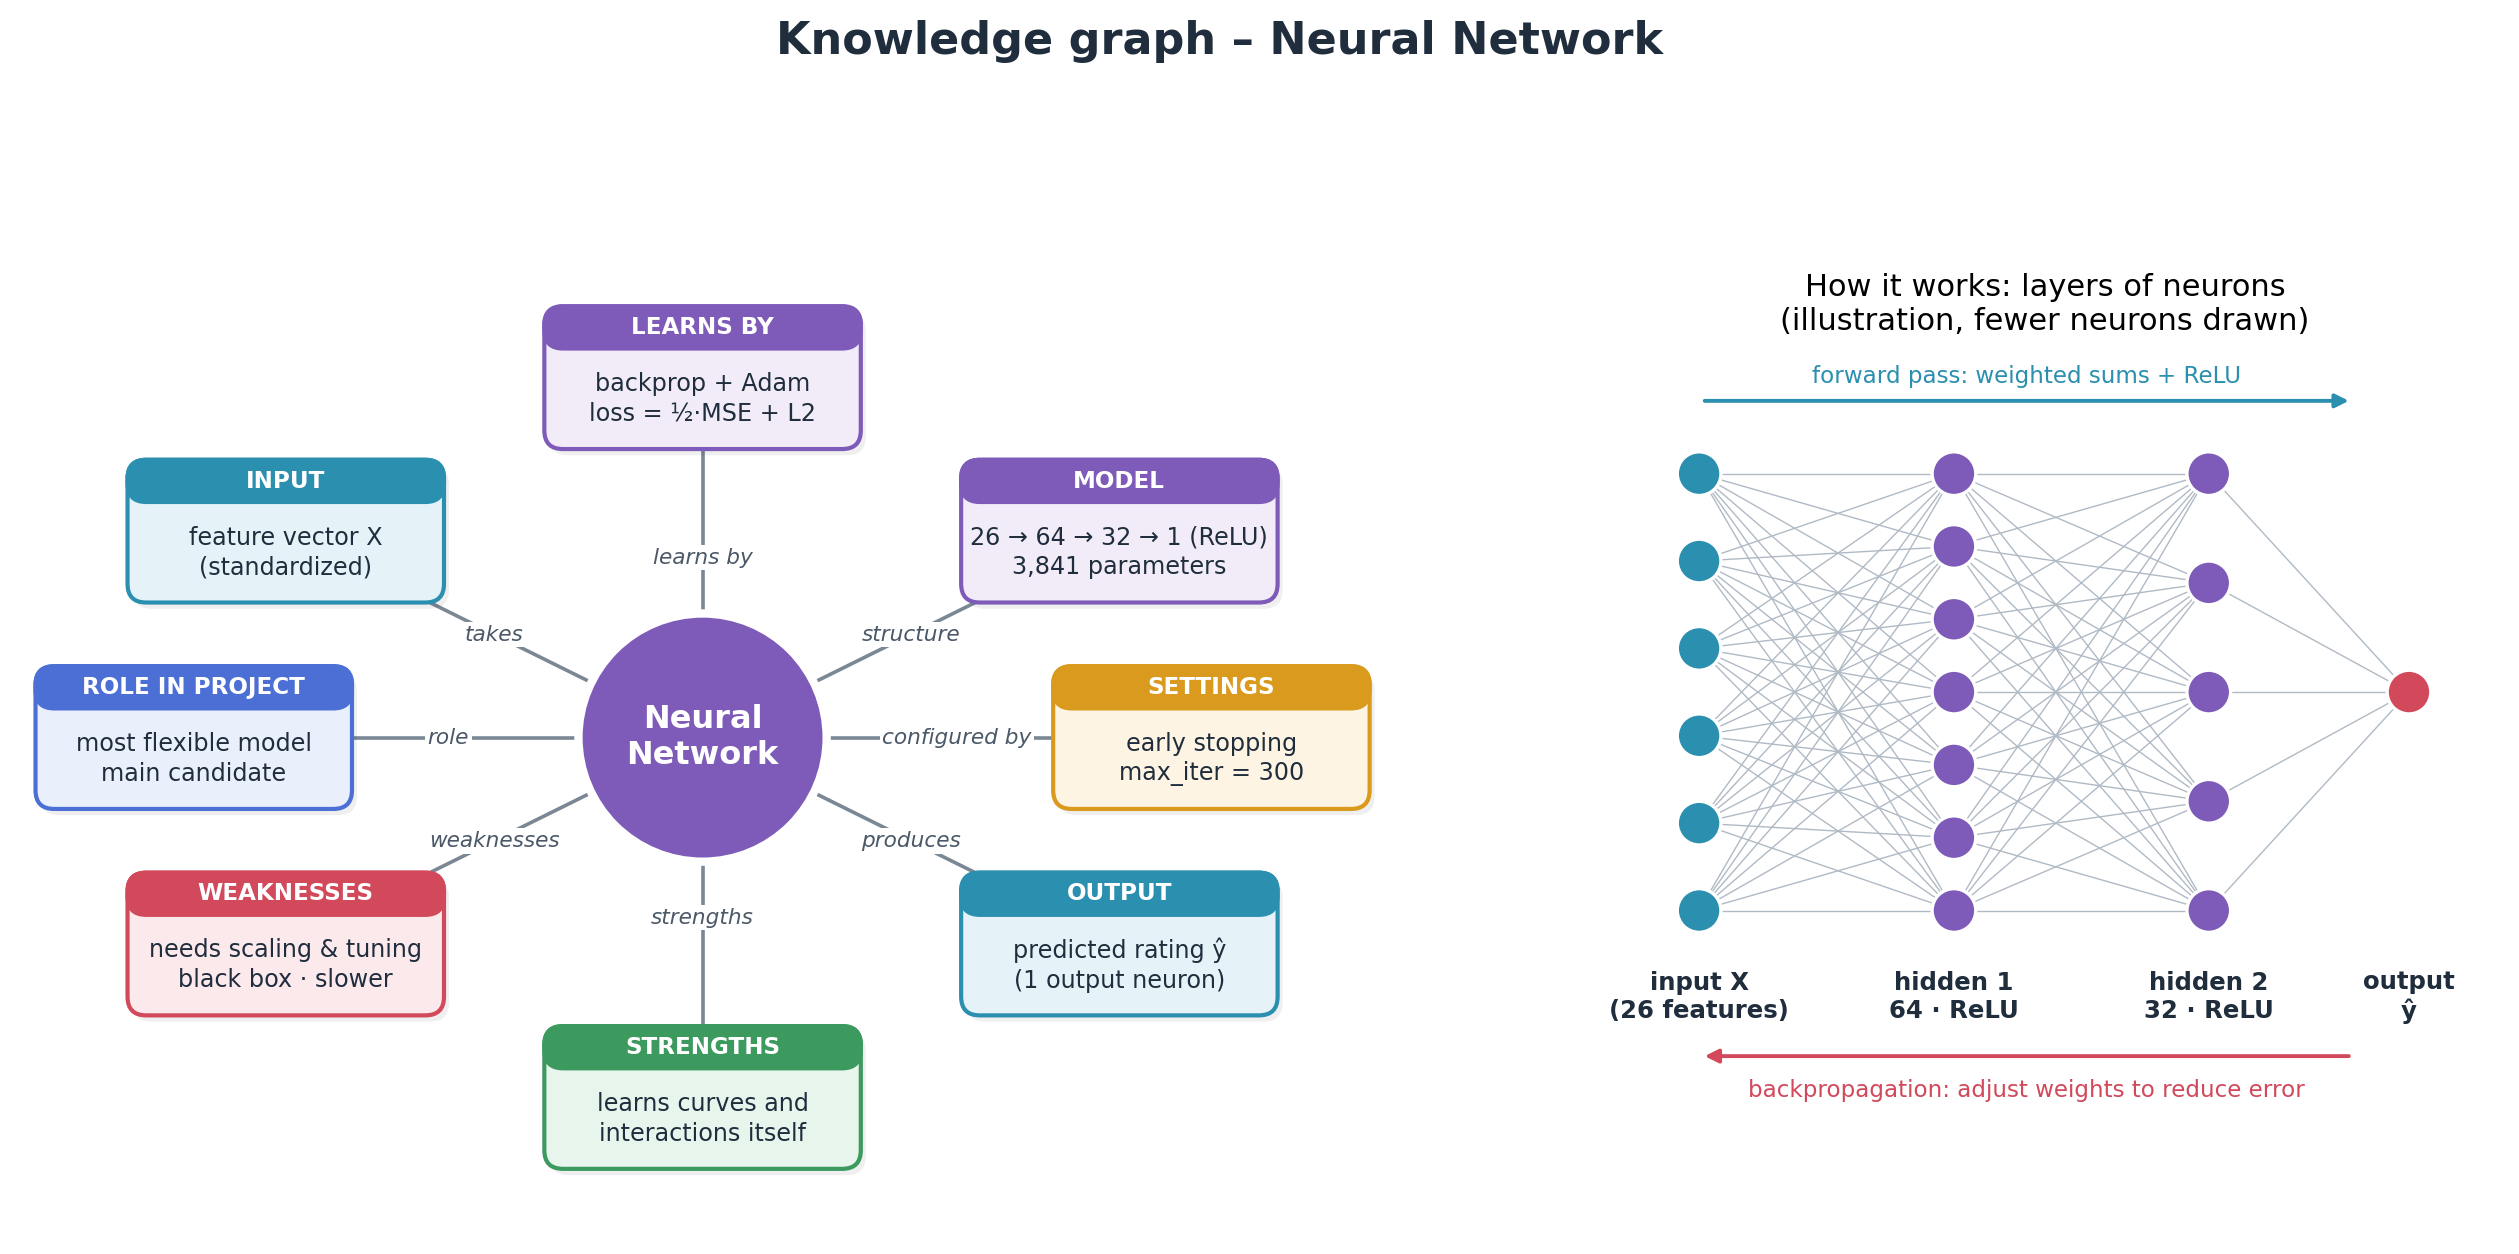

In [ ]:
# knowledge graph of Neural Network: what it takes in, how it learns, its settings, output, strengths and weaknesses
draw_algorithm_graph("Neural Network", "#7E5BB8", NN_INFO, illustrate_nn, "kg_neural_network.png")

===== Neural Network: test set results =====
  MAE       0.3055
  MSE       0.1608
  RMSE      0.4009
  MAPE (%)  8.8042
  82.1% of test reviews are predicted within ±0.5 of the actual rating


,Actual,Predicted,Error (pred - actual)
0,4.0,4.51,0.51
1,3.0,3.21,0.21
2,4.0,4.14,0.14
3,3.5,3.43,-0.07
4,3.0,3.34,0.34
5,5.0,4.21,-0.79
6,3.0,3.66,0.66
7,5.0,4.70,-0.30
8,3.0,3.21,0.21
9,4.0,4.20,0.20


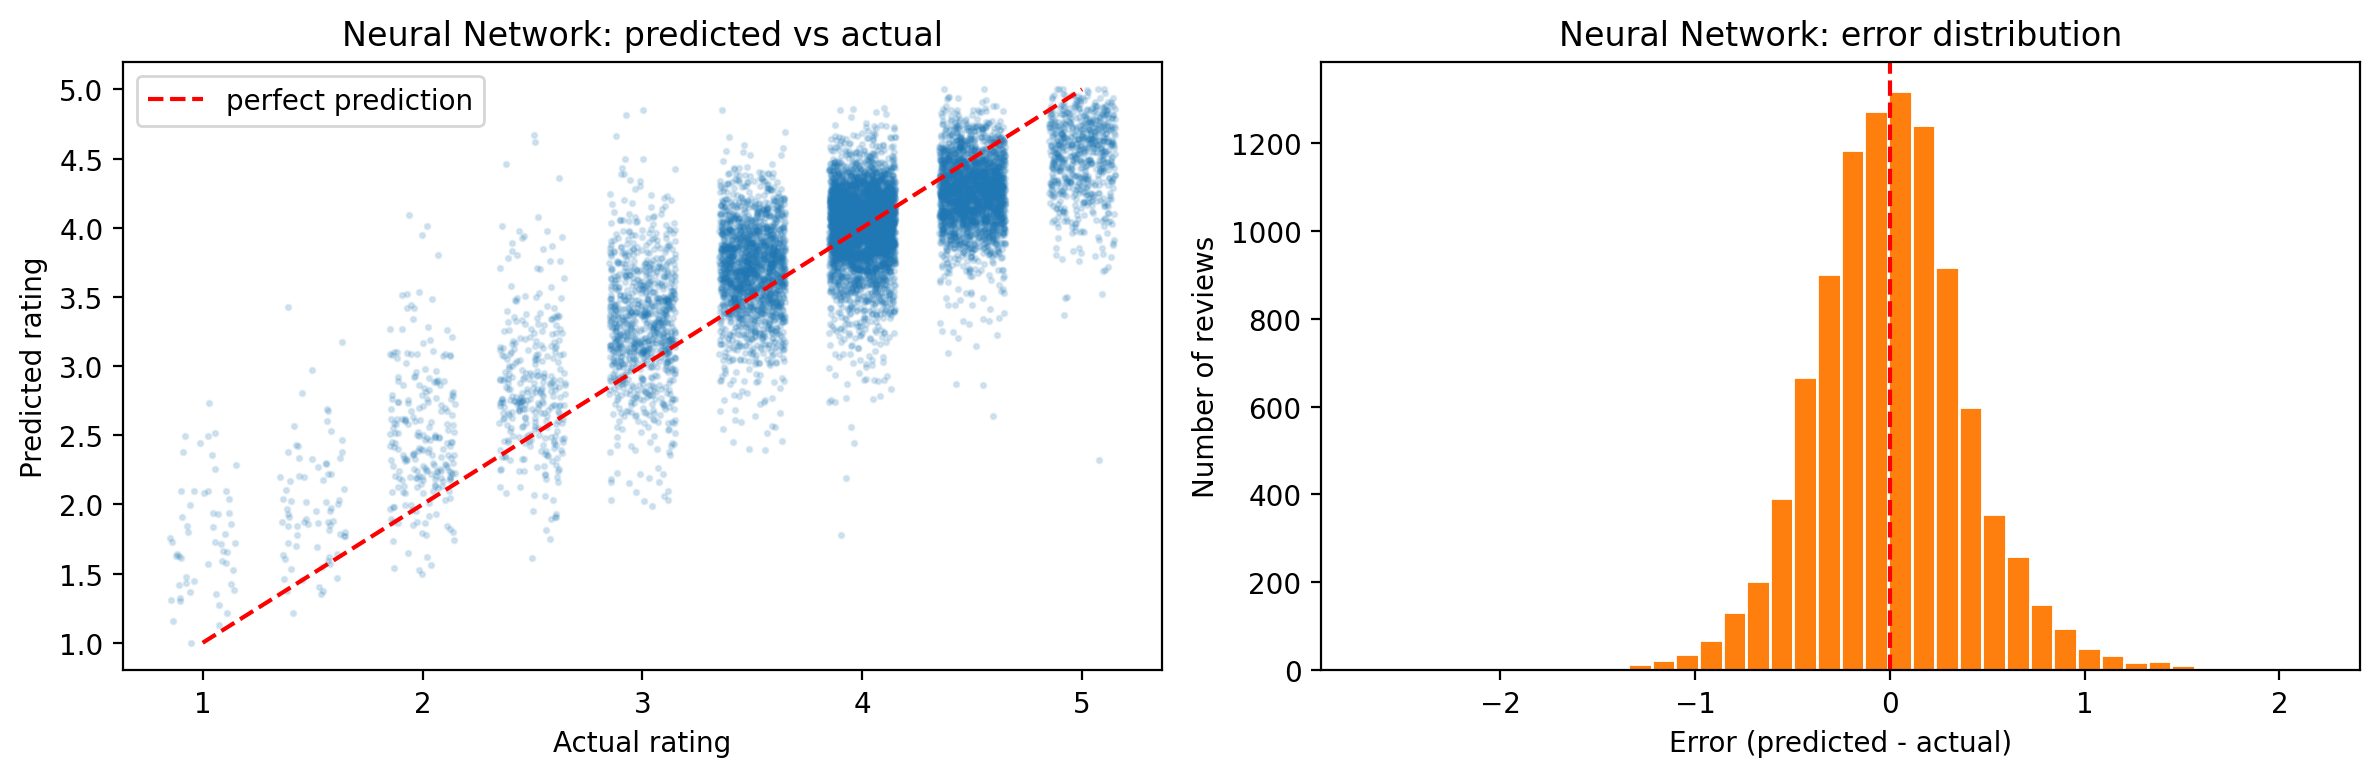

In [ ]:
models["Neural Network"] = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=300, random_state=42),
)
models["Neural Network"].fit(X_train, y_train)

pred = np.clip(models["Neural Network"].predict(X_test), 1, 5)
predictions["Neural Network"] = pred
results["Neural Network"] = show_model_results("Neural Network", y_test, pred)

### Inside the trained Neural Network – layers, parameters and loss

**Parameters per layer.** A fully connected layer with $n_{in}$ inputs and $n_{out}$ neurons has

$$\text{parameters} = \underbrace{n_{in} \times n_{out}}_{\text{weights}} + \underbrace{n_{out}}_{\text{biases}}$$

because every neuron has one weight for each input plus its own bias.

**Loss function** (scikit-learn `MLPRegressor`, squared error with L2 regularization, $\alpha$ = 0.0001):

$$L = \frac{1}{2n}\sum_{i=1}^{n}\left(y_i - \hat{y}_i\right)^2 \;+\; \frac{\alpha}{2n}\sum \lVert W \rVert^2$$

The first term is half the Mean Squared Error; the second keeps the weights small so the network doesn't overfit.
Adam uses backpropagation to compute how each weight changes the loss and updates the weights in small steps.

In [ ]:
mlp = models["Neural Network"][-1]

layer_names = ["Input"] + [f"Hidden {i + 1}" for i in range(len(mlp.hidden_layer_sizes))] + ["Output"]
activations = [mlp.activation] * len(mlp.hidden_layer_sizes) + [mlp.out_activation_]

rows = [{"Layer": "Input", "Neurons": X_train.shape[1], "Activation": "–", "Calculation": "– (just the features)",
         "Weights": 0, "Biases": 0, "Parameters": 0}]
for name, act, W, b in zip(layer_names[1:], activations, mlp.coefs_, mlp.intercepts_):
    rows.append({"Layer": name, "Neurons": W.shape[1], "Activation": act,
                 "Calculation": f"{W.shape[0]} × {W.shape[1]} + {b.size}",
                 "Weights": W.size, "Biases": b.size, "Parameters": W.size + b.size})
arch = pd.DataFrame(rows)
total = arch[["Weights", "Biases", "Parameters"]].sum()
arch.loc[len(arch)] = ["TOTAL", "", "", "", total["Weights"], total["Biases"], total["Parameters"]]

print(f"Network: {' → '.join(str(n) for n in arch['Neurons'][:-1])}")
display(arch.style.hide(axis="index").set_caption("Neural Network: neurons and trainable parameters per layer"))
print(f"Total trainable parameters: {total['Parameters']:,}   "
      f"(Linear Regression has {X_train.shape[1] + 1}, for comparison)")

Network: 26 → 64 → 32 → 1


Layer,Neurons,Activation,Calculation,Weights,Biases,Parameters
Input,26,–,– (just the features),0,0,0
Hidden 1,64,relu,26 × 64 + 64,1664,64,1728
Hidden 2,32,relu,64 × 32 + 32,2048,32,2080
Output,1,identity,32 × 1 + 1,32,1,33
TOTAL,,,,3744,97,3841


Total trainable parameters: 3,841   (Linear Regression has 27, for comparison)


In [ ]:
n_batch = min(200, len(X_train))
print("Loss function:     L = 1/(2n) · Σ (yᵢ − ŷᵢ)²  +  α/(2n) · Σ‖W‖²     (½·MSE + L2 penalty)")
print(f"  α (L2 strength): {mlp.alpha}")
print(f"Optimizer:         {mlp.solver}  ·  learning rate {mlp.learning_rate_init}  ·  mini-batches of {n_batch} reviews")
print(f"Hidden activation: {mlp.activation}  →  f(z) = max(0, z)")
print(f"Output activation: {mlp.out_activation_}  →  ŷ = z (any real number, which suits a rating)")
print(f"Early stopping:    {mlp.validation_fraction:.0%} of the training data held out for validation, "
      f"stop after {mlp.n_iter_no_change} epochs without improvement")
print(f"Epochs trained:    {mlp.n_iter_}")
print(f"Final training loss: {mlp.loss_:.4f}   (≈ MSE / 2  →  training MSE ≈ {2 * mlp.loss_:.4f}, plus the tiny L2 term)")
print(f"Best validation R²:  {mlp.best_validation_score_:.4f}")

Loss function:     L = 1/(2n) · Σ (yᵢ − ŷᵢ)²  +  α/(2n) · Σ‖W‖²     (½·MSE + L2 penalty)
  α (L2 strength): 0.0001
Optimizer:         adam  ·  learning rate 0.001  ·  mini-batches of 200 reviews
Hidden activation: relu  →  f(z) = max(0, z)
Output activation: identity  →  ŷ = z (any real number, which suits a rating)
Early stopping:    10% of the training data held out for validation, stop after 10 epochs without improvement
Epochs trained:    32
Final training loss: 0.0768   (≈ MSE / 2  →  training MSE ≈ 0.1535, plus the tiny L2 term)
Best validation R²:  0.6652


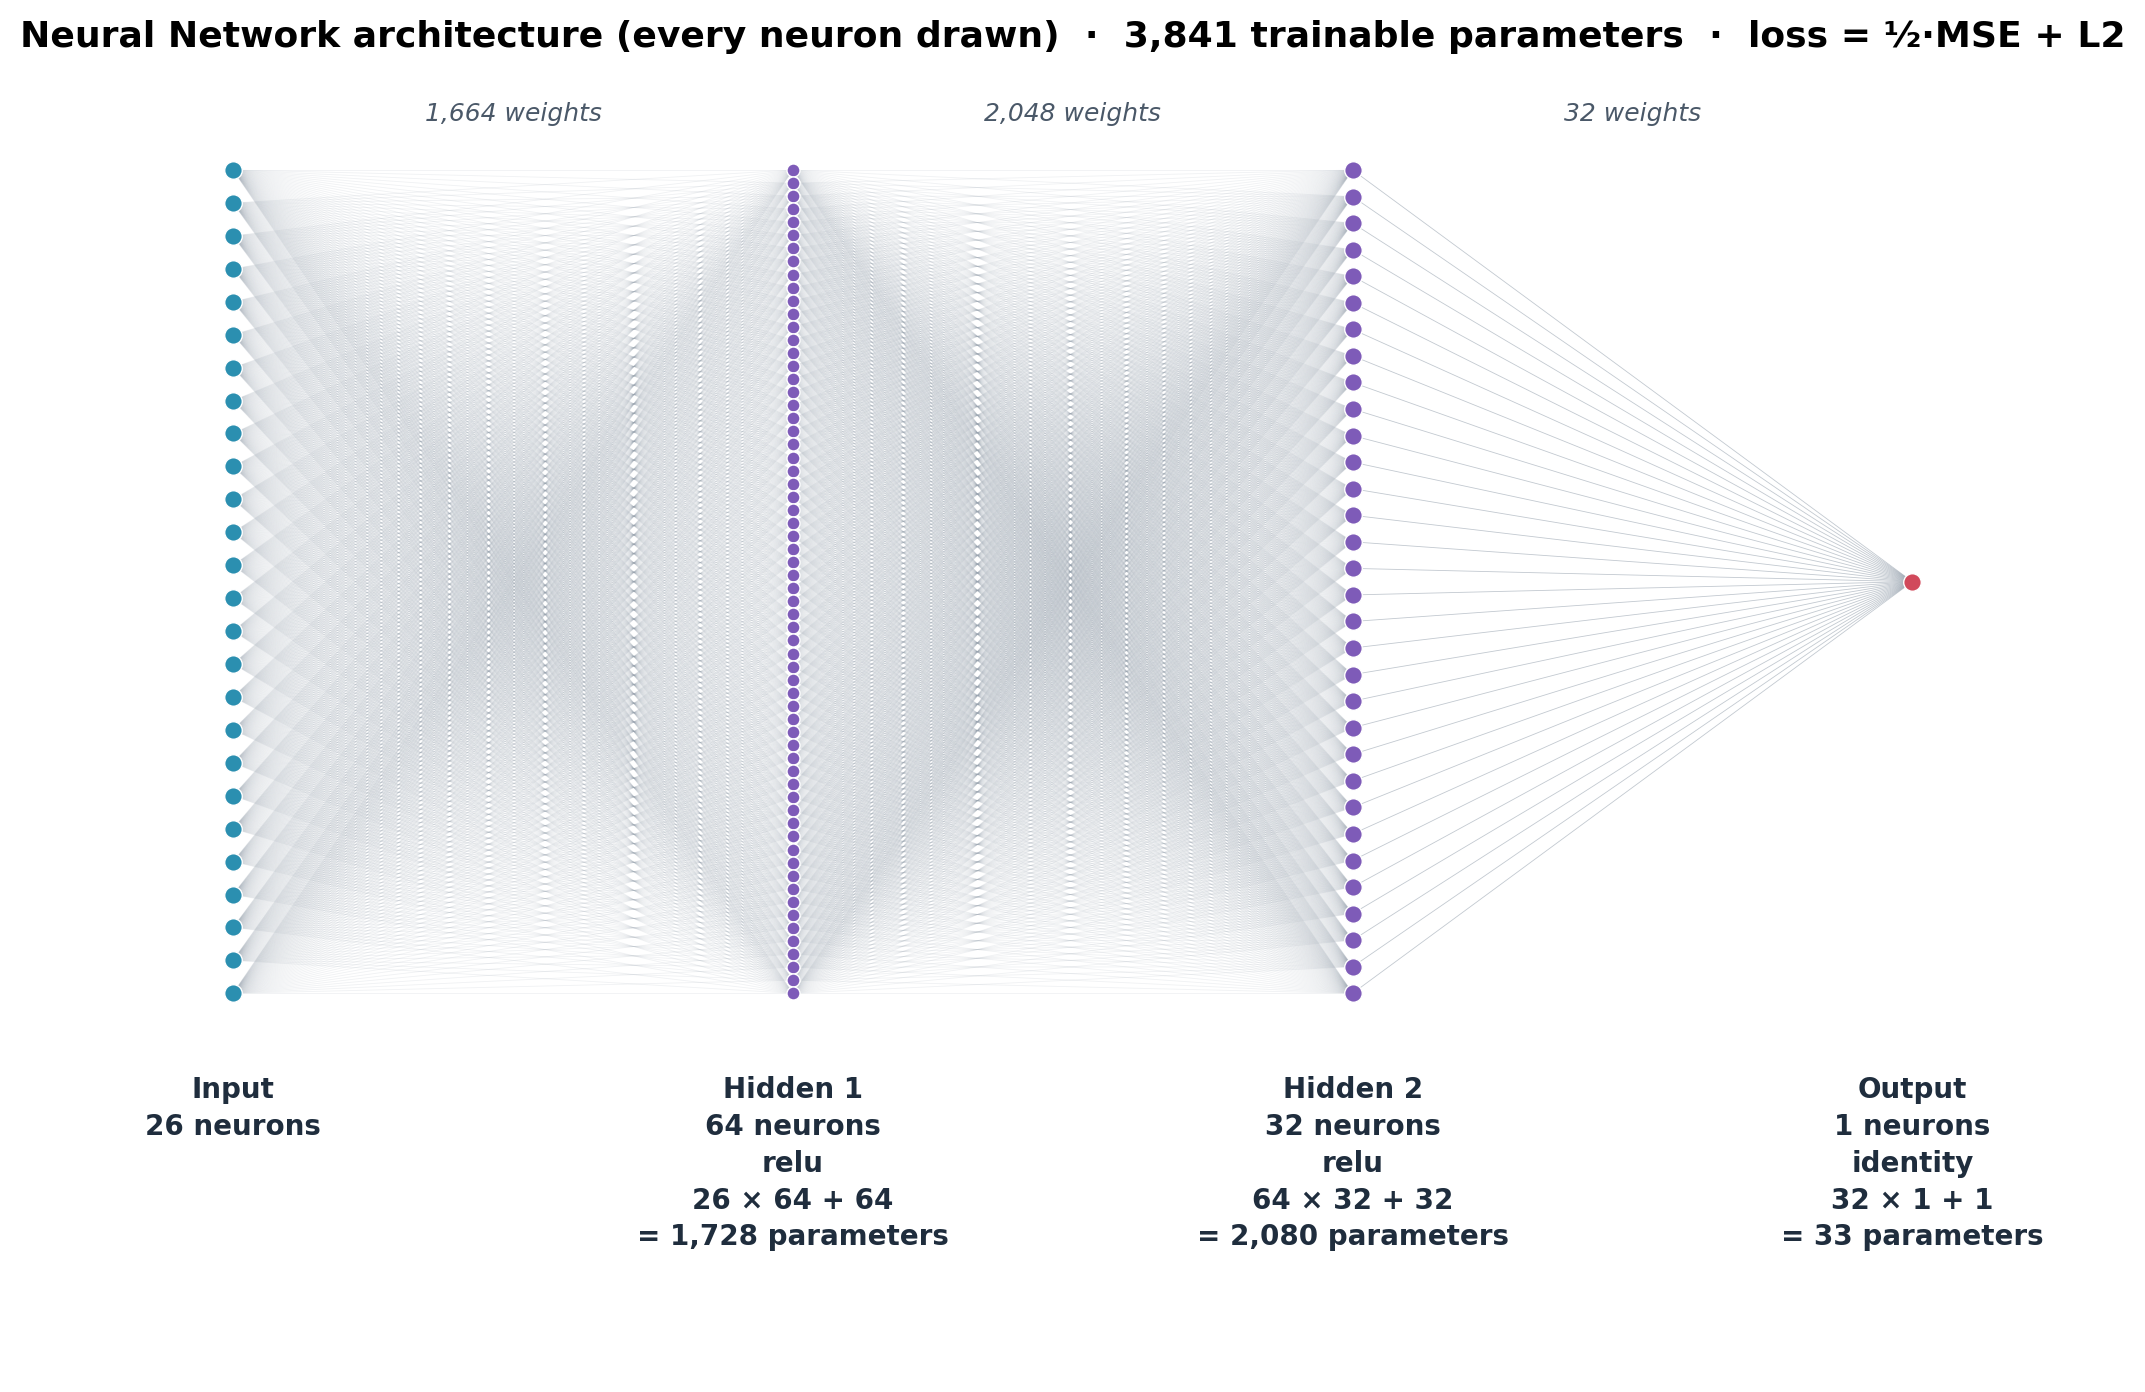

In [ ]:
# the real network, drawn with every neuron. each line is one weight
sizes = [X_train.shape[1]] + list(mlp.hidden_layer_sizes) + [1]
colors_l = ["#2B8FB0"] + ["#7E5BB8"] * len(mlp.hidden_layer_sizes) + ["#D1495B"]
xs_l = np.linspace(0, 10, len(sizes))
H = 10

fig, ax = plt.subplots(figsize=(13, 8.5))
pos = [np.column_stack([np.full(n, x), np.linspace(H, 0, n) if n > 1 else [H / 2]]) for x, n in zip(xs_l, sizes)]
for a, b in zip(pos[:-1], pos[1:]):
    for p in a:
        ax.plot(np.c_[np.full(len(b), p[0]), b[:, 0]].T, np.c_[np.full(len(b), p[1]), b[:, 1]].T,
                color="#9AA5B1", lw=0.3, alpha=0.6 if len(a) * len(b) < 200 else 0.15, zorder=1)
for pts, c in zip(pos, colors_l):
    ax.scatter(pts[:, 0], pts[:, 1], s=40 if len(pts) < 40 else 22, color=c, edgecolor="white", lw=0.5, zorder=3)

for i, (x, n) in enumerate(zip(xs_l, sizes)):
    r = arch.iloc[i]
    extra = "" if i == 0 else f"\n{r['Calculation']}\n= {r['Parameters']:,} parameters"
    ax.text(x, -1.0, f"{r['Layer']}\n{n} neurons\n{r['Activation'] if i else ''}{extra}",
            ha="center", va="top", fontsize=10, weight="bold", color="#1F2D3D", linespacing=1.4)
for i in range(1, len(sizes)):
    ax.text((xs_l[i - 1] + xs_l[i]) / 2, H + 0.6, f"{arch.iloc[i]['Weights']:,} weights", ha="center",
            fontsize=9, style="italic", color="#4A5868")
ax.set_xlim(-1, 11); ax.set_ylim(-4.6, H + 1.3); ax.axis("off")
ax.set_title(f"Neural Network architecture (every neuron drawn)  ·  {total['Parameters']:,} trainable parameters  ·  "
             f"loss = ½·MSE + L2", fontsize=13, weight="bold")
plt.show()

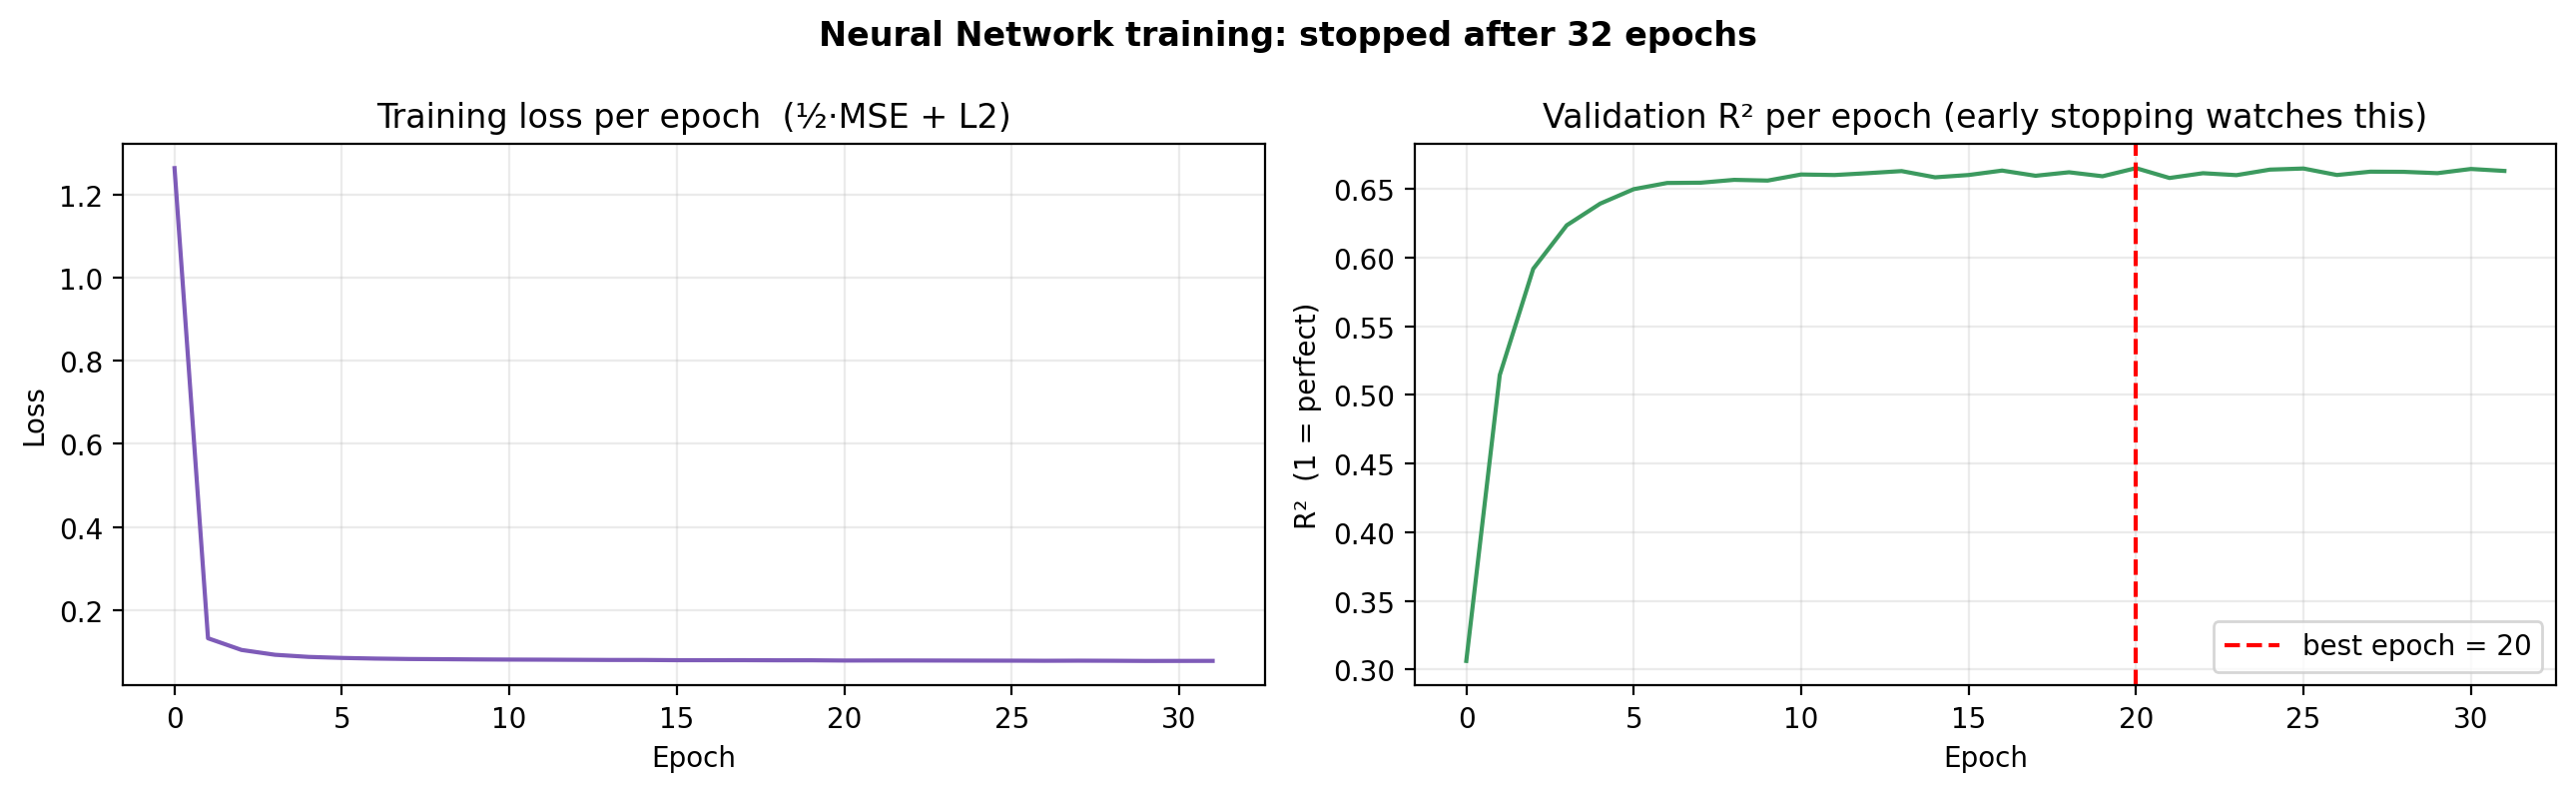

In [ ]:
# training curves: the loss on the training batches, and the R² on the held-out validation part
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(mlp.loss_curve_, color="#7E5BB8")
axes[0].set_title("Training loss per epoch  (½·MSE + L2)")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.25)

axes[1].plot(mlp.validation_scores_, color="#3C9A5F")
best_ep = int(np.argmax(mlp.validation_scores_))
axes[1].axvline(best_ep, color="r", linestyle="--", label=f"best epoch = {best_ep}")
axes[1].set_title("Validation R² per epoch (early stopping watches this)")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("R²  (1 = perfect)")
axes[1].legend(); axes[1].grid(alpha=0.25)
plt.suptitle(f"Neural Network training: stopped after {mlp.n_iter_} epochs", weight="bold")
plt.tight_layout()
plt.show()

---
## 7. Comparing the three algorithms

### 7.1 Performance metrics table
Best value in each column is highlighted in green; the bars inside the cells show the relative size.

In [ ]:
summary = pd.DataFrame(results).T
summary["Within ±0.5 (%)"] = [np.mean(np.abs(y_test - predictions[m]) <= 0.5) * 100 for m in summary.index]

base_mae = summary.loc["Baseline (mean)", "MAE"]
summary["MAE better than baseline (%)"] = (base_mae - summary["MAE"]) / base_mae * 100
summary = summary.sort_values("MAPE (%)")

error_cols = ["MAE", "MSE", "RMSE", "MAPE (%)"]
good_cols = ["Within ±0.5 (%)", "MAE better than baseline (%)"]

(summary.style
    .format("{:.4f}", subset=["MAE", "MSE", "RMSE"])
    .format("{:.2f}%", subset=["MAPE (%)"] + good_cols)
    .bar(subset=error_cols, color="#f4b6b6", vmin=0)
    .highlight_min(subset=error_cols, color="#9fe29f")
    .highlight_max(subset=good_cols, color="#9fe29f")
    .set_caption("Test-set performance (lower is better for MAE / MSE / RMSE / MAPE)")
)

,MAE,MSE,RMSE,MAPE (%),Within ±0.5 (%),MAE better than baseline (%)
Decision Tree,0.3066,0.1645,0.4055,8.77%,82.08%,41.13%
Neural Network,0.3055,0.1608,0.4009,8.80%,82.12%,41.34%
Linear Regression,0.3046,0.1618,0.4023,8.82%,82.00%,41.52%
Baseline (mean),0.5208,0.4979,0.7056,16.82%,54.88%,0.00%


### 7.1b How the three models learn – loss function and size

In [ ]:
model_names = ["Linear Regression", "Decision Tree", "Neural Network"]
tree = models["Decision Tree"]
mlp = models["Neural Network"][-1]
nn_params = sum(W.size + b.size for W, b in zip(mlp.coefs_, mlp.intercepts_))

model_info = pd.DataFrame({
    "Loss function": ["MSE = (1/n)·Σ(y − ŷ)²",
                      "squared error (MSE) per split",
                      "½·MSE + L2 penalty"],
    "How it is minimized": ["exact least-squares solution",
                            "greedy search for the best split",
                            "backpropagation + Adam (iterative)"],
    "Structure / layers": [f"1 layer: {X_train.shape[1]} inputs → 1 output",
                           f"{tree.get_depth()} levels, {tree.get_n_leaves()} leaves",
                           " → ".join(map(str, [X_train.shape[1], *mlp.hidden_layer_sizes, 1]))],
    "Learned numbers": [X_train.shape[1] + 1,
                        f"{tree.tree_.node_count} nodes (thresholds + leaf values)",
                        f"{nn_params:,} weights + biases"],
    "Test MAE": [results[m]["MAE"] for m in model_names],
    "Test MAPE (%)": [results[m]["MAPE (%)"] for m in model_names],
}, index=model_names)

model_info.style.format({"Test MAE": "{:.4f}", "Test MAPE (%)": "{:.2f}%"}).set_caption(
    "Loss function, structure and size of each algorithm")

,Loss function,How it is minimized,Structure / layers,Learned numbers,Test MAE,Test MAPE (%)
Linear Regression,MSE = (1/n)·Σ(y − ŷ)²,exact least-squares solution,1 layer: 26 inputs → 1 output,27,0.3046,8.82%
Decision Tree,squared error (MSE) per split,greedy search for the best split,"10 levels, 463 leaves",925 nodes (thresholds + leaf values),0.3066,8.77%
Neural Network,½·MSE + L2 penalty,backpropagation + Adam (iterative),26 → 64 → 32 → 1,"3,841 weights + biases",0.3055,8.80%


### 7.2 Metrics side by side

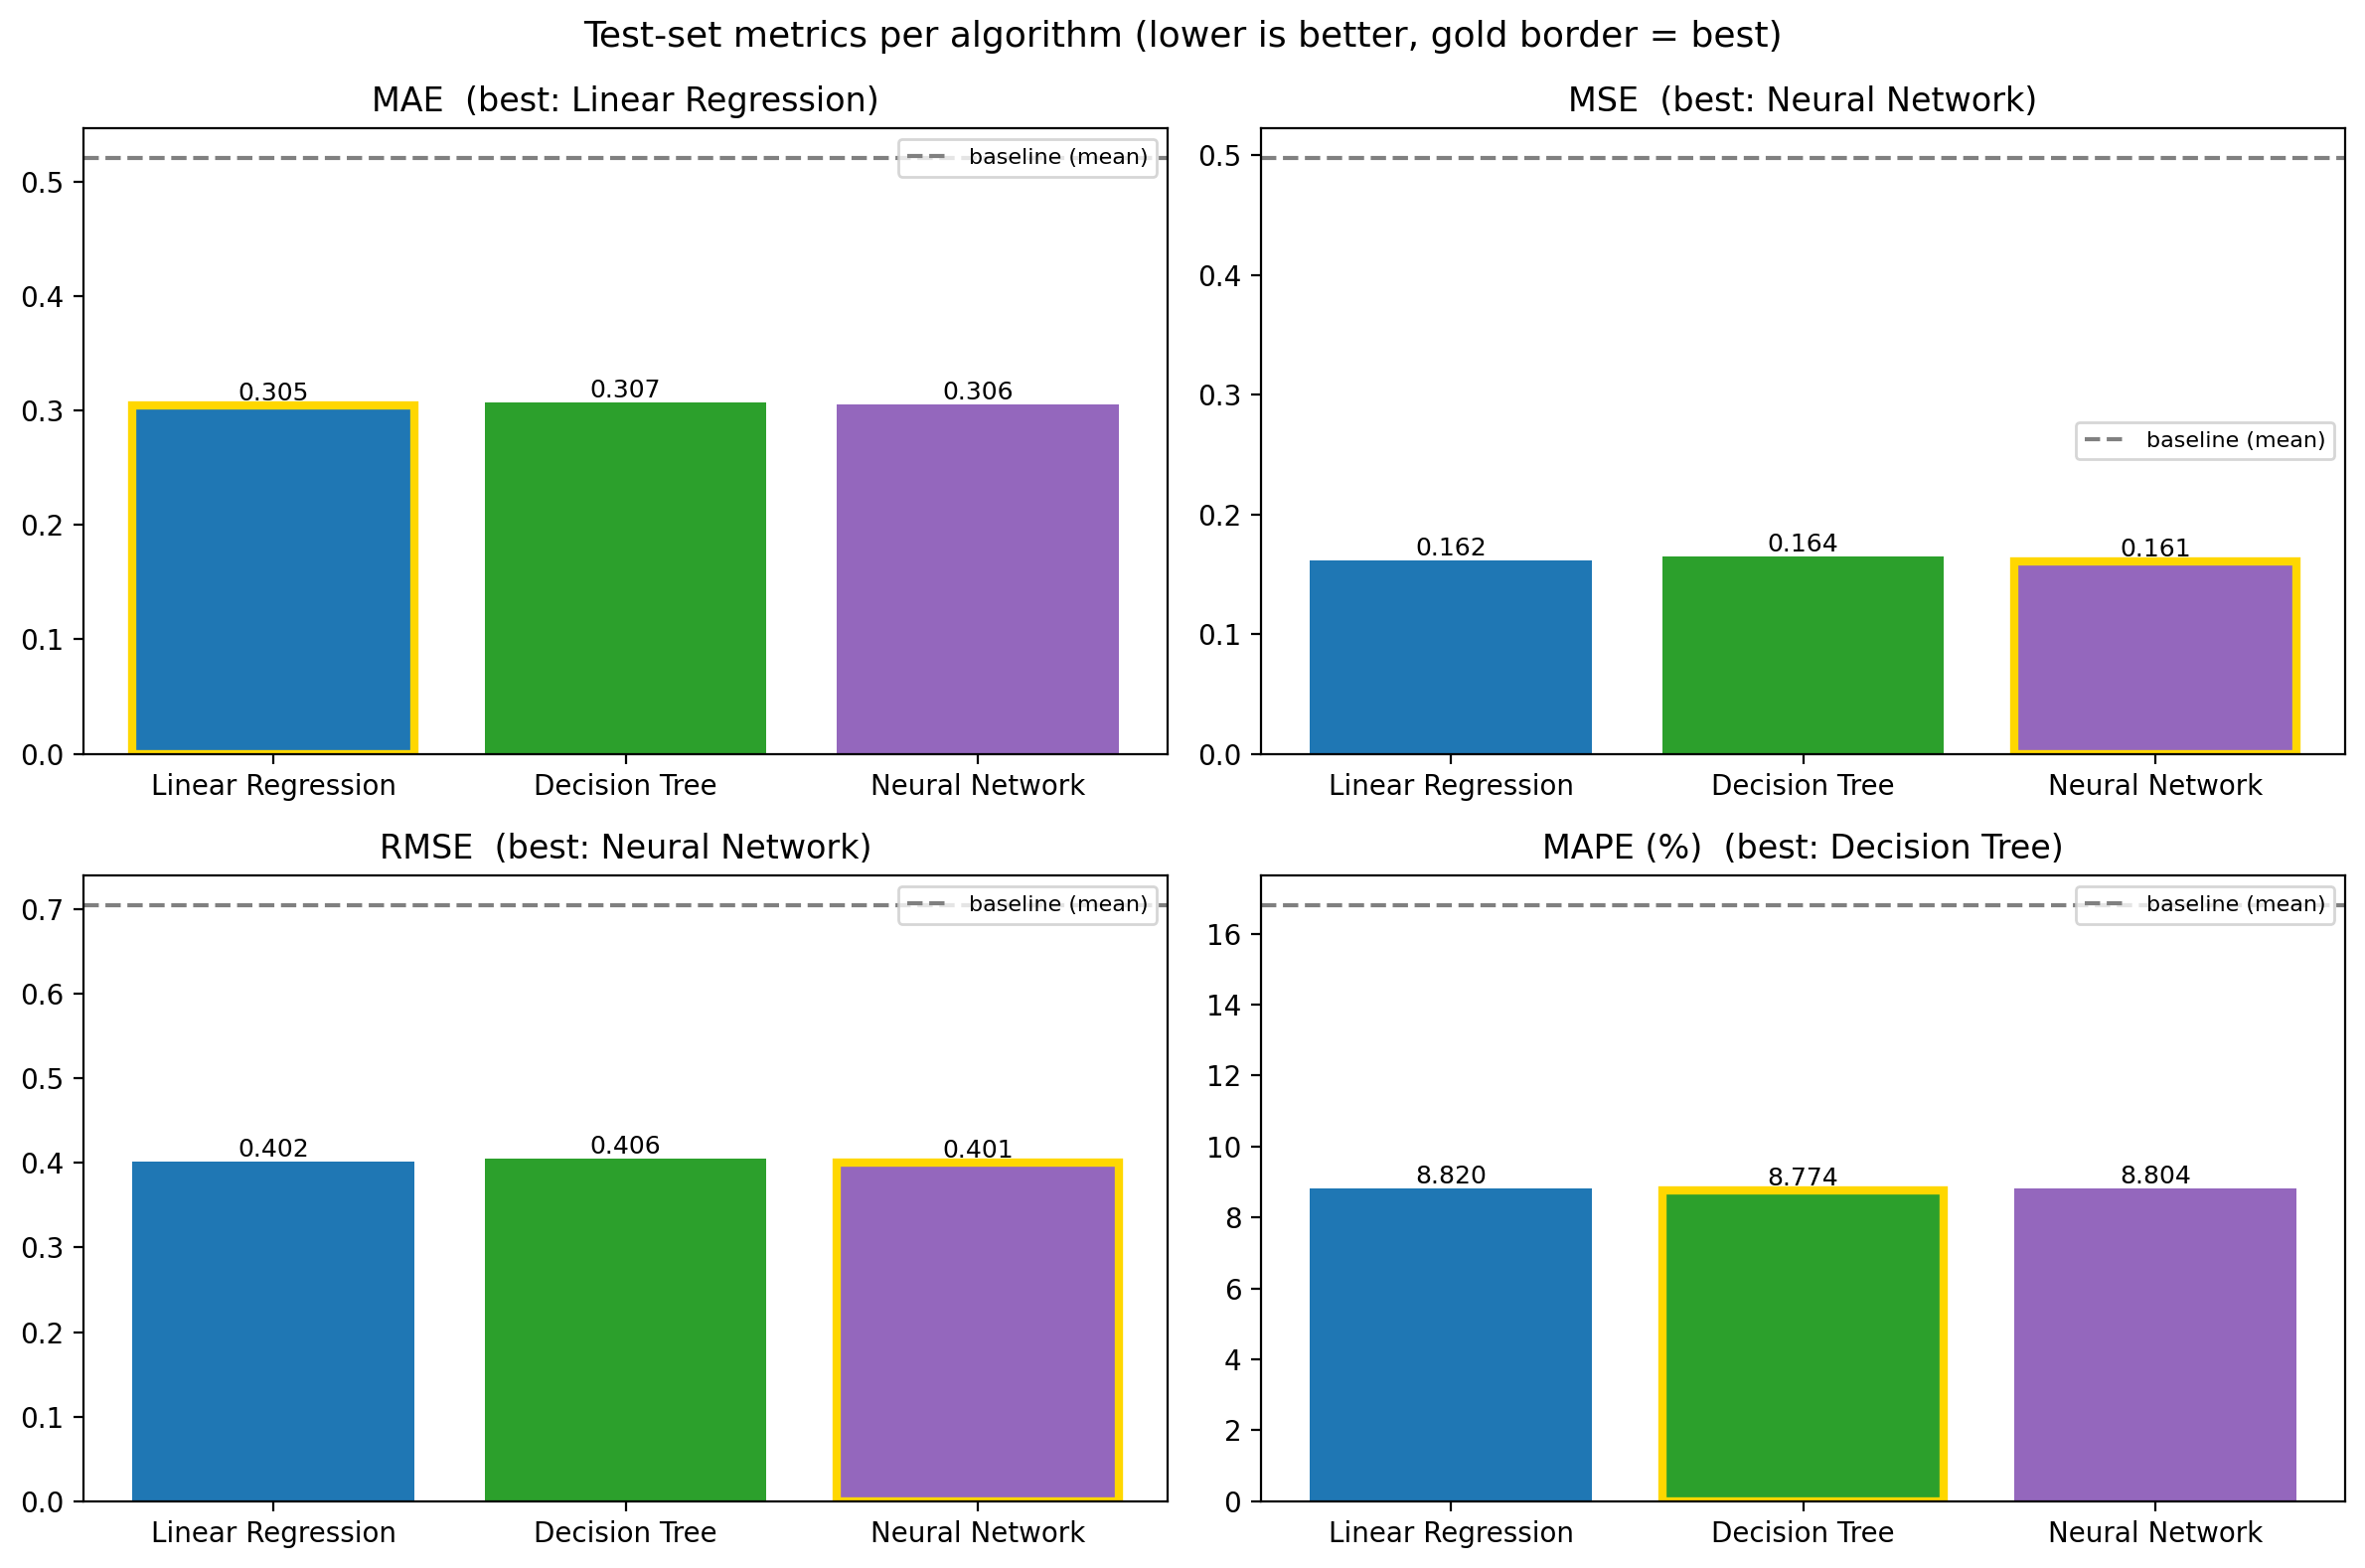

In [ ]:
model_names = ["Linear Regression", "Decision Tree", "Neural Network"]
colors = {"Linear Regression": "tab:blue", "Decision Tree": "tab:green", "Neural Network": "tab:purple"}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, metric in zip(axes.ravel(), error_cols):
    vals = summary.loc[model_names, metric]
    bars = ax.bar(model_names, vals, color=[colors[m] for m in model_names])
    best = vals.idxmin()
    bars[model_names.index(best)].set_edgecolor("gold")
    bars[model_names.index(best)].set_linewidth(3)
    ax.axhline(summary.loc["Baseline (mean)", metric], color="gray", linestyle="--", label="baseline (mean)")
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(f"{metric}  (best: {best})")
    ax.legend(fontsize=8)
plt.suptitle("Test-set metrics per algorithm (lower is better, gold border = best)", fontsize=13)
plt.tight_layout()
plt.show()

### 7.3 Actual vs predicted – the same 15 test reviews
For every review, the prediction closest to the actual rating is highlighted.

In [ ]:
n = 15
compare = pd.DataFrame({"Actual": y_test[:n]})
for m in model_names:
    compare[m] = np.round(predictions[m][:n], 2)

def highlight_closest(row):
    errs = (row[model_names] - row["Actual"]).abs()
    return ["background-color: #9fe29f" if (c in model_names and errs[c] == errs.min()) else "" for c in row.index]

compare.style.apply(highlight_closest, axis=1).format("{:.2f}")

,Actual,Linear Regression,Decision Tree,Neural Network
0,4.00,4.50,4.48,4.51
1,3.00,3.27,3.22,3.21
2,4.00,4.08,4.06,4.14
3,3.50,3.38,3.44,3.43
4,3.00,3.36,3.46,3.34
5,5.00,4.30,4.10,4.21
6,3.00,3.65,3.67,3.66
7,5.00,4.71,4.59,4.70
8,3.00,3.35,3.46,3.21
9,4.00,4.20,4.15,4.20


### 7.4 Predicted vs actual for all reviews

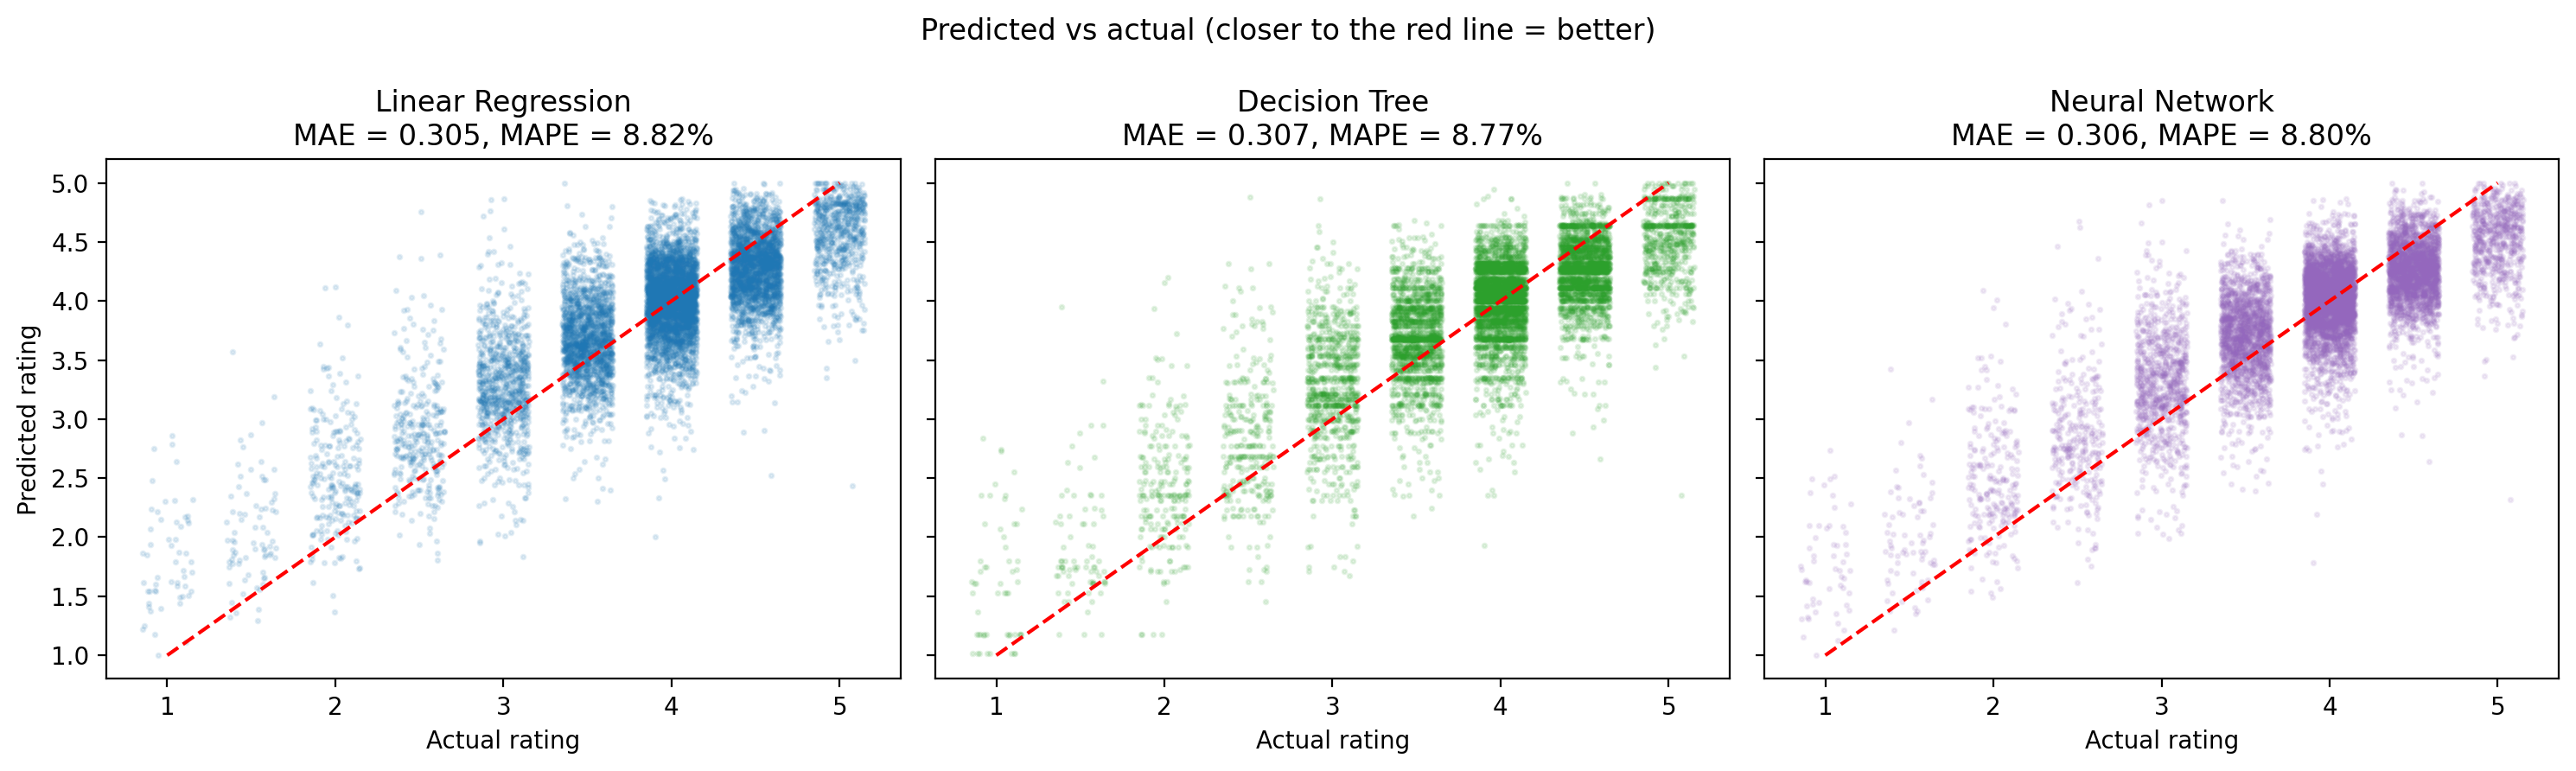

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
jitter = np.random.default_rng(0).uniform(-0.15, 0.15, len(y_test))
for ax, m in zip(axes, model_names):
    ax.scatter(y_test + jitter, predictions[m], s=3, alpha=0.12, color=colors[m])
    ax.plot([1, 5], [1, 5], "r--")
    ax.set_title(f"{m}\nMAE = {summary.loc[m, 'MAE']:.3f}, MAPE = {summary.loc[m, 'MAPE (%)']:.2f}%")
    ax.set_xlabel("Actual rating")
axes[0].set_ylabel("Predicted rating")
plt.suptitle("Predicted vs actual (closer to the red line = better)")
plt.tight_layout()
plt.show()

### 7.5 Average prediction for each actual rating
For each true rating level, what does each model predict on average? A perfect model follows the dashed line.

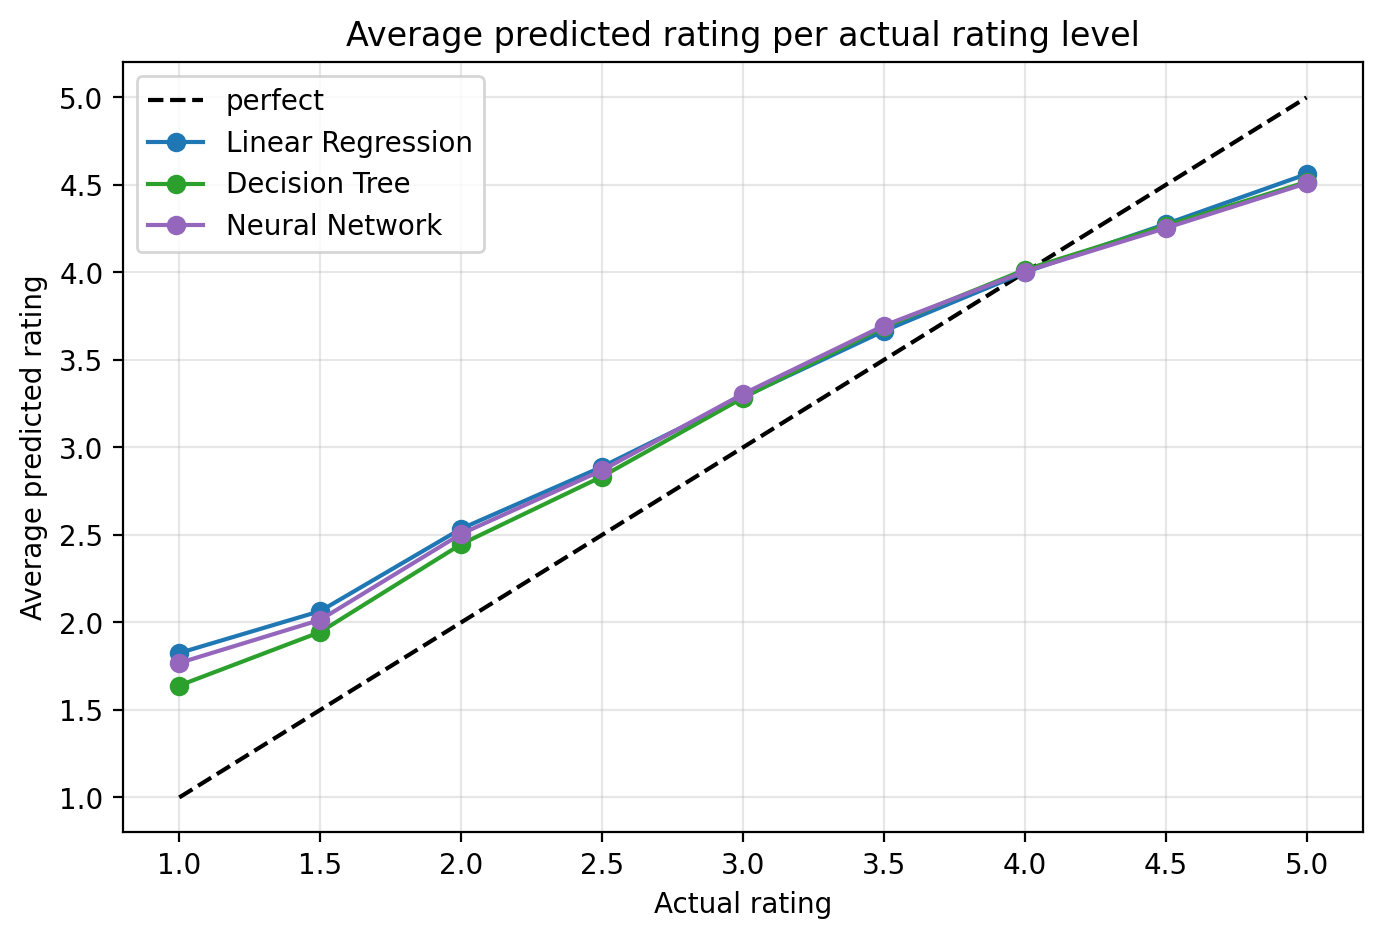

In [ ]:
levels = np.sort(np.unique(y_test))
plt.figure(figsize=(8, 5))
plt.plot(levels, levels, "k--", label="perfect")
for m in model_names:
    avg = [predictions[m][y_test == lv].mean() for lv in levels]
    plt.plot(levels, avg, "o-", color=colors[m], label=m)
plt.xlabel("Actual rating")
plt.ylabel("Average predicted rating")
plt.title("Average predicted rating per actual rating level")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 7.6 Error distribution

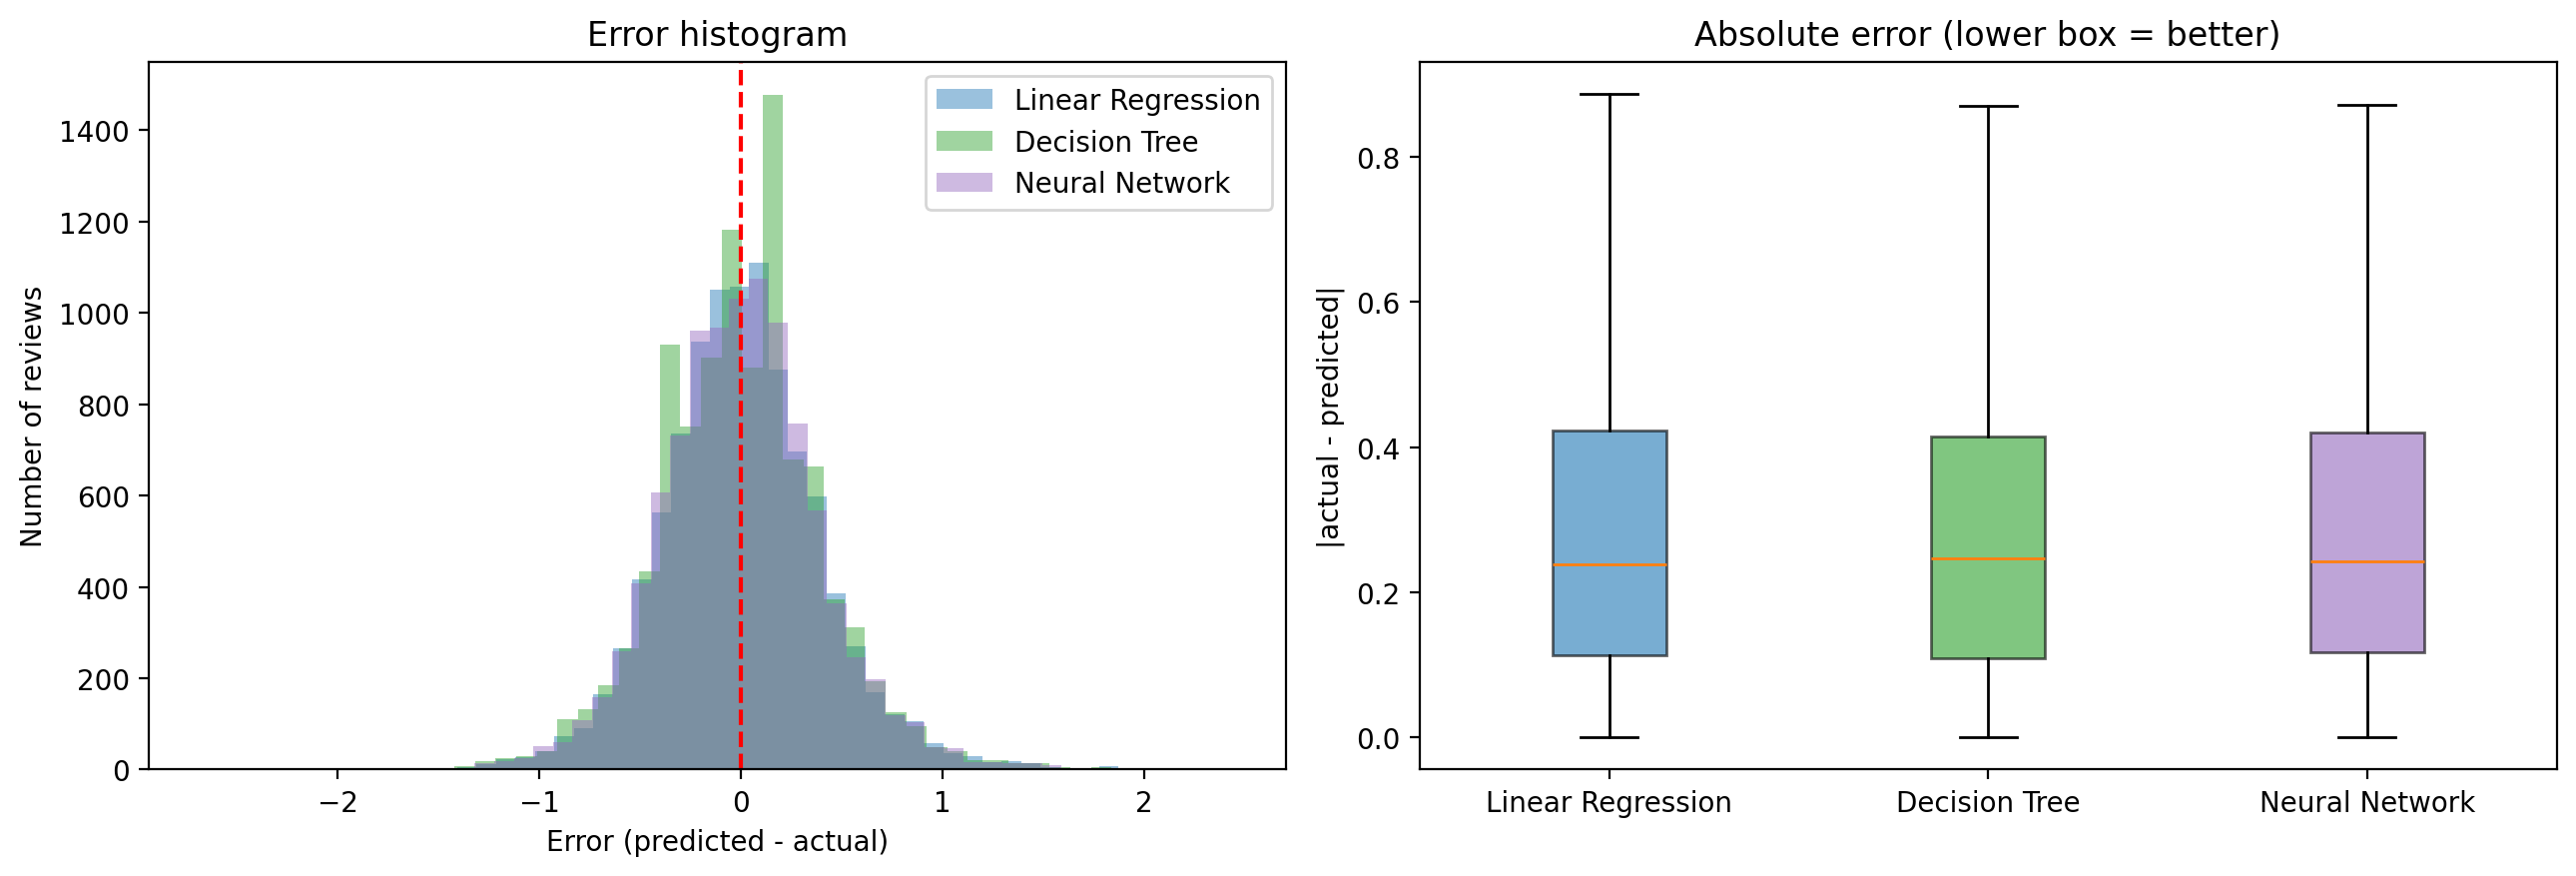

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

errs = pd.DataFrame({m: predictions[m] - y_test for m in model_names})
for m in model_names:
    axes[0].hist(errs[m], bins=50, alpha=0.45, label=m, color=colors[m])
axes[0].axvline(0, color="r", linestyle="--")
axes[0].set_xlabel("Error (predicted - actual)")
axes[0].set_ylabel("Number of reviews")
axes[0].set_title("Error histogram")
axes[0].legend()

box = axes[1].boxplot([errs[m].abs() for m in model_names], showfliers=False, patch_artist=True)
axes[1].set_xticks(range(1, len(model_names) + 1), model_names)
for patch, m in zip(box["boxes"], model_names):
    patch.set_facecolor(colors[m])
    patch.set_alpha(0.6)
axes[1].set_ylabel("|actual - predicted|")
axes[1].set_title("Absolute error (lower box = better)")

plt.tight_layout()
plt.show()

---
## 8. Repeat with 5 different random splits

One split can be lucky or unlucky, so we train all three algorithms on 5 different 80/20 splits and report the **mean ± std**
of each metric, plus the best run.

In [ ]:
runs = []
for seed in range(5):
    X_tr, X_te, y_tr, y_te = split_and_fill(X, y, seed)
    for m in model_names:
        model = clone(models[m])   # fresh, untrained copy with the same settings
        model.fit(X_tr, y_tr)
        p = np.clip(model.predict(X_te), 1, 5)
        runs.append({"Model": m, "Seed": seed, **evaluate(y_te, p)})
    print(f"split {seed} done")

runs_df = pd.DataFrame(runs)

mean = runs_df.groupby("Model")[error_cols].mean()
std = runs_df.groupby("Model")[error_cols].std()
mean_std = mean.round(4).astype(str) + " ± " + std.round(4).astype(str)
mean_std = mean_std.loc[mean["MAPE (%)"].sort_values().index]
print("\nMean ± std over 5 random splits:")
display(mean_std)

best_runs = runs_df.loc[runs_df.groupby("Model")["MAPE (%)"].idxmin()].set_index("Model").drop(columns="Seed")
print("Best single run per model:")
display(best_runs.round(4).sort_values("MAPE (%)"))

split 0 done
split 1 done
split 2 done
split 3 done
split 4 done

Mean ± std over 5 random splits:


,MAE,MSE,RMSE,MAPE (%)
Model,,,,
Neural Network,0.3028 ± 0.0009,0.1584 ± 0.002,0.3979 ± 0.0025,8.5848 ± 0.0649
Linear Regression,0.3034 ± 0.0014,0.1591 ± 0.0024,0.3989 ± 0.003,8.6844 ± 0.0749
Decision Tree,0.307 ± 0.0012,0.1634 ± 0.0019,0.4042 ± 0.0024,8.7234 ± 0.0502


Best single run per model:


,MAE,MSE,RMSE,MAPE (%)
Model,,,,
Neural Network,0.3016,0.1555,0.3943,8.5012
Linear Regression,0.3015,0.1552,0.3940,8.5674
Decision Tree,0.3052,0.1623,0.4029,8.6710


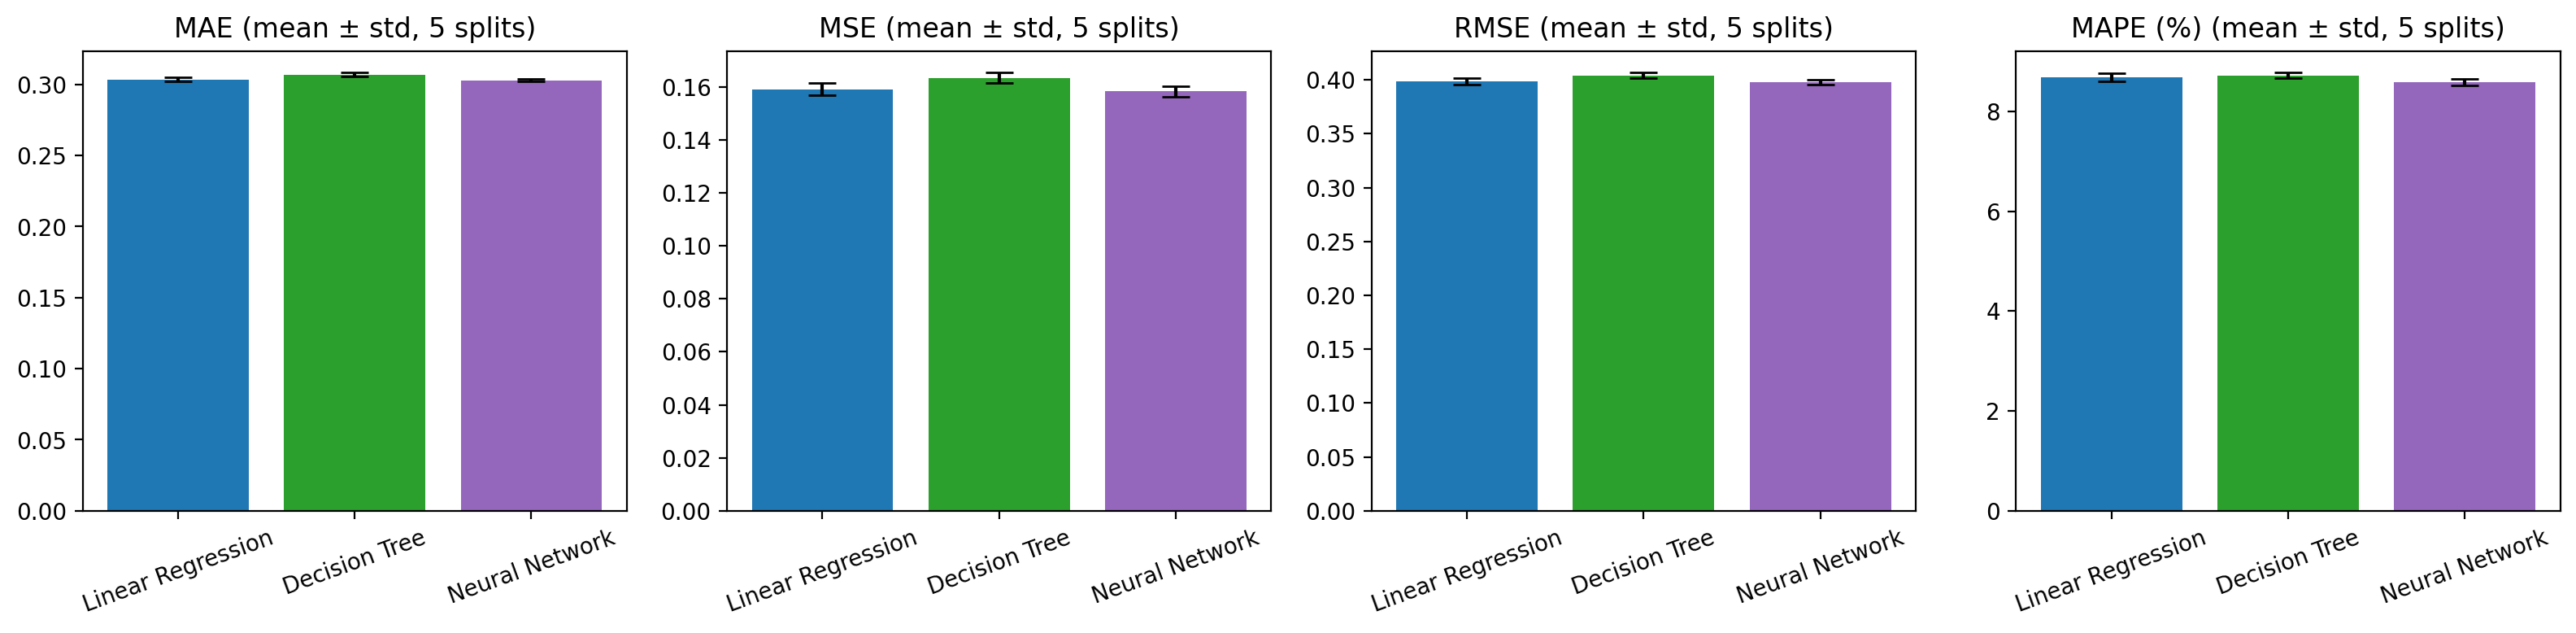

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, metric in zip(axes, error_cols):
    data = [runs_df.loc[runs_df["Model"] == m, metric] for m in model_names]
    ax.bar(model_names, [d.mean() for d in data], yerr=[d.std() for d in data], capsize=6,
           color=[colors[m] for m in model_names])
    ax.set_title(f"{metric} (mean ± std, 5 splits)")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

---
## 9. (Extra) Only beer + user features

The sub-scores (taste, aroma, palate, appearance) come from the same review, so they make the task much easier.
Here we train all three algorithms **without** them, using only ABV, style, age, gender, year and review length.

In [ ]:
X_small = X.drop(columns=["aroma", "appearance", "palate", "taste"])
X_tr, X_te, y_tr, y_te = split_and_fill(X_small, y, seed=42)

small_results = {"Baseline (mean)": evaluate(y_te, np.full(len(y_te), y_tr.mean()))}
for m in model_names:
    model = clone(models[m]).fit(X_tr, y_tr)
    small_results[m] = evaluate(y_te, np.clip(model.predict(X_te), 1, 5))

small_df = pd.DataFrame(small_results).T.sort_values("MAPE (%)")
(small_df.style
    .format("{:.4f}", subset=["MAE", "MSE", "RMSE"])
    .format("{:.2f}%", subset=["MAPE (%)"])
    .highlight_min(color="#9fe29f")
    .set_caption("Without the review sub-scores"))

,MAE,MSE,RMSE,MAPE (%)
Decision Tree,0.4833,0.4245,0.6515,15.38%
Neural Network,0.4897,0.4322,0.6575,15.65%
Linear Regression,0.4956,0.4422,0.6650,15.90%
Baseline (mean),0.5208,0.4979,0.7056,16.82%


---
## 10. Final summary

In [ ]:
ranked = summary.loc[model_names].sort_values("MAPE (%)")
best = ranked.index[0]

print("FINAL RANKING (test set, split seed 42, sorted by MAPE)")
print("-" * 78)
print(f"{'Rank':<6}{'Model':<20}{'MAE':>9}{'MSE':>9}{'RMSE':>9}{'MAPE':>10}{'within ±0.5':>14}")
for r, (m, row) in enumerate(ranked.iterrows(), start=1):
    print(f"{r:<6}{m:<20}{row['MAE']:>9.4f}{row['MSE']:>9.4f}{row['RMSE']:>9.4f}"
          f"{row['MAPE (%)']:>9.2f}%{row['Within ±0.5 (%)']:>13.1f}%")
b = summary.loc["Baseline (mean)"]
print(f"{'-':<6}{'Baseline (mean)':<20}{b['MAE']:>9.4f}{b['MSE']:>9.4f}{b['RMSE']:>9.4f}"
      f"{b['MAPE (%)']:>9.2f}%{b['Within ±0.5 (%)']:>13.1f}%")
print("-" * 78)
print(f"Best algorithm: {best}")
print(f"Best MAPE over 5 random splits: {runs_df.loc[runs_df['Model'] == best, 'MAPE (%)'].min():.2f}%")

FINAL RANKING (test set, split seed 42, sorted by MAPE)
------------------------------------------------------------------------------
Rank  Model                     MAE      MSE     RMSE      MAPE   within ±0.5
1     Decision Tree          0.3066   0.1645   0.4055     8.77%         82.1%
2     Neural Network         0.3055   0.1608   0.4009     8.80%         82.1%
3     Linear Regression      0.3046   0.1618   0.4023     8.82%         82.0%
-     Baseline (mean)        0.5208   0.4979   0.7056    16.82%         54.9%
------------------------------------------------------------------------------
Best algorithm: Decision Tree
Best MAPE over 5 random splits: 8.67%
